<div><center><img src="https://docencia.ucv.ai/_images/DL26.png\" width=150"/> </center></div>

# 01 - A Fundamentos de Redes Neuronales

## Objetivo
Construir desde cero la intuición y la mecánica básica de una red neuronal poco profunda, y verificar empíricamente la diferencia entre profundidad y anchura.

## Contenido
1. Aprendizaje supervisado y descenso del gradiente
2. McCulloch-Pitts → Perceptron → red poco profunda
3. ReLU y reconstrucción visual de una red
4. Teorema de Aproximación Universal (UAT)
5. PyTorch básico: tensores, `nn.Linear`, `nn.Sequential`
6. **Experimento empírico:** profundidad vs. anchura sobre una superficie 2D ruidosa

## Notebooks de la serie
- **1A — Fundamentos**
- 1B — Activaciones, composición y `autograd`
- 1C — Entrenamiento, optimización y generalización


# 1 Introducción a Redes Neuronales con PyTorch

- Definiciones básicas de PyTorch
- Representación de arquitecturas básicas

## Versión v.3

- Versión 28/02/2025
    - Mejorados ejemplos de cálculos
- Versión 19/02/2025

    - Conceptos básicos de Redes neuronales
    - Redes neuronales en PyTorch
    - Estructurado: Ejemplo clase
    - Functiones custom
    - Ver Red

- Versión 24/07/2024
    - Agregadas mini tareas de numpy con códigos con errores.

El notebook lo puedo modificar, esta versión es la v.3 a 24/07/2024 a las 2pm de Caracas.

## Aprendizaje Automático [UCV]


* Autor: Fernando Crema García
* Contacto: fernando.cremagarcia@kuleuven.be; fernando.cremagarcia@esat.kuleuven.be

---

# code

In [ ]:
# Función para cargar SVG's basados en https://udlbook.github.io/udlbook/

from IPython.display import SVG, display

def show_svg(img):
  display(SVG(url=f'https://raw.githubusercontent.com/ucvia/ml-site/gh-pages/static/Chap03/{img}.svg'))

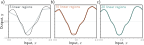

In [ ]:
show_svg('ShallowApproximate')

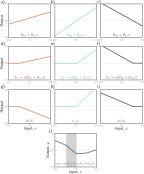

In [ ]:
show_svg('ShallowBuildUp')

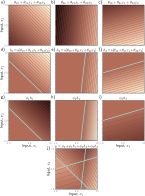

In [ ]:
show_svg('ShallowBuildUp2D')

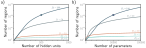

In [ ]:
show_svg('ShallowRegions')

# Introducción


## Aprendizaje supervisado: hasta ahora

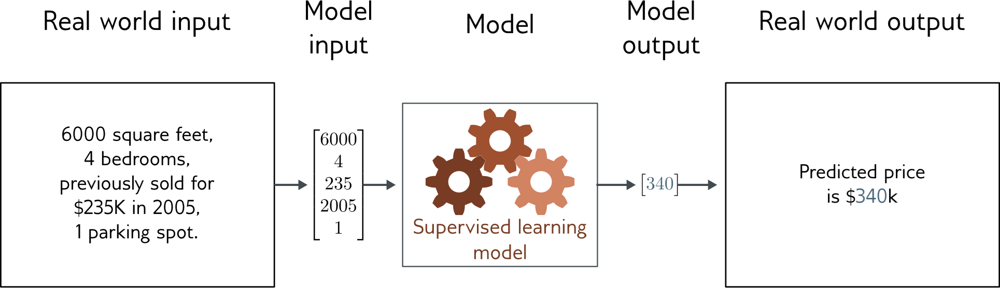

### Regresión

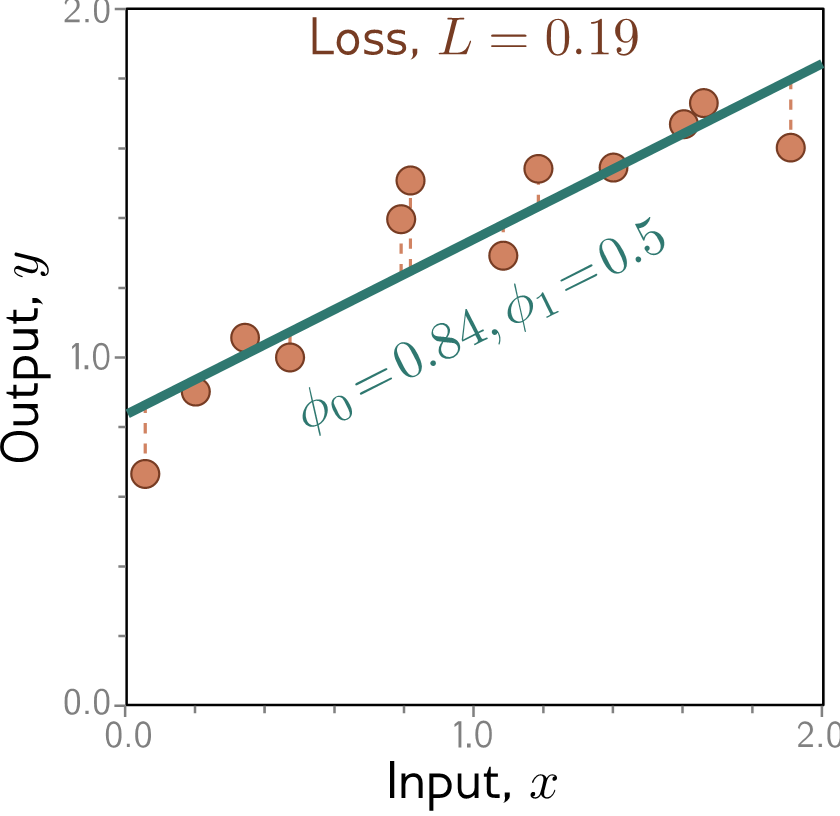

### Método del descenso del gradiente

A veces es complicado obtener la solución analítica

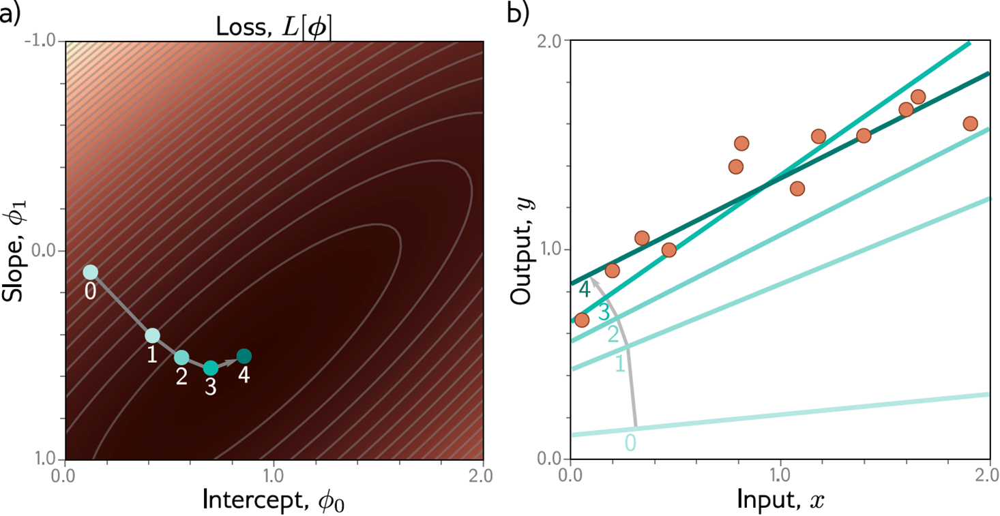

# Redes neuronales poco profundas

El modelo de regresión es obviamente limitado
  - Desea poder describir entradas/salidas que no necesariamente tengan una relación lineal
  - Deseamos múltiples entradas (regresión lineal con múltiples dimensiones)
  - Deseamos varias salidas (complicado)

Qué queremos?
  - Suficientemente flexible para describir asignaciones de entrada/salida arbitrariamente complejas.
  - Podemos tener tantas entradas como queramos
  - Podemos tener tantas salidas como queramos


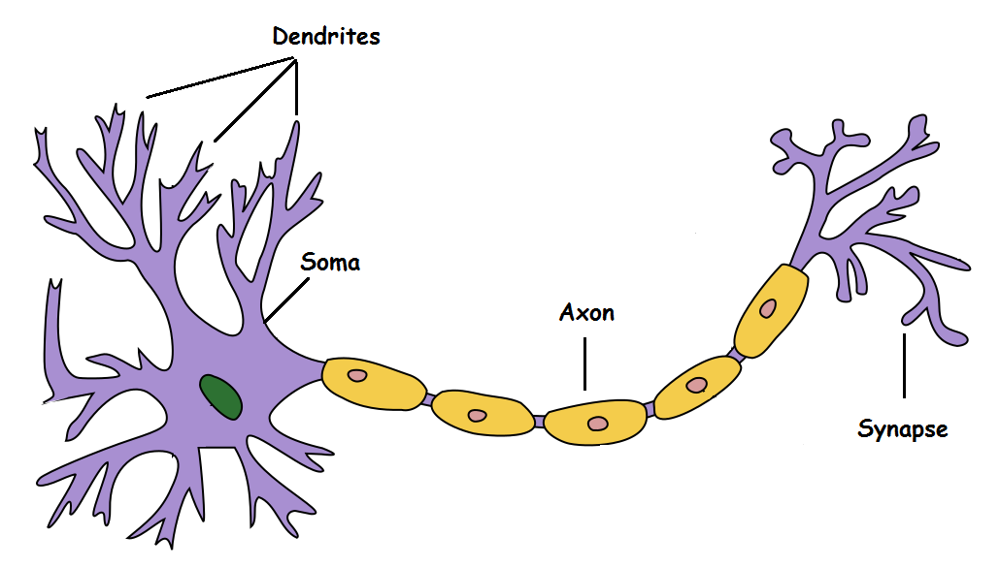

## Modelo McCulloch-Pitts (1943)

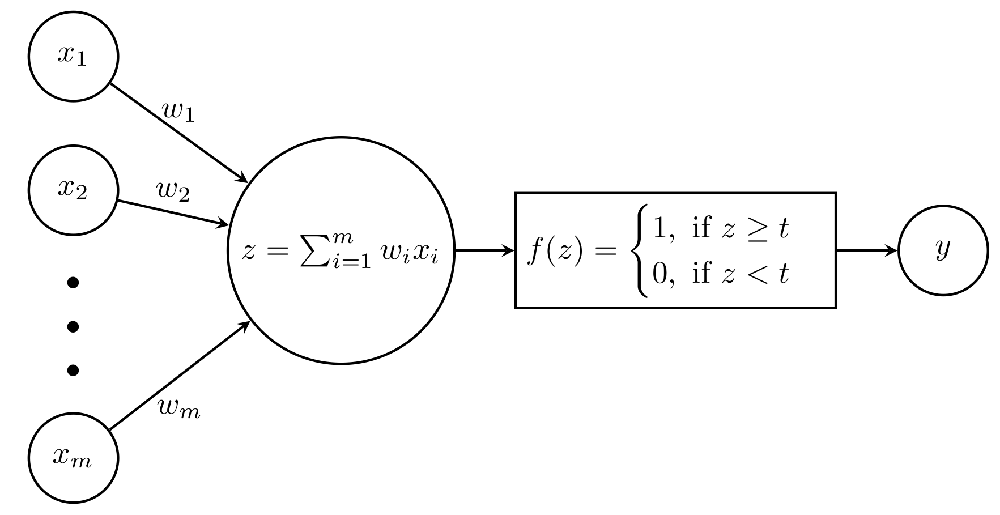

$$
y=f\left(\sum_i w_i x_i+b\right) .
$$

1. $x$ señal de entrada con $x \in \mathbb{R}^{m}$
1. $x_i$ es la $i$-ésima entrada de $x$ siempre que $i \in \left\{1, m\right\}$
1. $z$ se denomina **activación**
1. $w$ es el vector de **interconexión**
1. $f$ es una función **no lineal** denominada **de activación**
1. $f$ en nuestro ejemplo es la función $step$
1. Es bastante fácil agregar un término de bias $b$
!. $y$ es la salida del modelo.

## En notación vectorial es posible?

$$y = f(w^T x + b)$$

## Qué pensaron en los años 50?

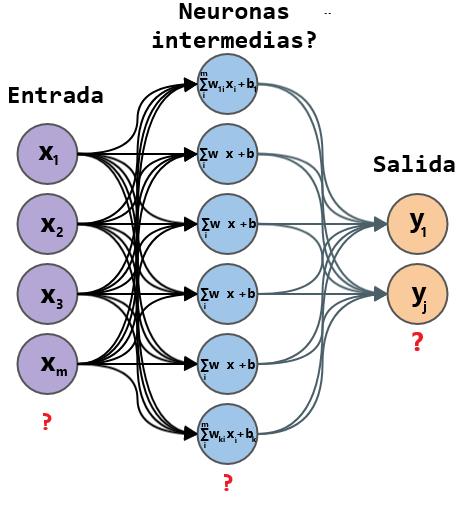

## Learning by example: Red poco profunda

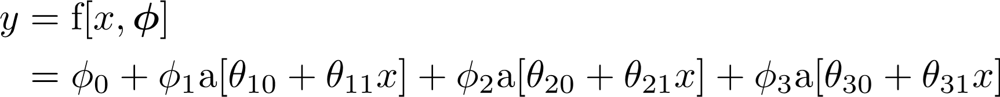

Dónde tenemos que Unidad lineal rectificada (ReLU)

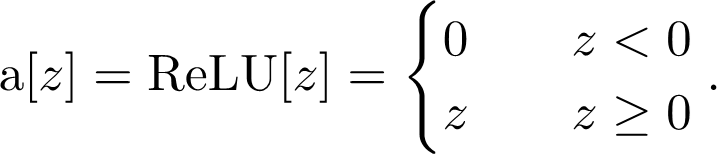

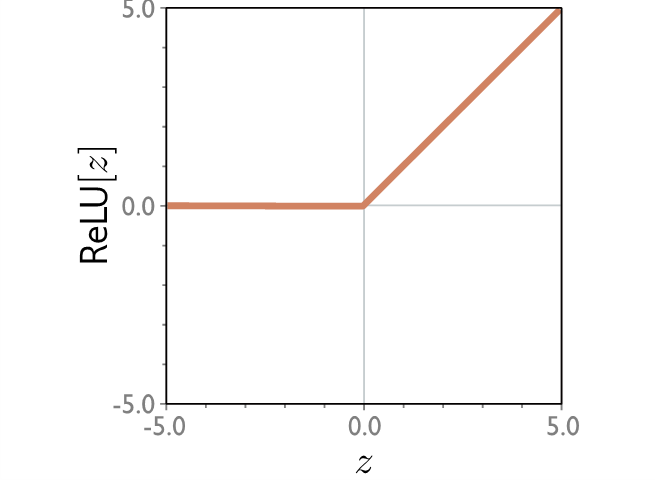

### Parámetros

Cuántos parámetros tenemos ahora?

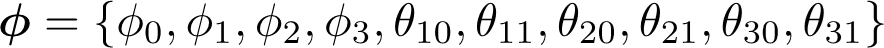


## Familia de funciones

Cuando definimos (le damos un nombre) a la función $a$ trae como consecuencia que:

- Representamos una familia de funciones
- Los parámetros (luego de optimizarlos) determinan una función concreta
- Dados los parámetros se puede realizar la inferencia (ejecutar la ecuación)

Qué necesitaríamos?
- Conjunto de datos de entrenamiento
- Definir la función de pérdida (podemos todavía hacer mínimos cuadrados)
- Cambiar los parámetros para minimizar la función de pérdida


## Representación visual

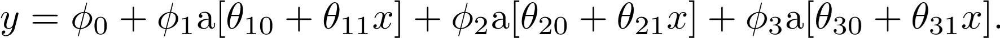

Usando ReLU simplemente estamos representando funciones lineales a trozos con tres articulaciones.


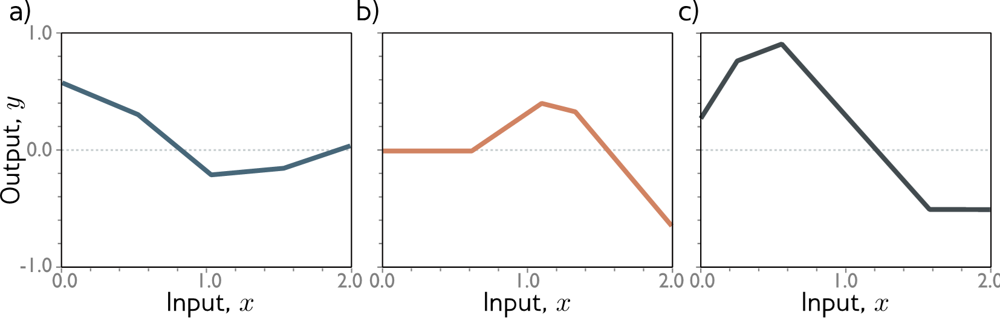

## Componentes de una red neuronal poco profunda


### Capa oculta

Podemos redefinir la red

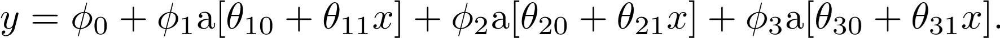

Como

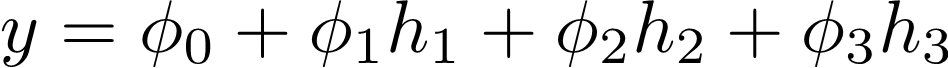

De donde juntas cada $h_i$ son conocidas como "capa oculta"

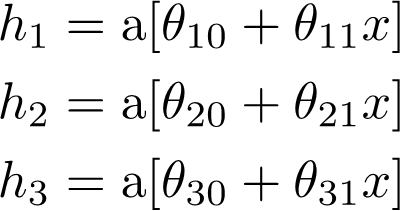

### Función de activación

Es la función $a$ que es aplicada luego de obtener los valores de $\theta_{i0} + \theta_{i1} x$. Existen muchos tipos de funciones de activación

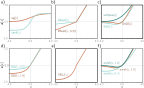

In [ ]:
show_svg('ShallowActivations')

### Neuronas

Son las unidades de nuestra red que representan tanto las entradas $x$ como las salidas $y$.

Además, cada componente de la cada oculta $h_i$ también puede ser considerada una neurona

## Reconstrucción visual de una red neuronal

### 1. Calculamos tres funciones lineales

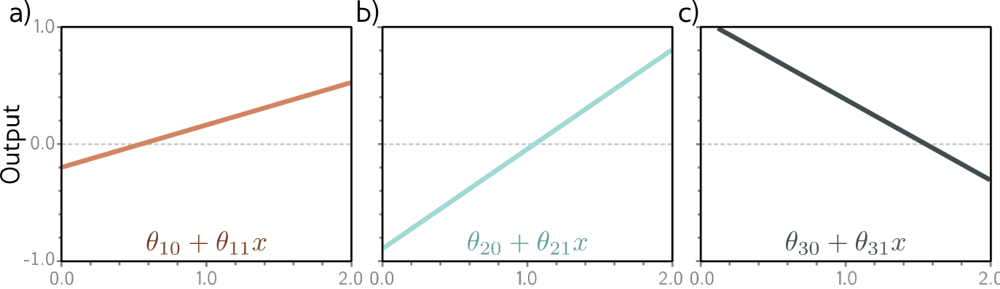

### 2. Ponderamos usando la función de activación

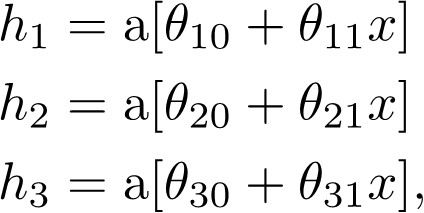

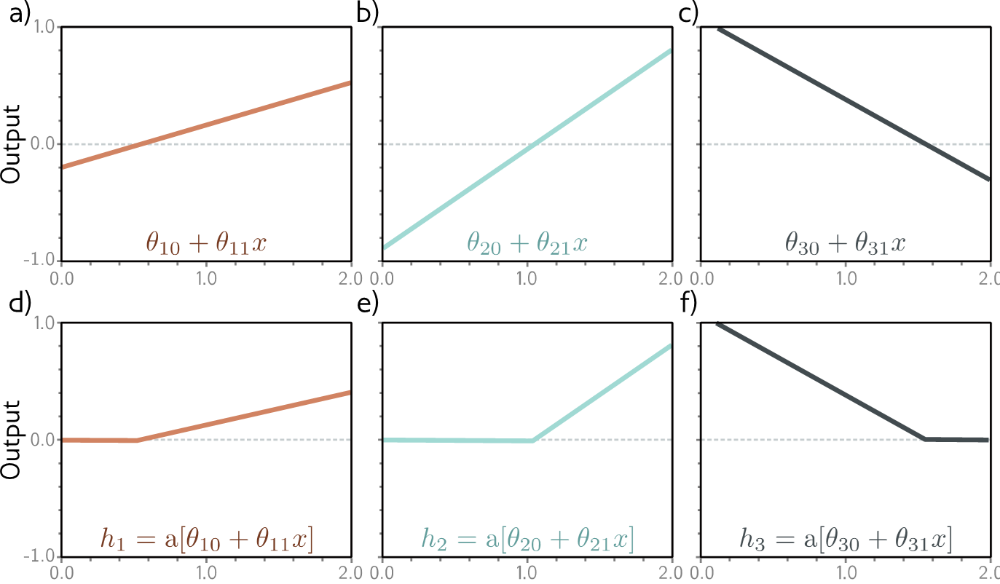

### 3. Multiplicamos cada neurona por su coeficiente

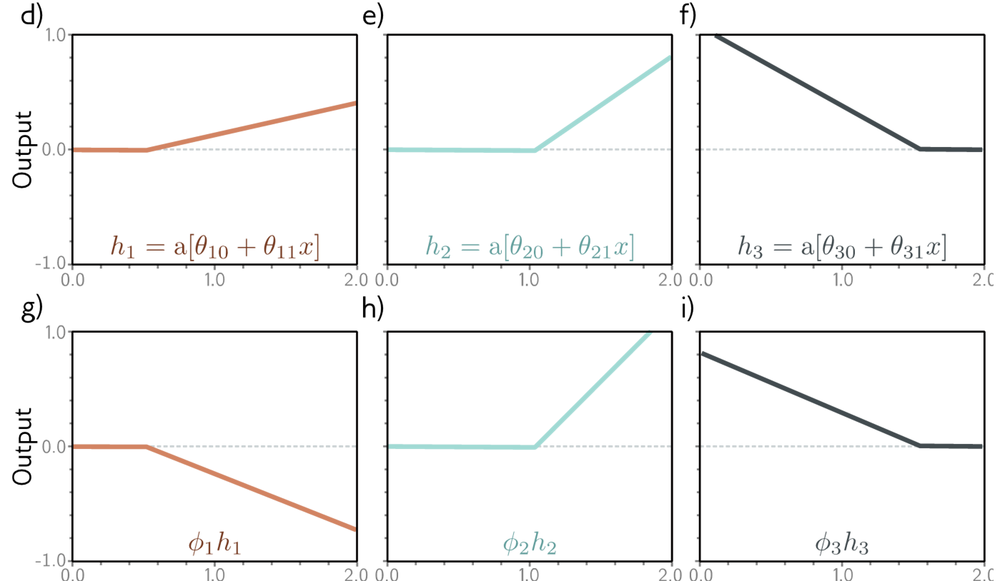

### 4. Aplicamos una combinación lineal de cada neurona




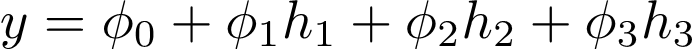

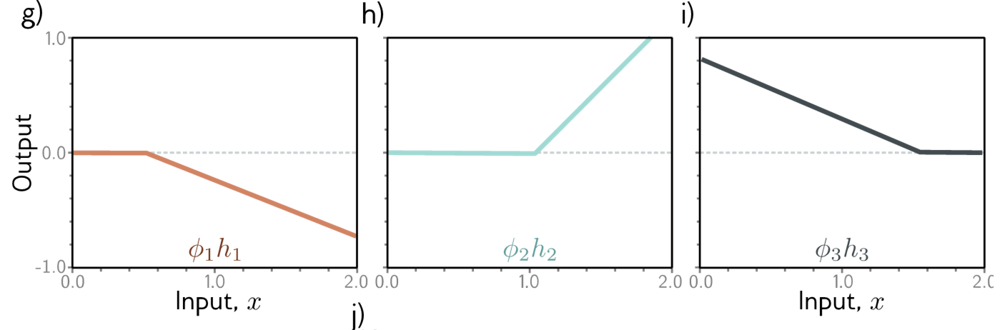

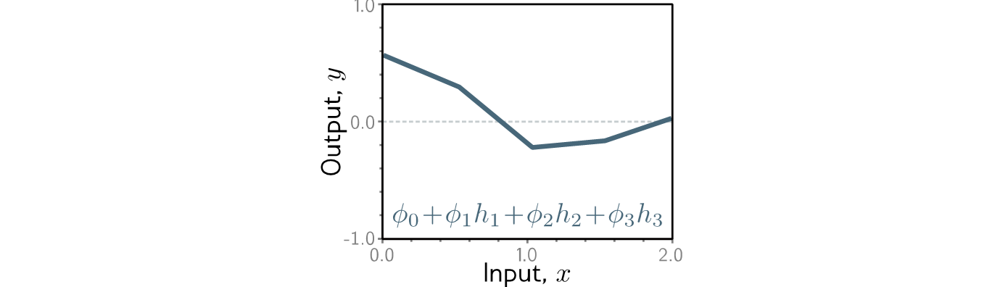

Fíjense que estamos reconstruyendo funciones a partir de combinaciones lineales de funciones de activación evaluadas en líneas.

### Analizando regiones sombreadas

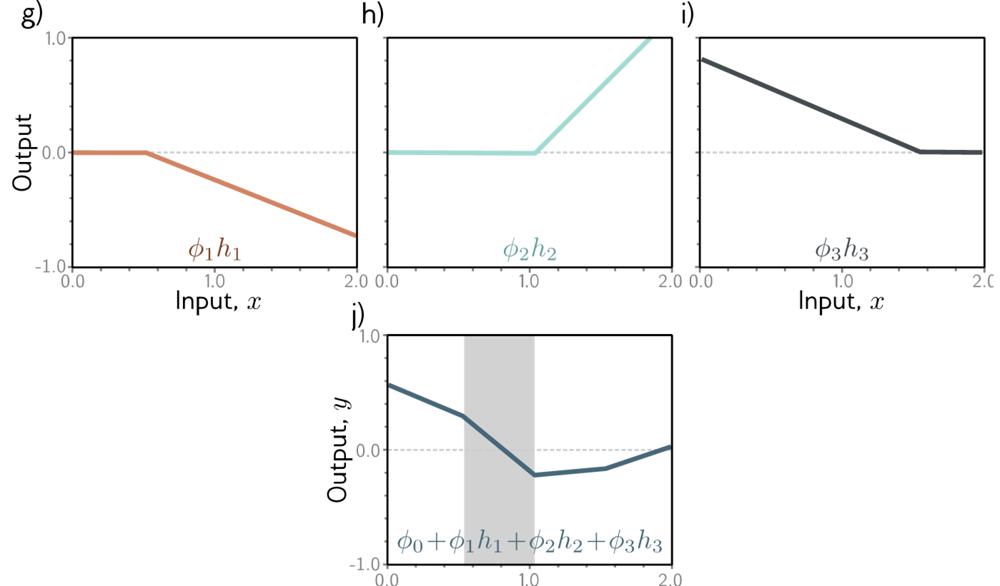

Fíjense cómo en la región sombreada:
1. Neurona 1 activa
1. Neurona 2 inactiva
1. Neurona 3 activa

Aún siendo un ejemplo bastante básico, es el principio del concepto de interpretabilidad en redes neuronales: analizar en ciertas zonas de la red cuándo ciertas neuronas están, o no, activadas.


## Representación visual de una red neuronal

Por ahora entendemos que estamos representando funciones pero cómo podemos representar, visualmente, la red neuronal?

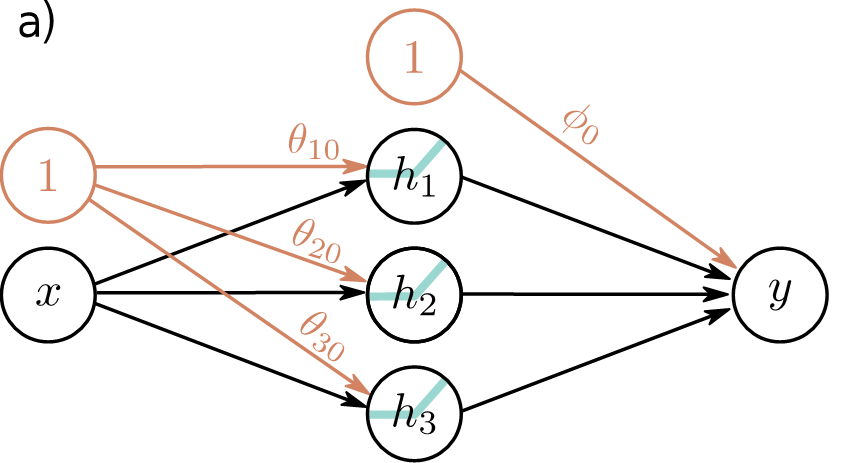

### Cómo leer esto?

1. Cada flecha representa **coeficientes** de nuestro modelo.
1. Cada $neurona$ es representada por una circunferencia. Dentro de la neurona, tenemos las $variables$ asociadas.
    - Si la neurona está a la izquierda es la representación de la **entrada** $x$
    - Si la neurona está a la derecha es la **salida** $y$
    - Si la neurona es interna representamos las **neuronas ocultas** por cada **capa oculta**
1. Toda neurona multiplica a su coeficiente.
1. Toda neurona suma las flechas de entradas que van hacia ella.
1. En resumen: Cada parámetro multiplica su fuente y se suma a su objetivo
1. Para agregar el **sesgo** de cada función lineal, basta con agregar 1 unidad con la unidad $1$ por cada capa.


### Representación sin sesgos

Sin embargo, normalmente vamos a ver representaciones de redes sin sesgos

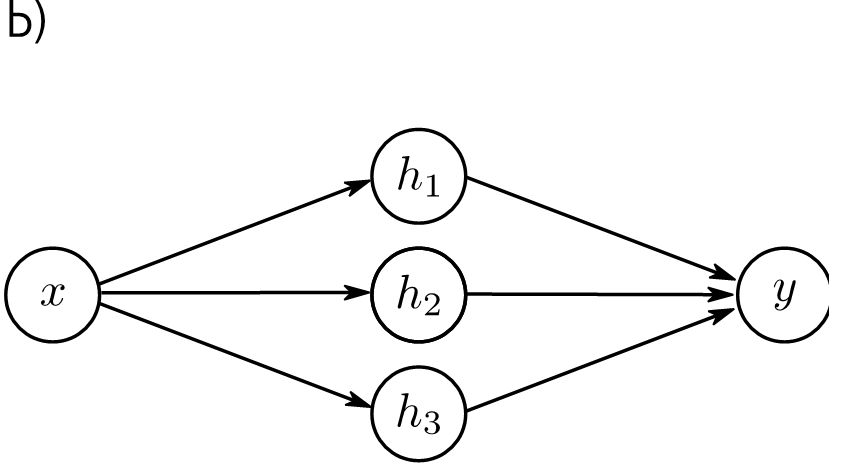

## Por qué usar redes neuronales?

Fíjense que tenemos, por ahora, ejemplos con solo 3 neuronas en la capa oculta.

Es claro, usando ReLU, que cada neurona representa una región lineal.

Imaginen que usamos 5, 10 y 20 regiones lineales


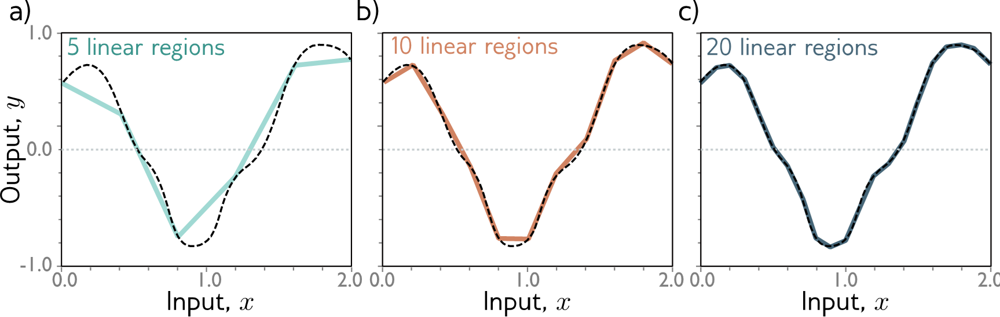

Esto, matemáticamente, sería:

$y=\phi_0+\phi_1 h_1+\phi_2 h_2+\phi_3 h_3+\phi_4 h_4+\phi_5 h_5$ para el primer caso

Para los casos 2 y 3 resulta tedioso escribir la función. Por ello, podemos generalizar y definir como $D$ el número de neuronas en la capa oculta. Para neurona, tenemos $$h_d=\mathrm{a}\left[\theta_{d 0}+\theta_{d 1} x\right]$$ y en consecuencia podemos definir la capa oculta como $$y=\phi_0+\sum_{d=1}^D \phi_d h_d $$ es decir $$ y=\phi_0+\sum_{d=1}^D \phi_d \mathrm{a}\left[\theta_{d 0}+\theta_{d 1} x\right]$$

### Teorema de aproximación universal

Intuitivamente estamos viendo que al aumentar $D$, pareciera que la aproximación de $f$ es mejor.

No solo es mejor sino que podemos probar que, con suficientes unidades ocultas, una red neuronal superficial puede describir **cualquier función continua** en un **subconjunto compacto** de con una **precisión arbitraria**

Hay un sin fin de teoremas de aproximación dependiendo de muchas hipótesis. Para profundizar más pueden leer _Multilayer feedforward networks are universal approximator 1989. Hornik et. al._ disponible en la sección [Referencias](https://ml.ucv.ai/referencias/)

#### De qué nos sirve este teorema?

Básicamente podemos aproximar cualquier función continua dependiendo de cuántas neuronas agreguemos dada una función de activación.

## Modificando la estructura de nuestra red

Es trivial extender la idea con una sola salida agregando una dimensión nueva:

Imaginen que tenemos 4 neuronas en la capa oculta

\begin{aligned}
h_1 & =\mathrm{a}\left[\theta_{10}+\theta_{11} x\right] \\
h_2 & =\mathrm{a}\left[\theta_{20}+\theta_{21} x\right] \\
h_3 & =\mathrm{a}\left[\theta_{30}+\theta_{31} x\right] \\
h_4 & =\mathrm{a}\left[\theta_{40}+\theta_{41} x\right]
\end{aligned}


Para agregar una salida extra, es decir, $f: \mathbb{R} \rightarrow \mathbb{R}^2$

\begin{aligned}
& y_1=\phi_{10}+\phi_{11} h_1+\phi_{12} h_2+\phi_{13} h_3+\phi_{14} h_4 \\
& y_2=\phi_{20}+\phi_{21} h_1+\phi_{22} h_2+\phi_{23} h_3+\phi_{24} h_4
\end{aligned}

### Red con salida extra

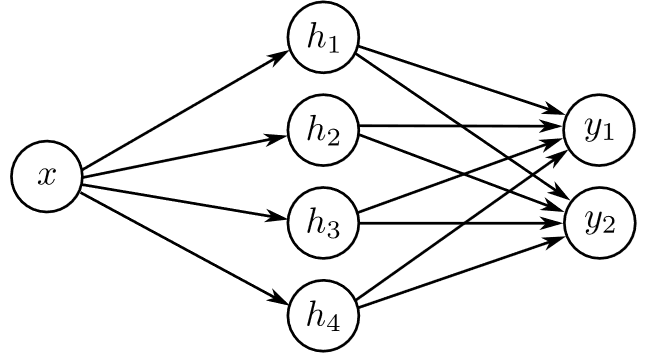

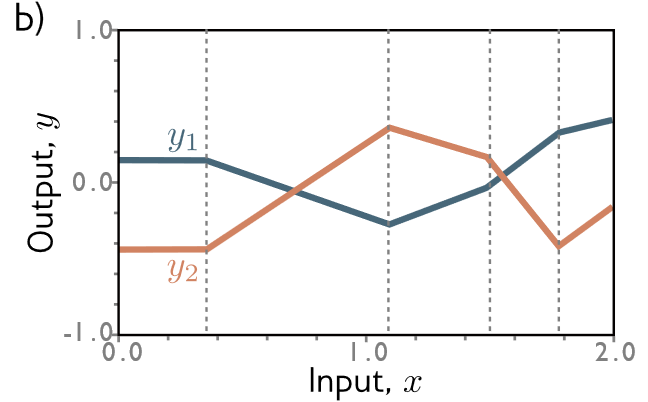

### Red con entrada extra

Pero podemos extender la idea a la entrada?

Por ejemplo: $f: \mathbb{R}^2 \rightarrow \mathbb{R}$

Si!



Para cada neurona ocultas tendríamos

\begin{aligned}
& h_1=\mathrm{a}\left[\theta_{10}+\theta_{11} x_1+\theta_{12} x_2\right] \\
& h_2=\mathrm{a}\left[\theta_{20}+\theta_{21} x_1+\theta_{22} x_2\right] \\
& h_3=\mathrm{a}\left[\theta_{30}+\theta_{31} x_1+\theta_{32} x_2\right]
\end{aligned}

Y para obtener la salida $y$ increíblemente (o no ) es idéntico: $$y=\phi_0+\phi_1 h_1+\phi_2 h_2+\phi_3 h_3$$

Gráficamente esto es

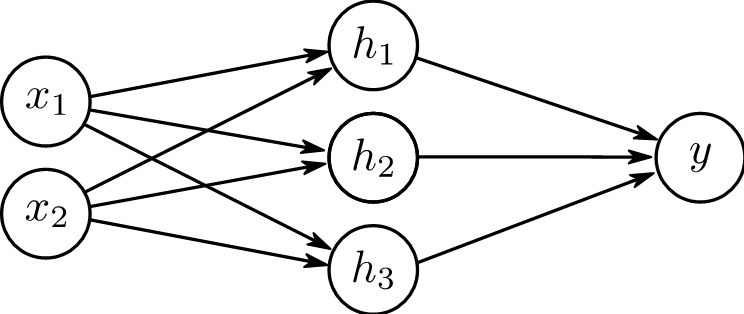

## Representación gráfica con más de una entrada

Imaginemos dos hiperplanos dados como: $$2 x_1 + 3 x_2 -5 = a \; \text{ y } \; 1 x_1 + 3 x_2 -5 = b$$ vistos por encima del eje de la salida y (perpendicular al eje no importa el valor de $f(x_1, x_2)$

Fijemos, como ejemplo, $a = b = 0$

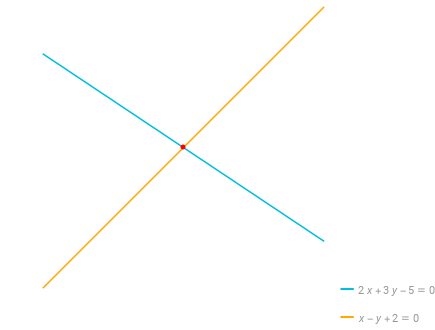

Agreguemos dos hiperplanos para el ejemplo $2 x + 3 y -5 = a$ con $a = -1$ y $a = 1$

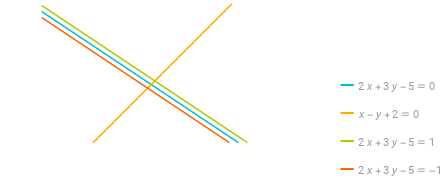

Para ambos "generadores" podemos "barrer" los posibles valores de $f(x_1, x_2)$

### Ejemplo con tres neuronas ocultas

Imaginemos ahora que tenemos nuestra red con tres neuronas ocultas. La representación sería, por ejemplo:



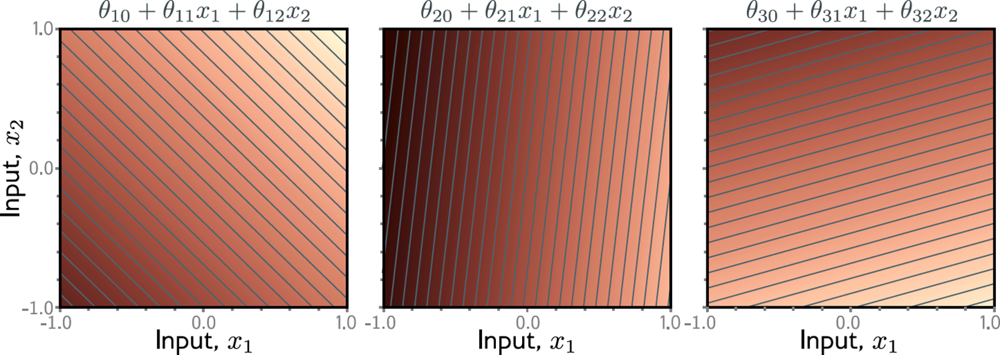

Aplicando la función ReLU

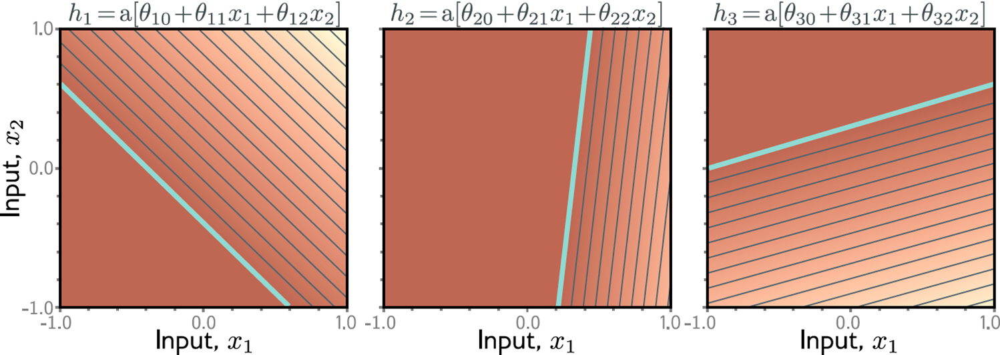

Multiplicar por el coeficiente asociado


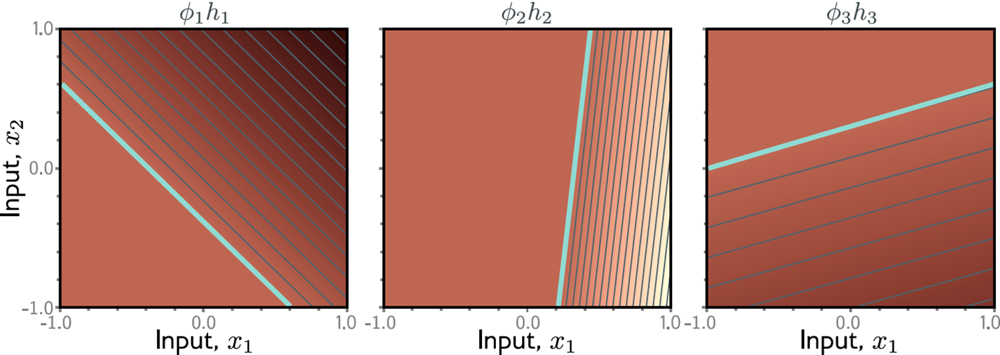

Finalmente, hacer la combinación lineal:



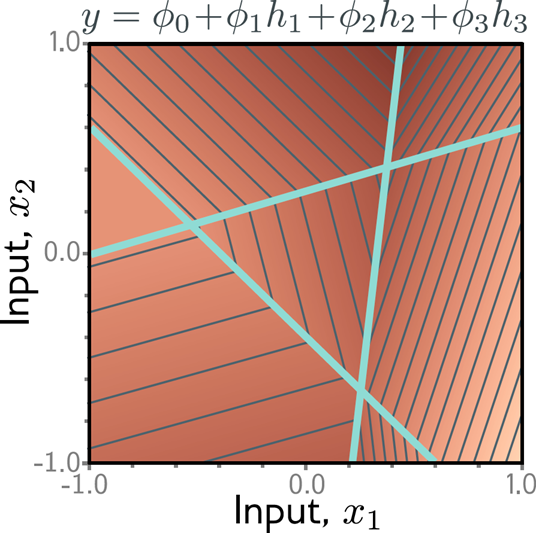

En resumen, agregando el valor de la función tendríamos algo como:

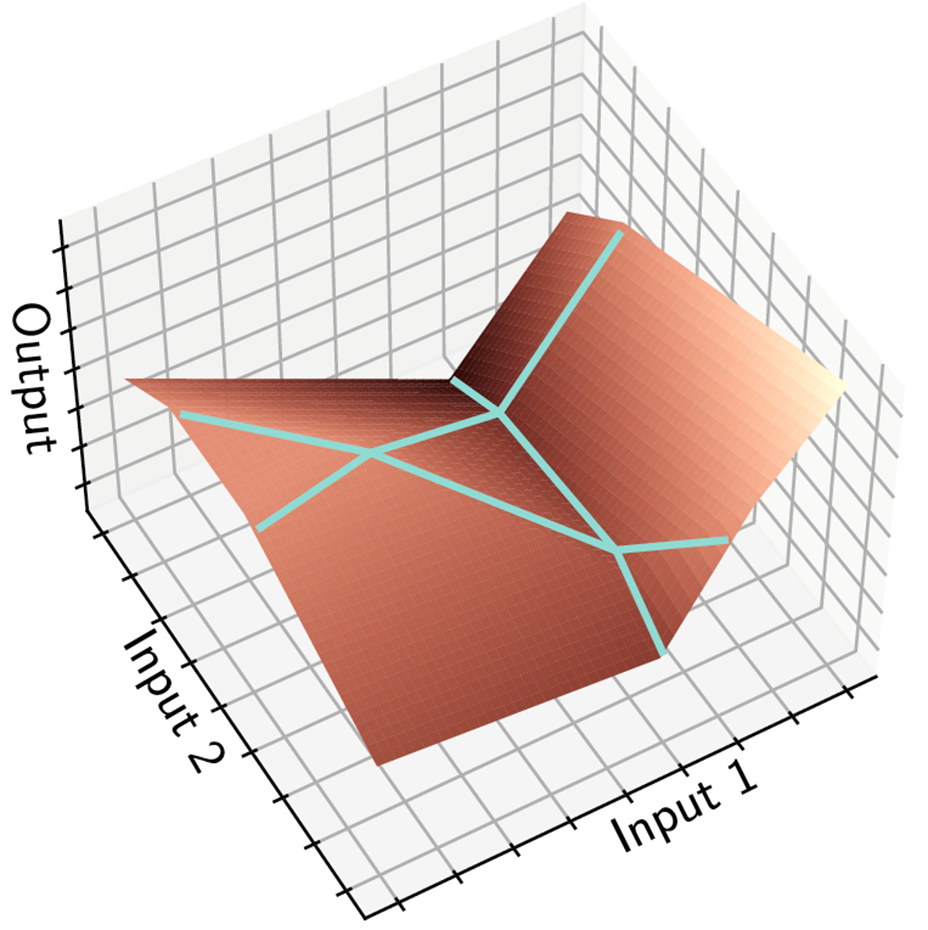

Bastante interesante sería fijar cada dimensión de entrada $x_i$ en el eje X y revisar el valor de $y$

## Redes neuronales no profundas con entradas, unidades y salidas arbitrarias

Una vez que entendemos todos los componentes es fácil generalizar nuestra definición con dimensiones completamente arbitrarias.

Sean:

1. $D_i$ la dimensión del dominio de nuestra función $f$
1. $D_o$ la dimensión del rango de nuestra función $f$
1. $D$ el número de unidades ocultas.
1. $a$ una función de activación.

Es decir: $$f: \mathbb{R}^{D_i} \rightarrow \mathbb{R}^{D_o}$$

Tenemos:

$$
h_d=\mathrm{a}\left[\theta_{d 0}+\sum_{i=1}^{D_i} \theta_{d i} x_i\right] \text{ para cada neurona } d \in \{1, \dots, D\} \;\; \text{ para cada input }  x \in \mathbb{R}^{D_i}   
$$

$$ y_j=\phi_{j 0}+\sum_{d=1}^D \phi_{j d} h_d \;\; \text{ para cada output }  y \in \mathbb{R}^{D_o}    
$$


## Regiones de interés

Usando ReLU es fácil demostrar que cada salida consiste en un politopo convexo $D$ dimensional

Con dos entradas, tres salidas tenemos siete polígonos:

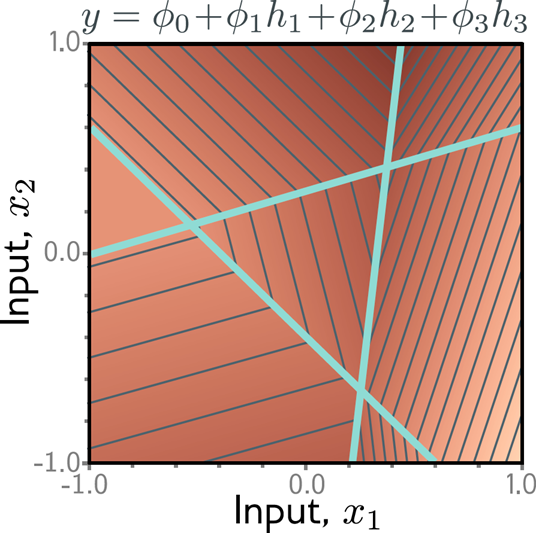


### Número de regiones de interés

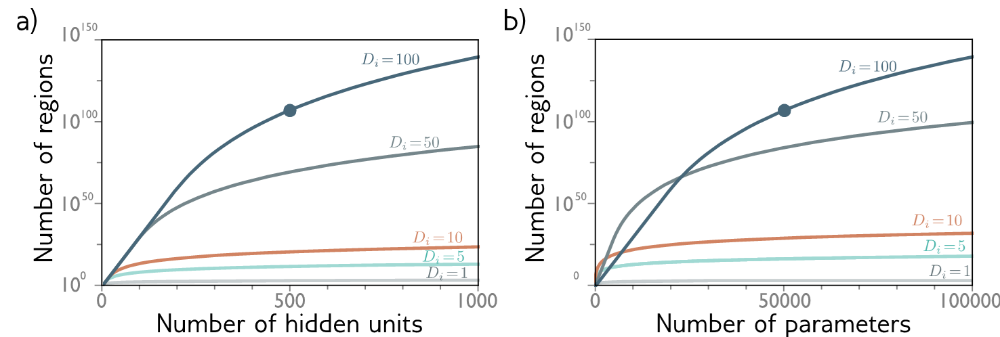

- El números de regiones creadas por $D>D_i$ planos en $D_i$ dimensiones fue provado por Zaslavsky en (1975) y es:
$$
\sum_{j=0}^{D_i}\binom{D}{j} \longleftarrow \text { Coeficientes binomiales }
$$
- Qué tan grande es? Es más grande que $2^{D i}$ pero menor a $2^D$.

## Resumen de la nomenclatura

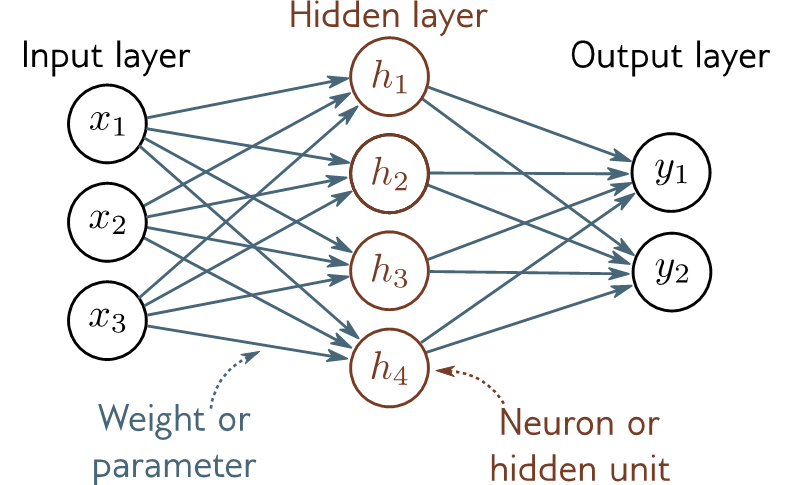

### Matemática/Matemáticas discretas -> Aprendizaje automático

- Puntos de corte (_Y-offsets_) = sesgos (_biases_)
- Pendientes (_Slopes_) = pesos (_weights_)
- Todos los pesos disponibles (_Everything in one layer connected to everything in the next_) = Redes totalmente conectadas (_fully connected network_)
-  Sin ciclos (_No loops_) = Redes de alimentación directa (_feedforward network_)
-  Valores antes de ReLU (activation functions) = activaciones (_activations_)
-  Valores después de ReLU = pre-activaciones (_pre-activations_)
-  Una capa oculta (_One hidden layer_) = Red neuronal poco profunda (_shallow neural network_)
-  Más de una capa oculta  (_More than one hidden layer_) = Redes neuronales profundas (_deep neural network_)
-  Número de unidades ocultas (_Number of hidden units_) ≈ Capacidad (_capacity_)


# PyTorch: Conceptos básicos

In [ ]:
import torch
import numpy as np

## Tensores

Un [Tensor](https://pytorch.org/docs/stable/generated/torch.tensor.html#torch.tensor) es simplemente una generalización de un vector en álgebra lineal implementado para PyTorch.

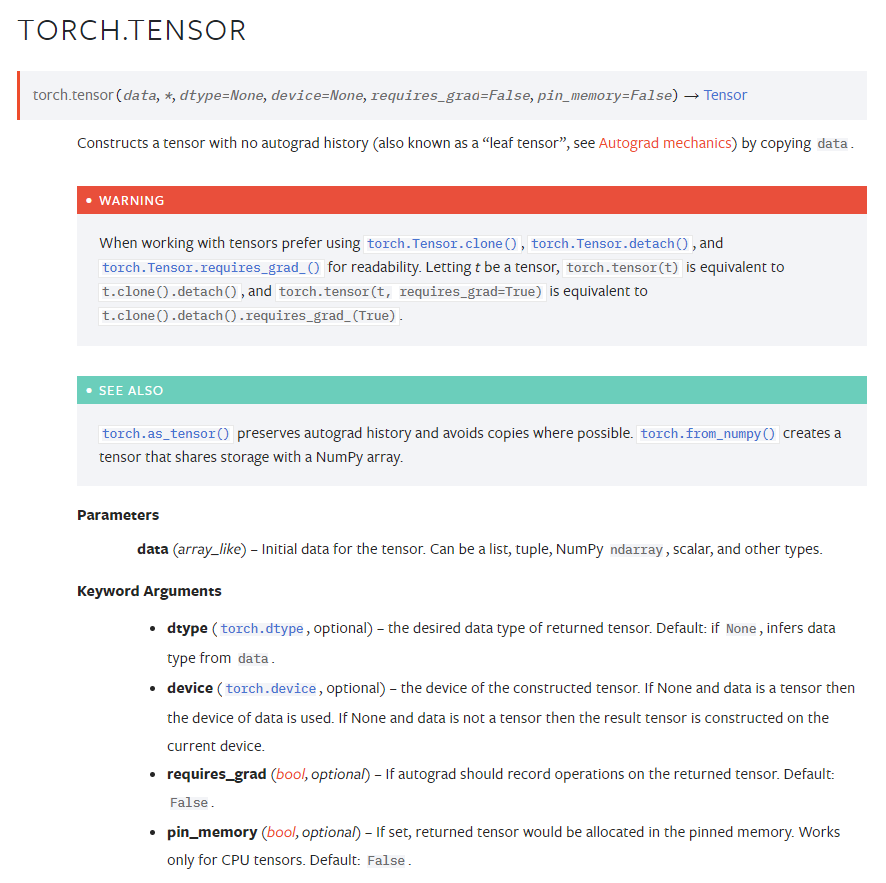

In [ ]:
a = torch.tensor([[0.1, 1.2], [2.2, 3.1], [4.9, 5.2]])

In [ ]:
a.shape

torch.Size([3, 2])

In [ ]:
torch.tensor?

In [ ]:
a.shape

torch.Size([3, 2])

In [ ]:
import numpy as np

In [ ]:
a = torch.tensor([[1, 2, 3]])
a.shape

torch.Size([1, 3])

In [ ]:
a = '1'+ 1


TypeError: can only concatenate str (not "int") to str

In [ ]:
torch.tensor([0, 1]).shape  # Type inference on data

torch.Size([2])

In [ ]:
b = torch.tensor([[0.11111, 0.222222, 0.3333333]],
             dtype=torch.float64,
             device=torch.device('cuda:0'))  # creates a double tensor on a CUDA device

In [ ]:
a + b

RuntimeError: Expected all tensors to be on the same device, but found at least two devices, cuda:0 and cpu!

In [ ]:
torch.tensor(3.14159)  # Create a zero-dimensional (scalar) tensor

tensor(3.1416)

In [ ]:

torch.tensor([])  # Create an empty tensor (of size (0,))

tensor([])

In [ ]:
# Crear un tensor de números enteros de 1D
tensor_2d_a = torch.tensor([[1.0, 2.0], [3.0, 4.0]],
             device=torch.device('cuda:0'))

# Crear un tensor de números flotantes de 2D (matriz)
tensor_2d = torch.tensor([[1.0, 2.0], [3.0, 4.0]],
             device=torch.device('cuda:0'))

# Realizar operaciones tensoriales
resultado = tensor_2d_a + tensor_2d

# Obtener la forma y el tipo de datos del tensor
print("Forma del tensor:", resultado.shape)
print("Tipo de datos del tensor:", resultado.dtype)
print("Device del resultado", resultado.device)

# Mover el tensor a la GPU (si está disponible)
if torch.cuda.is_available():
    resultado = resultado.cuda()
    print(resultado.device)


Forma del tensor: torch.Size([2, 2])
Tipo de datos del tensor: torch.float32
Device del resultado cuda:0
cuda:0


In [ ]:

resultado

tensor([[2., 4.],
        [6., 8.]], device='cuda:0')

In [ ]:
tensor_2d_a

tensor([[1., 2.],
        [3., 4.]])

In [ ]:
tensor_2d

tensor([[1., 2.],
        [3., 4.]])

## Operaciones básicas sobre tensores

### Operaciones matemáticas elementales
- `torch.add()`: Suma dos tensores elemento por elemento.
- `torch.sub()`: Resta dos tensores elemento por elemento.
- `torch.mul()`: Multiplica dos tensores elemento por elemento.
- `torch.div()`: Divide dos tensores elemento por elemento.
- `torch.pow()`: Eleva un tensor a una potencia especificada.
- `torch.sqrt()`: Calcula la raíz cuadrada de un tensor.
- `torch.exp()`: Calcula la exponencial de un tensor.
- `torch.log()`: Calcula el logaritmo natural de un tensor.

### Reducción de tensores
- `torch.sum()`: Calcula la suma de todos los elementos en un tensor.
- `torch.mean()`: Calcula la media de los elementos en un tensor.
- `torch.max()`: Encuentra el valor máximo en un tensor.
- `torch.min()`: Encuentra el valor mínimo en un tensor.

### Operaciones de álgebra lineal
- `torch.mm()`: Realiza la multiplicación matricial de dos tensores.
- `torch.matmul()`: Realiza la multiplicación de matrices o de tensores multidimensionales.
- `torch.inverse()`: Calcula la matriz inversa de una matriz cuadrada.
- `torch.det()`: Calcula el determinante de una matriz cuadrada.
- `torch.svd()`: Realiza la descomposición de valores singulares (SVD) de una matriz.

### Manipulación de tensores
- `torch.reshape()`: Cambia la forma (shape) de un tensor.
- `torch.transpose()`: Transpone un tensor intercambiando sus dimensiones.
- `torch.cat()`: Concatena varios tensores a lo largo de una dimensión especificada.
- `torch.split()`: Divide un tensor en trozos a lo largo de una dimensión especificada.
- `torch.index_select()`: Selecciona elementos de un tensor según un índice especificado.

### Operaciones booleanas y lógicas
- `torch.eq()`: Compara elementos de dos tensores y devuelve un tensor booleano de igualdad.
- `torch.gt()`, `torch.lt()`, `torch.ge()`, `torch.le()`: Realiza comparaciones de desigualdad elemento por elemento.

Estas son solo algunas de las muchas operaciones disponibles en PyTorch. Consulta la documentación oficial de PyTorch para obtener información más detallada sobre estas operaciones y muchas otras.


### Flatten

In [ ]:
import torch

# Crear un tensor de números enteros de 1D
tensor_1d = torch.tensor([1, 2, 3, 4])

# Crear un tensor de números flotantes de 2D (matriz)
tensor_2d = torch.tensor([[1.0, 2.0], [3.0, 4.0]])

# Realizar operaciones tensoriales
resultado = tensor_1d + tensor_2d

# Obtener la forma y el tipo de datos del tensor
print("Forma del tensor:", resultado.shape)
print("Tipo de datos del tensor:", resultado.dtype)

# Mover el tensor a la GPU (si está disponible)
if torch.cuda.is_available():
    resultado = resultado.cuda()


RuntimeError: The size of tensor a (4) must match the size of tensor b (2) at non-singleton dimension 1

In [ ]:
import torch

# Crear un tensor de números enteros de 1D
tensor_1d = torch.tensor([1, 2, 3, 4])

# Crear un tensor de números flotantes de 2D (matriz)
tensor_2d = torch.tensor([[1.0, 2.0], [3.0, 4.0]])

# Realizar operaciones tensoriales
resultado = tensor_1d + tensor_2d.flatten()

# Obtener la forma y el tipo de datos del tensor
print("Forma del tensor:", resultado.shape)
print("Tipo de datos del tensor:", resultado.dtype)

# Mover el tensor a la GPU (si está disponible)
if torch.cuda.is_available():
    resultado = resultado.cuda()


Forma del tensor: torch.Size([4])
Tipo de datos del tensor: torch.float32


In [ ]:
tensor_2d.flatten()


tensor([1., 2., 3., 4.])

In [ ]:
resultado

tensor([2., 4., 6., 8.], device='cuda:0')

## Capa lineal

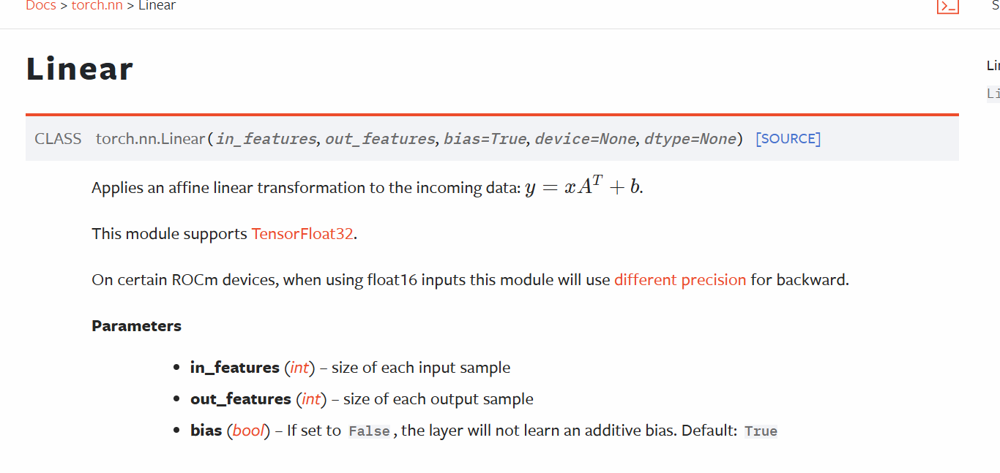

In [ ]:
import torch
import torch.nn as nn
import torch.nn.functional as F
import numpy as np

In [ ]:
a = int(input())

2


In [ ]:
a


2

In [ ]:
f = nn.Linear(2, 6)

In [ ]:
X = torch.randn(20, 2)
output = f(X)


In [ ]:
print(output.size())

torch.Size([20, 6])


In [ ]:
output

tensor([[ 0.3475, -0.1559, -0.6854, -0.0635,  0.2460, -0.6358],
        [ 0.3529,  0.4457, -0.5194,  0.1315,  0.7151, -0.6576],
        [ 0.4270, -1.5714, -1.0956, -0.5833, -0.9101, -0.6177],
        [ 0.0758, -0.7863, -0.8026, -0.0922, -0.0947, -0.5173],
        [-0.1976, -0.3780, -0.6308,  0.2232,  0.3810, -0.4324],
        [-1.5456,  1.4520,  0.1653,  1.7176,  2.5820, -0.0079],
        [-0.9742,  1.6394,  0.0954,  1.4021,  2.4049, -0.2196],
        [-0.1362, -0.8764, -0.7824,  0.0181, -0.0452, -0.4380],
        [-0.4013,  0.7268, -0.2804,  0.7225,  1.3636, -0.3956],
        [ 0.0400,  0.8974, -0.3271,  0.4873,  1.2472, -0.5600],
        [-0.3810,  0.6163, -0.3154,  0.6726,  1.2655, -0.3992],
        [ 0.2323,  0.4922, -0.4807,  0.2266,  0.8201, -0.6158],
        [ 1.1644, -1.3087, -1.1799, -0.9836, -1.1222, -0.8916],
        [ 0.9466, -0.1596, -0.8142, -0.4604, -0.0967, -0.8512],
        [-0.3269,  0.7979, -0.2765,  0.6968,  1.3773, -0.4247],
        [ 0.3752, -0.5043, -0.7881, -0.1

In [ ]:

f

Linear(in_features=2, out_features=6, bias=True)

In [ ]:
A = np.array([[ 0.4842,  0.1815],
        [-0.2806, -0.6376],
        [-0.1813, -0.2159],
        [-0.4124, -0.3303],
        [-0.4949, -0.6034],
        [-0.1649, -0.0442]])

Matriz A

In [ ]:
X @ A.T + f.bias

/tmp/ipython-input-7098/2658171314.py:1: DeprecationWarning: __array_wrap__ must accept context and return_scalar arguments (positionally) in the future. (Deprecated NumPy 2.0)
  X @ A.T + f.bias


tensor([[ 0.3475, -0.1559, -0.6854, -0.0635,  0.2460, -0.6358],
        [ 0.3529,  0.4456, -0.5194,  0.1315,  0.7152, -0.6576],
        [ 0.4271, -1.5714, -1.0957, -0.5832, -0.9101, -0.6176],
        [ 0.0759, -0.7863, -0.8026, -0.0921, -0.0947, -0.5172],
        [-0.1976, -0.3779, -0.6308,  0.2232,  0.3809, -0.4324],
        [-1.5456,  1.4521,  0.1654,  1.7175,  2.5820, -0.0080],
        [-0.9743,  1.6394,  0.0955,  1.4020,  2.4049, -0.2197],
        [-0.1361, -0.8764, -0.7824,  0.0181, -0.0452, -0.4380],
        [-0.4013,  0.7268, -0.2803,  0.7224,  1.3636, -0.3956],
        [ 0.0400,  0.8974, -0.3271,  0.4873,  1.2472, -0.5600],
        [-0.3810,  0.6164, -0.3153,  0.6726,  1.2654, -0.3993],
        [ 0.2322,  0.4922, -0.4807,  0.2266,  0.8201, -0.6158],
        [ 1.1644, -1.3088, -1.1800, -0.9835, -1.1222, -0.8915],
        [ 0.9465, -0.1596, -0.8142, -0.4603, -0.0967, -0.8512],
        [-0.3270,  0.7979, -0.2764,  0.6968,  1.3773, -0.4247],
        [ 0.3753, -0.5043, -0.7881, -0.1

In [ ]:
X[0] @ A.T[:,1] + f.bias[1]

/tmp/ipython-input-7098/2710026806.py:1: DeprecationWarning: __array_wrap__ must accept context and return_scalar arguments (positionally) in the future. (Deprecated NumPy 2.0)
  X[0] @ A.T[:,1] + f.bias[1]


tensor(-0.1559, dtype=torch.float64, grad_fn=<AddBackward0>)

In [ ]:
f.weight

Parameter containing:
tensor([[ 0.4842,  0.1815],
        [-0.2806, -0.6376],
        [-0.1813, -0.2159],
        [-0.4124, -0.3303],
        [-0.4949, -0.6034],
        [-0.1649, -0.0442]], requires_grad=True)

In [ ]:
f.bias

Parameter containing:
tensor([ 0.0850,  0.0524, -0.5715,  0.1787,  0.5585, -0.5482],
       requires_grad=True)

In [ ]:
X

tensor([[ 0.5027,  0.1055],
        [ 0.9395, -1.0302],
        [-0.2970,  2.6774],
        [-0.6129,  1.5852],
        [-1.0017,  1.1157],
        [-3.0472, -0.8542],
        [-1.5024, -1.8278],
        [-1.2005,  1.9850],
        [-0.7279, -0.7373],
        [ 0.4836, -1.5382],
        [-0.7555, -0.5520],
        [ 0.6739, -0.9864],
        [ 1.7115,  1.3816],
        [ 1.9817, -0.5396],
        [-0.4939, -0.9520],
        [ 0.3261,  0.7296],
        [ 0.2435,  0.2197],
        [-1.1495,  1.4001],
        [-1.7233,  0.3257],
        [-0.1967, -0.6504]])

In [ ]:
A.T

array([[ 0.2147, -0.2728, -0.4383,  0.2017, -0.2548,  0.4886],
       [-0.6031, -0.608 ,  0.5318, -0.6839,  0.5617, -0.0279]])

In [ ]:
s = f.weight @ X.T

In [ ]:
s.shape

torch.Size([6, 20])

In [ ]:
(f.weight @ X.T).T

/tmp/ipython-input-7098/2350469627.py:1: UserWarning: The use of `x.T` on tensors of dimension other than 2 to reverse their shape is deprecated and it will throw an error in a future release. Consider `x.mT` to transpose batches of matrices or `x.permute(*torch.arange(x.ndim - 1, -1, -1))` to reverse the dimensions of a tensor. (Triggered internally at /pytorch/aten/src/ATen/native/TensorShape.cpp:4480.)
  (f.weight @ X.T + f.bias.T).T


RuntimeError: The size of tensor a (20) must match the size of tensor b (6) at non-singleton dimension 1

Datos de entrada x

input

In [ ]:
x = np.array([[-0.1402,  0.1919],
        [-2.6055, -0.0266],
        [-0.6680, -1.0523],
        [ 0.4313, -1.5246],
        [ 0.7701,  1.3635],
        [ 0.7513,  0.4311],
        [ 0.7178, -1.6566],
        [ 1.0987, -0.1972],
        [ 1.1539,  0.1019],
        [-1.7077,  1.5998],
        [ 0.6666, -0.2663],
        [ 1.3510, -1.4805],
        [-0.3549, -1.8506],
        [-0.7074, -0.0469],
        [ 0.1778, -0.6994],
        [ 0.9823,  1.2335],
        [ 0.1381,  0.0110],
        [ 0.3475,  0.0051],
        [-0.2799,  0.4205],
        [ 1.7141, -1.7649]])

In [ ]:
A.T.shape

(2, 6)

In [ ]:
x.shape

(20, 2)

In [ ]:

x * A

ValueError: operands could not be broadcast together with shapes (20,2) (6,2) 

In [ ]:
A * x.T

ValueError: operands could not be broadcast together with shapes (6,2) (2,20) 

In [ ]:
x.T * A

ValueError: operands could not be broadcast together with shapes (2,20) (6,2) 

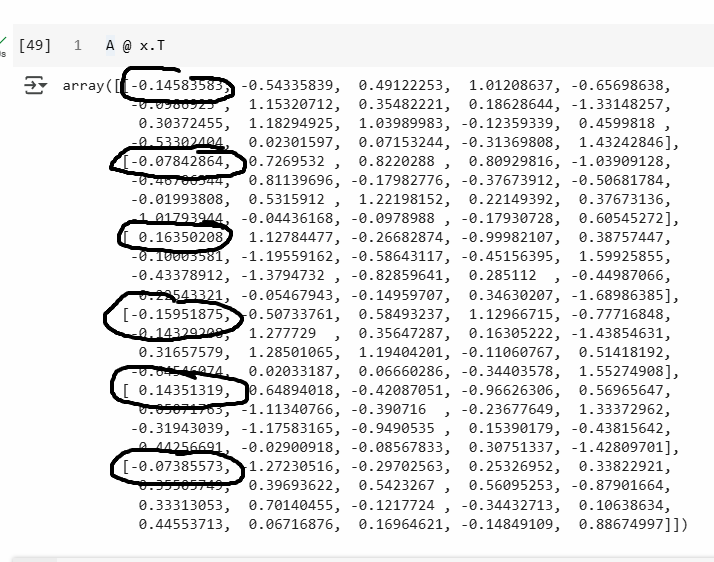

In [ ]:
x @  A.T

array([[-0.14583583, -0.07842864,  0.16350208, -0.15951875,  0.14351319,
        -0.07385573],
       [-0.54335839,  0.7269532 ,  1.12784477, -0.50733761,  0.64894018,
        -1.27230516],
       [ 0.49122253,  0.8220288 , -0.26682874,  0.58493237, -0.42087051,
        -0.29702563],
       [ 1.01208637,  0.80929816, -0.99982107,  1.12966715, -0.96626306,
         0.25326952],
       [-0.65698638, -1.03909128,  0.38757447, -0.77716848,  0.56965647,
         0.33822921],
       [-0.0986923 , -0.46706344, -0.10003581, -0.14329208,  0.05071763,
         0.35505749],
       [ 1.15320712,  0.81139696, -1.19559162,  1.277729  , -1.11340766,
         0.39693622],
       [ 0.35482221, -0.17982776, -0.58643117,  0.35647287, -0.390716  ,
         0.5423267 ],
       [ 0.18628644, -0.37673912, -0.45156395,  0.16305222, -0.23677649,
         0.56095253],
       [-1.33148257, -0.50681784,  1.59925855, -1.43854631,  1.33372962,
        -0.87901664],
       [ 0.30372455, -0.01993808, -0.43378912,  0.

In [ ]:
A.shape

(6, 2)

In [ ]:
A @ x.T

array([[-0.14583583, -0.54335839,  0.49122253,  1.01208637, -0.65698638,
        -0.0986923 ,  1.15320712,  0.35482221,  0.18628644, -1.33148257,
         0.30372455,  1.18294925,  1.03989983, -0.12359339,  0.4599818 ,
        -0.53302404,  0.02301597,  0.07153244, -0.31369808,  1.43242846],
       [-0.07842864,  0.7269532 ,  0.8220288 ,  0.80929816, -1.03909128,
        -0.46706344,  0.81139696, -0.17982776, -0.37673912, -0.50681784,
        -0.01993808,  0.5315912 ,  1.22198152,  0.22149392,  0.37673136,
        -1.01793944, -0.04436168, -0.0978988 , -0.17930728,  0.60545272],
       [ 0.16350208,  1.12784477, -0.26682874, -0.99982107,  0.38757447,
        -0.10003581, -1.19559162, -0.58643117, -0.45156395,  1.59925855,
        -0.43378912, -1.3794732 , -0.82859641,  0.285112  , -0.44987066,
         0.22543321, -0.05467943, -0.14959707,  0.34630207, -1.68986385],
       [-0.15951875, -0.50733761,  0.58493237,  1.12966715, -0.77716848,
        -0.14329208,  1.277729  ,  0.35647287,  

In [ ]:
f.bias.shape


torch.Size([6])

In [ ]:
f.bias

Parameter containing:
tensor([-0.1006, -0.3928,  0.1937, -0.1305, -0.6297, -0.6893],
       requires_grad=True)

In [ ]:
b = np.array([-0.1006, -0.3928,  0.1937, -0.1305, -0.6297, -0.6893])

In [ ]:
b = f.bias.detach().numpy()

In [ ]:
b

array([-0.10055791, -0.39280736,  0.19368061, -0.13050316, -0.6297329 ,
       -0.68927294], dtype=float32)

In [ ]:
b.shape

(6,)

## Haciendo la operación en numpy

In [ ]:
x.shape

NameError: name 'x' is not defined

In [ ]:
A.shape

(6, 2)

In [ ]:
b.shape

NameError: name 'b' is not defined

Consistencia en las dimensiones

In [ ]:
A = A.T

In [ ]:
x @ A + b

array([[-0.24639374, -0.471236  ,  0.35718269, -0.29002191, -0.48621972,
        -0.76312867],
       [-0.6439163 ,  0.33414584,  1.32152538, -0.63784077,  0.01920727,
        -1.9615781 ],
       [ 0.39066462,  0.42922144, -0.07314813,  0.45442921, -1.05060342,
        -0.98629857],
       [ 0.91152846,  0.4164908 , -0.80614046,  0.99916399, -1.59599597,
        -0.43600342],
       [-0.75754429, -1.43189864,  0.58125508, -0.90767164, -0.06007644,
        -0.35104373],
       [-0.19925021, -0.8598708 ,  0.0936448 , -0.27379524, -0.57901528,
        -0.33421545],
       [ 1.05264921,  0.4185896 , -1.00191101,  1.14722584, -1.74314057,
        -0.29233672],
       [ 0.2542643 , -0.57263512, -0.39275056,  0.22596971, -1.02044891,
        -0.14694624],
       [ 0.08572853, -0.76954648, -0.25788334,  0.03254906, -0.8665094 ,
        -0.12832041],
       [-1.43204048, -0.8996252 ,  1.79293916, -1.56904947,  0.70399671,
        -1.56828958],
       [ 0.20316664, -0.41274544, -0.24010851,  0.

# 1 Tarea:

- Reproducir operaciones en numpy

In [ ]:
x

array([[-0.1402,  0.1919],
       [-2.6055, -0.0266],
       [-0.668 , -1.0523],
       [ 0.4313, -1.5246],
       [ 0.7701,  1.3635],
       [ 0.7513,  0.4311],
       [ 0.7178, -1.6566],
       [ 1.0987, -0.1972],
       [ 1.1539,  0.1019],
       [-1.7077,  1.5998],
       [ 0.6666, -0.2663],
       [ 1.351 , -1.4805],
       [-0.3549, -1.8506],
       [-0.7074, -0.0469],
       [ 0.1778, -0.6994],
       [ 0.9823,  1.2335],
       [ 0.1381,  0.011 ],
       [ 0.3475,  0.0051],
       [-0.2799,  0.4205],
       [ 1.7141, -1.7649]])

La primera función es [nn.linear](https://pytorch.org/docs/stable/generated/torch.nn.Linear.html)

In [ ]:
output

tensor([[-0.4034],
        [-0.7146],
        [-0.9463],
        [ 0.0014],
        [-0.4501]], grad_fn=<AddmmBackward0>)

In [ ]:
input

tensor([[-0.2545, -0.1449],
        [-1.6228,  0.1209],
        [ 0.8263, -0.5515],
        [-1.6551, -0.1254],
        [ 0.5426,  0.5314]])

In [ ]:
#@title Solución usando las dimensiones de PyTorch

x @ A.T + b

array([[-0.24643583, -0.47122864,  0.35720208, -0.29001875, -0.48618681,
        -0.76315573],
       [-0.64395839,  0.3341532 ,  1.32154477, -0.63783761,  0.01924018,
        -1.96160516],
       [ 0.39062253,  0.4292288 , -0.07312874,  0.45443237, -1.05057051,
        -0.98632563],
       [ 0.91148637,  0.41649816, -0.80612107,  0.99916715, -1.59596306,
        -0.43603048],
       [-0.75758638, -1.43189128,  0.58127447, -0.90766848, -0.06004353,
        -0.35107079],
       [-0.1992923 , -0.85986344,  0.09366419, -0.27379208, -0.57898237,
        -0.33424251],
       [ 1.05260712,  0.41859696, -1.00189162,  1.147229  , -1.74310766,
        -0.29236378],
       [ 0.25422221, -0.57262776, -0.39273117,  0.22597287, -1.020416  ,
        -0.1469733 ],
       [ 0.08568644, -0.76953912, -0.25786395,  0.03255222, -0.86647649,
        -0.12834747],
       [-1.43208257, -0.89961784,  1.79295855, -1.56904631,  0.70402962,
        -1.56831664],
       [ 0.20312455, -0.41273808, -0.24008912,  0.

### Con imágenes, calculando la entrada 11

Básicamente, para la primera instancia de nuestro dataset, buscamos el valor en $h_1$

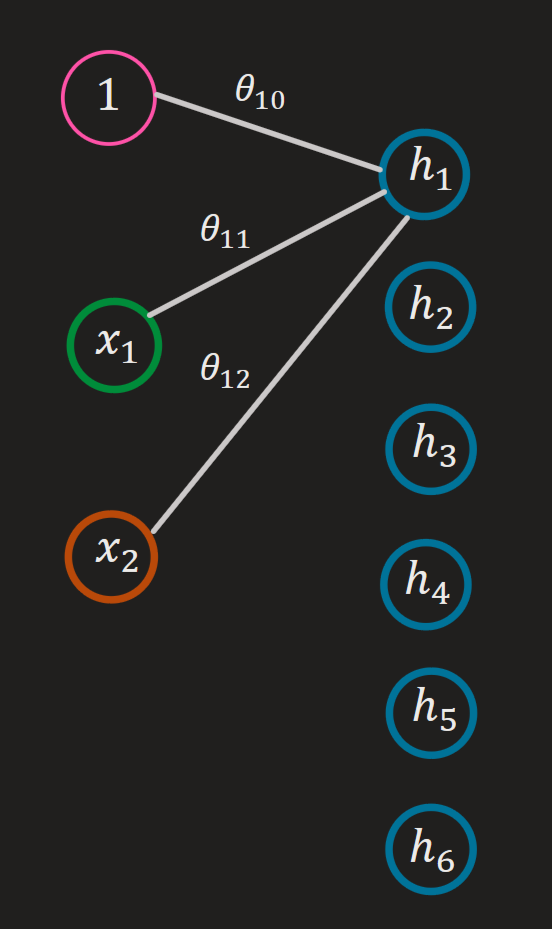

Los cálculos serían los siguientes

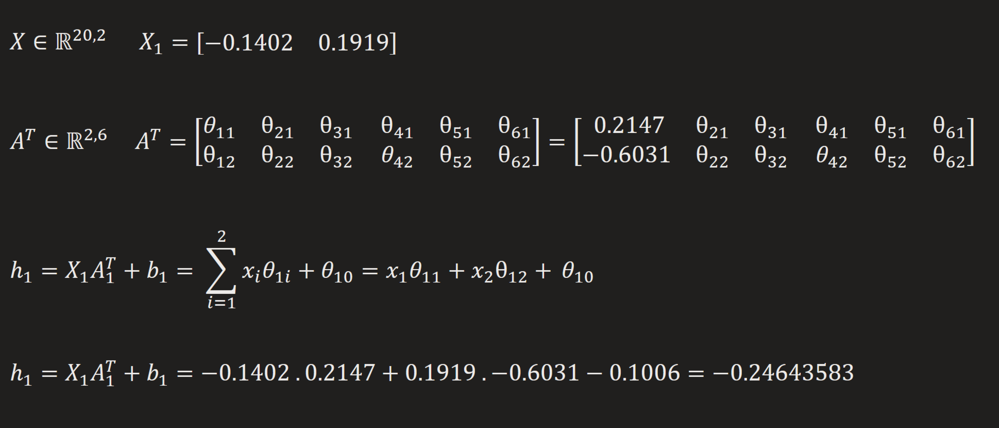

In [ ]:
x1 = x[0, :]
x1

array([-0.1402,  0.1919])

In [ ]:
A1T = A.T[:, 0]
A1T

array([ 0.2147, -0.6031])

In [ ]:
theta00 = b[0]
theta00

-0.1006

In [ ]:
x1 @ A1T + theta00

-0.24643583

y efectivamente

In [ ]:
r = x @ A.T + b
r[0, 0]

-0.24643583

In [ ]:
#@title Solución usando la "notación" visual

B = A @ x.T  + b.reshape(6, 1)
B.T

array([[-0.24643583, -0.47122864,  0.35720208, -0.29001875, -0.48618681,
        -0.76315573],
       [-0.64395839,  0.3341532 ,  1.32154477, -0.63783761,  0.01924018,
        -1.96160516],
       [ 0.39062253,  0.4292288 , -0.07312874,  0.45443237, -1.05057051,
        -0.98632563],
       [ 0.91148637,  0.41649816, -0.80612107,  0.99916715, -1.59596306,
        -0.43603048],
       [-0.75758638, -1.43189128,  0.58127447, -0.90766848, -0.06004353,
        -0.35107079],
       [-0.1992923 , -0.85986344,  0.09366419, -0.27379208, -0.57898237,
        -0.33424251],
       [ 1.05260712,  0.41859696, -1.00189162,  1.147229  , -1.74310766,
        -0.29236378],
       [ 0.25422221, -0.57262776, -0.39273117,  0.22597287, -1.020416  ,
        -0.1469733 ],
       [ 0.08568644, -0.76953912, -0.25786395,  0.03255222, -0.86647649,
        -0.12834747],
       [-1.43208257, -0.89961784,  1.79295855, -1.56904631,  0.70402962,
        -1.56831664],
       [ 0.20312455, -0.41273808, -0.24008912,  0.

## Resultado esperado

In [ ]:
tensor([[-0.2464, -0.4713,  0.3572, -0.2901, -0.4862, -0.7631],
        [-0.6438,  0.3340,  1.3214, -0.6379,  0.0191, -1.9616],
        [ 0.3907,  0.4292, -0.0732,  0.4544, -1.0507, -0.9863],
        [ 0.9115,  0.4166, -0.8061,  0.9992, -1.5960, -0.4360],
        [-0.7576, -1.4319,  0.5813, -0.9076, -0.0600, -0.3510],
        [-0.1993, -0.8598,  0.0936, -0.2737, -0.5790, -0.3342],
        [ 1.0526,  0.4186, -1.0019,  1.1472, -1.7431, -0.2923],
        [ 0.2542, -0.5726, -0.3927,  0.2260, -1.0204, -0.1469],
        [ 0.0857, -0.7695, -0.2579,  0.0326, -0.8665, -0.1283],
        [-1.4319, -0.8997,  1.7928, -1.5691,  0.7039, -1.5683],
        [ 0.2031, -0.4127, -0.2400,  0.1861, -0.9491, -0.3562],
        [ 1.0823,  0.1389, -1.1857,  1.1545, -1.8055,  0.0122],
        [ 0.9394,  0.8292, -0.6349,  1.0635, -1.5789, -0.8111],
        [-0.2241, -0.1713,  0.4787, -0.2411, -0.4759, -1.0336],
        [ 0.3594, -0.0161, -0.2562,  0.3837, -1.0679, -0.5829],
        [-0.6336, -1.4107,  0.4191, -0.7759, -0.1871, -0.2437],
        [-0.0776, -0.4371,  0.1390, -0.1102, -0.6587, -0.6221],
        [-0.0290, -0.4907,  0.0441, -0.0639, -0.7154, -0.5196],
        [-0.4143, -0.5721,  0.5400, -0.4746, -0.3222, -0.8378],
        [ 1.3318,  0.2128, -1.4961,  1.4223, -2.0578,  0.1975]],
       grad_fn=<AddmmBackward0>)

array([[-0.24643583, -0.47122864,  0.35720208, -0.29001875, -0.48618681,
        -0.76315573],
       [-0.64395839,  0.3341532 ,  1.32154477, -0.63783761,  0.01924018,
        -1.96160516],
       [ 0.39062253,  0.4292288 , -0.07312874,  0.45443237, -1.05057051,
        -0.98632563],
       [ 0.91148637,  0.41649816, -0.80612107,  0.99916715, -1.59596306,
        -0.43603048],
       [-0.75758638, -1.43189128,  0.58127447, -0.90766848, -0.06004353,
        -0.35107079],
       [-0.1992923 , -0.85986344,  0.09366419, -0.27379208, -0.57898237,
        -0.33424251],
       [ 1.05260712,  0.41859696, -1.00189162,  1.147229  , -1.74310766,
        -0.29236378],
       [ 0.25422221, -0.57262776, -0.39273117,  0.22597287, -1.020416  ,
        -0.1469733 ],
       [ 0.08568644, -0.76953912, -0.25786395,  0.03255222, -0.86647649,
        -0.12834747],
       [-1.43208257, -0.89961784,  1.79295855, -1.56904631,  0.70402962,
        -1.56831664],
       [ 0.20312455, -0.41273808, -0.24008912,  0.

In [ ]:
b.reshape(6, 1)

array([[-0.1006],
       [-0.3928],
       [ 0.1937],
       [-0.1305],
       [-0.6297],
       [-0.6893]])

In [ ]:
x @ A.T + b

array([[-0.24643583, -0.47122864,  0.35720208, -0.29001875, -0.48618681,
        -0.76315573],
       [-0.64395839,  0.3341532 ,  1.32154477, -0.63783761,  0.01924018,
        -1.96160516],
       [ 0.39062253,  0.4292288 , -0.07312874,  0.45443237, -1.05057051,
        -0.98632563],
       [ 0.91148637,  0.41649816, -0.80612107,  0.99916715, -1.59596306,
        -0.43603048],
       [-0.75758638, -1.43189128,  0.58127447, -0.90766848, -0.06004353,
        -0.35107079],
       [-0.1992923 , -0.85986344,  0.09366419, -0.27379208, -0.57898237,
        -0.33424251],
       [ 1.05260712,  0.41859696, -1.00189162,  1.147229  , -1.74310766,
        -0.29236378],
       [ 0.25422221, -0.57262776, -0.39273117,  0.22597287, -1.020416  ,
        -0.1469733 ],
       [ 0.08568644, -0.76953912, -0.25786395,  0.03255222, -0.86647649,
        -0.12834747],
       [-1.43208257, -0.89961784,  1.79295855, -1.56904631,  0.70402962,
        -1.56831664],
       [ 0.20312455, -0.41273808, -0.24008912,  0.

In [ ]:
for x in input:
  print(x.size())

torch.Size([2])
torch.Size([2])
torch.Size([2])
torch.Size([2])
torch.Size([2])


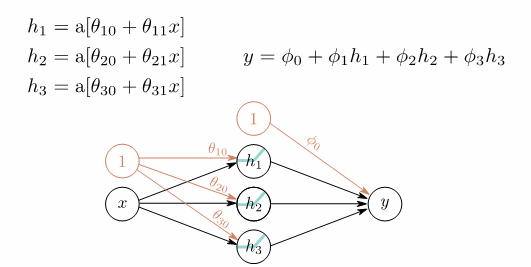

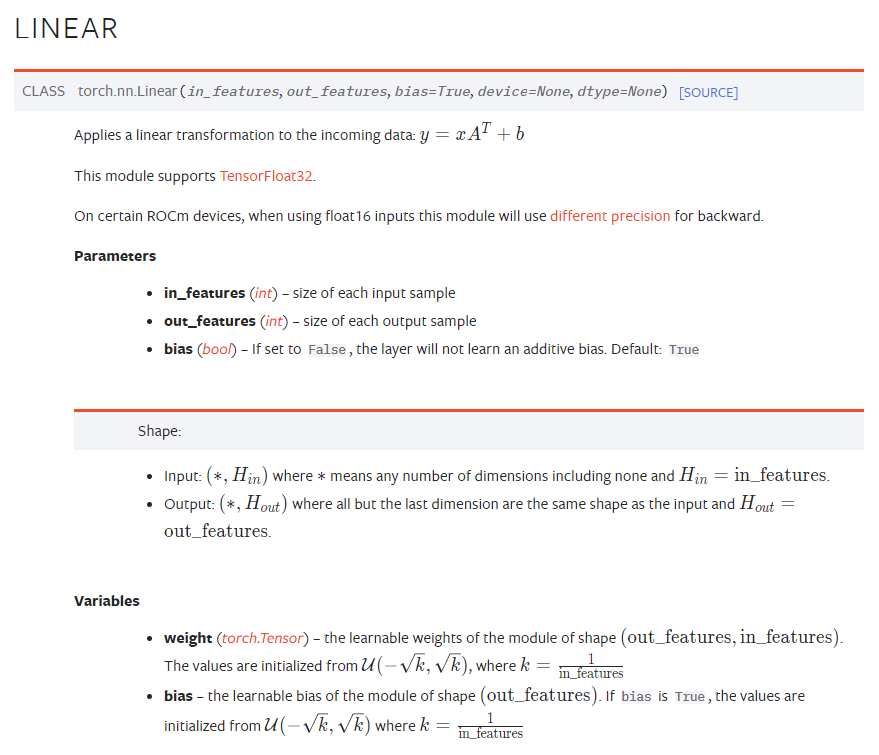

In [ ]:
f.weight

Parameter containing:
tensor([[0.5976, 0.0572]], requires_grad=True)

### Entendiendo las dimensiones

Qué valores puede tomar a, b, c y d

In [ ]:
a, b, c, d = 0, 0, 0, 0
f = nn.Linear(a, b)
input = torch.randn(c, d)
output = f(input)

# Redes neuronales en PyTorch

In [ ]:
from torch import nn

La lista de [funcionalidades de redes neuronales](https://pytorch.org/docs/stable/nn.html) así como su documentación es el mejor lugar para aprender a usar PyTorch

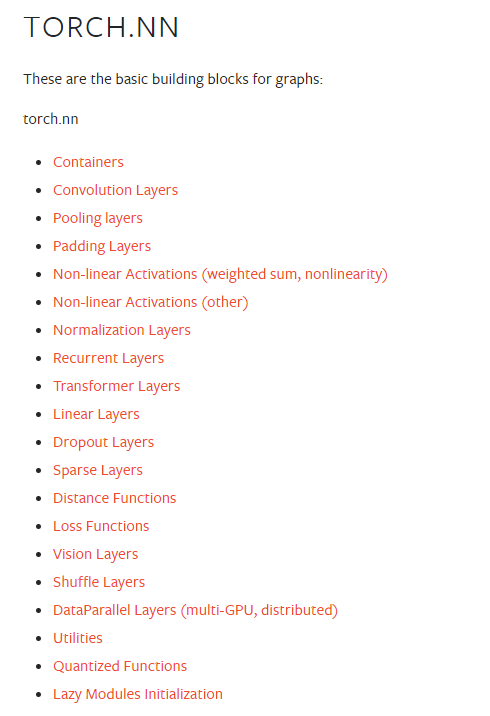

## Funciones de activación

1. **[ReLU (Rectified Linear Unit):](https://pytorch.org/docs/stable/generated/torch.nn.ReLU.html)** `nn.ReLU()`
   - La función de activación ReLU apaga todos los valores negativos en el tensor y mantiene los valores positivos sin cambios.

2. **[Sigmoid:](https://pytorch.org/docs/stable/generated/torch.nn.Sigmoid.html)** `nn.Sigmoid()`
   - La función de activación sigmoidal aplasta los valores de entrada en el rango (0, 1), lo que la hace útil para problemas de clasificación binaria.

3. **Tanh (Tangente hiperbólica):** `nn.Tanh()`
   - La función de activación tangente hiperbólica aplasta los valores de entrada en el rango (-1, 1), y es similar a la sigmoidal pero con una salida centrada en cero.

4. **Softmax:** `nn.Softmax(dim=...)`
   - La función de activación softmax se utiliza típicamente en la capa de salida de una red neuronal para convertir un conjunto de valores en una distribución de probabilidad sobre clases. El argumento `dim` especifica la dimensión a lo largo de la cual se calcula el softmax.

5. **Leaky ReLU:** `nn.LeakyReLU(negative_slope=...)`
   - Similar a ReLU, pero permite que una pequeña pendiente negativa se propague a través de la red, lo que ayuda a prevenir el problema de la "neurona muerta".

6. **ELU (Exponential Linear Unit):** `nn.ELU(alpha=...)`
   - La función ELU es una alternativa a ReLU que permite una pendiente negativa y evita el problema de las "neuronas muertas". El parámetro `alpha` controla la pendiente negativa.

7. **SELU (Scaled Exponential Linear Unit):** `nn.SELU()`
   - SELU es una función de activación que se basa en ELU y se ha demostrado que mejora el entrenamiento de redes neuronales profundas.

8. **Softplus:** `nn.Softplus()`
   - La función de activación Softplus es una versión suave y diferenciable de ReLU, que se utiliza en algunos modelos.

9. **Swish:** `nn.SiLU()`
   - La función de activación Swish es otra función suave y diferenciable que se ha propuesto como alternativa a ReLU.



###  **[ReLU (Rectified Linear Unit):](https://pytorch.org/docs/stable/generated/torch.nn.ReLU.html)** `nn.ReLU()`

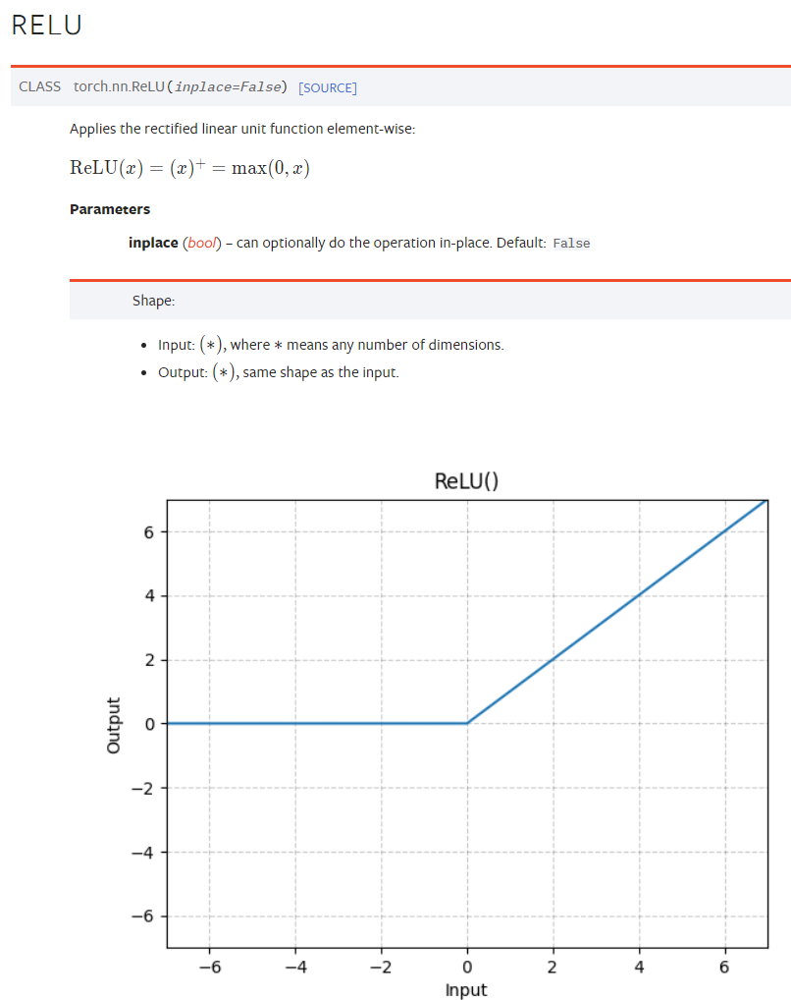

In [ ]:
relu = nn.ReLU()

In [ ]:
input = torch.randn(2)
input

tensor([-0.4612, -0.1926])

In [ ]:
output = relu(input)
output

tensor([0., 0.])

In [ ]:
input = torch.randn(2, 3)

In [ ]:
input

tensor([[-2.0496, -0.2043,  0.9284],
        [ 0.4245,  0.4434, -1.5299]])

In [ ]:
relu(input)

tensor([[0.0000, 0.0000, 0.9284],
        [0.4245, 0.4434, 0.0000]])

## **Contenedores:** Sequential

Un contenedor es una estructura que nos permite conectar elementos de PyTorch y habilitar funcionalidades importantes dentro de nuestras soluciones como:

1. Composición de funciones
1. Cálculo de derivadas

[Sequential](https://pytorch.org/docs/stable/generated/torch.nn.Sequential.html#torch.nn.Sequential) será el contenedor por excelencia para definir nuestras redes neuronales

### Ejemplo de la clase

Recordemos el ejemplo de la clase

Identifiquemos juntos cómo podemos representar esta red neuronal en PyTorch

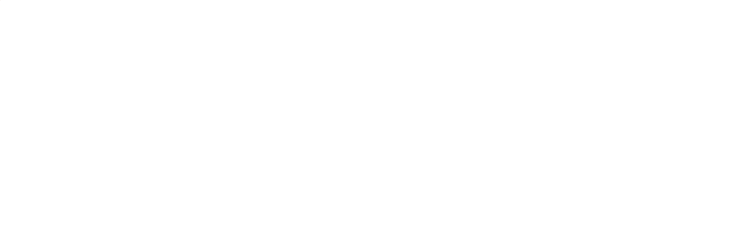

$$
\begin{aligned}
h_1 & =\mathrm{a}\left[\theta_{10}+\theta_{11} x\right] \\
h_2 & =\mathrm{a}\left[\theta_{20}+\theta_{21} x\right] \\
h_3 & =\mathrm{a}\left[\theta_{30}+\theta_{31} x\right]
\end{aligned}
$$

y la función estaba definida como

$$
y=\phi_0+\phi_1 h_1+\phi_2 h_2+\phi_3 h_3
$$

Cuya representación era

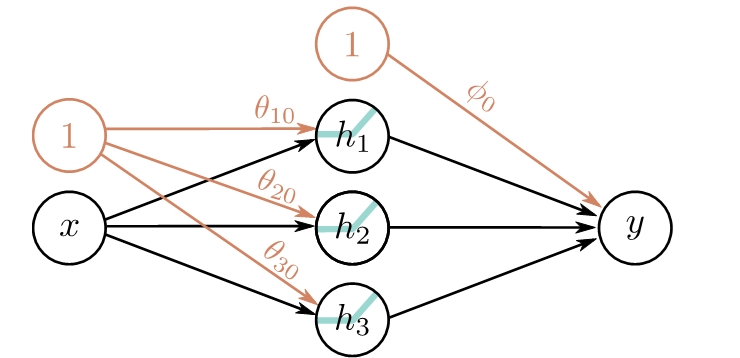

import torch.nn as nn

model = nn.Sequential(
    nn.Linear(1, 3))

In [ ]:
import torch.nn as nn
import torch

In [ ]:
nn.Linear(1, 3)(torch.tensor([1.0]))

tensor([-1.4368, -0.2933, -1.2247], grad_fn=<ViewBackward0>)

In [ ]:
model = nn.Sequential(
    nn.Linear(1, 3),
    relu,
    nn.Linear(1, 3)
)

In [ ]:
model[0]

Linear(in_features=1, out_features=3, bias=True)

In [ ]:
model(torch.tensor([1.0]))

tensor([0., 0., 0.], grad_fn=<ReluBackward0>)

In [ ]:
model[1](model[0](torch.tensor([1.0])))

tensor([0., 0., 0.], grad_fn=<ReluBackward0>)

In [ ]:
model = nn.Sequential(
    nn.Linear(5, 3),
    nn.ReLU(),
    nn.Linear(3, 5),
    nn.ReLU(),
    nn.Linear(5, 4),
    nn.ReLU(),
    nn.Linear(4, 2)
)

In [ ]:
model

Sequential(
  (0): Linear(in_features=5, out_features=3, bias=True)
  (1): ReLU()
  (2): Linear(in_features=3, out_features=5, bias=True)
  (3): ReLU()
  (4): ReLU()
  (5): Linear(in_features=5, out_features=2, bias=True)
)

In [ ]:
model(
    torch.tensor([
        [2.2, 2.3, 2.3, 3.4, 5.6],

        [2.2, 2.3, 2.3, 3.4, 5.6]
    ])
)

tensor([[-0.6299, -0.1209],
        [-0.6299, -0.1209]], grad_fn=<AddmmBackward0>)

In [ ]:
model[2].weight[0]

tensor([ 0.3943,  0.4051, -0.5450], grad_fn=<SelectBackward0>)

## Tarea

Intentar representar las operaciones de esa red en numpy

In [ ]:
import torch.nn as nn
import torch

model = nn.Sequential(
    nn.Linear(1, 3),
    nn.ReLU(),
    nn.Linear(3, 1)
    )

In [ ]:
model

Sequential(
  (0): Linear(in_features=1, out_features=3, bias=True)
  (1): ReLU()
  (2): Linear(in_features=3, out_features=1, bias=True)
)

In [ ]:
model[0]

Linear(in_features=1, out_features=3, bias=True)

In [ ]:
model[0].weight

Parameter containing:
tensor([[-0.7981],
        [-0.4594],
        [-0.7038]], requires_grad=True)

In [ ]:
x = torch.tensor([9.0])

In [ ]:
model(x)

tensor([-0.0846], grad_fn=<ViewBackward0>)

Si quisiéramos manejar entrada/salida usamos input() (python3) raw_input() en python 2

In [ ]:
i = int(input())

7


In [ ]:

i

7

### Solución: Usando Linear y ReLU

In [ ]:
import torch.nn as nn

model = nn.Sequential(
    nn.Linear(1, 3),
    nn.ReLU(),
    nn.Linear(3, 3),
    nn.ReLU(),
    nn.Linear(3, 8),
    nn.ReLU(),
    nn.Linear(8, 1),
    nn.ReLU(),
    nn.Linear(3, 1),
    nn.ReLU(),
    nn.Linear(3, 1),
    nn.ReLU(),
    nn.Linear(3, 1),
    nn.ReLU(),
    nn.Linear(3, 1)
)


In [ ]:
model

Sequential(
  (0): Linear(in_features=1, out_features=3, bias=True)
  (1): ReLU()
  (2): Linear(in_features=3, out_features=3, bias=True)
  (3): ReLU()
  (4): Linear(in_features=3, out_features=1, bias=True)
)

In [ ]:
input = torch.randn(10, 1)
output = model(input)

In [ ]:
input

tensor([[-1.2039],
        [ 0.8871],
        [ 1.1198],
        [-0.1356],
        [ 0.4680],
        [-0.7842],
        [-0.5782],
        [-0.7827],
        [-2.6024],
        [ 0.3443]])

In [ ]:
output

tensor([[0.5687],
        [0.7069],
        [0.7793],
        [0.5687],
        [0.5687],
        [0.5687],
        [0.5687],
        [0.5687],
        [0.6003],
        [0.8946]], grad_fn=<AddmmBackward0>)

Veamos cada componente del modelo

Entrada

In [ ]:
model[0]

Linear(in_features=1, out_features=3, bias=True)

In [ ]:
model[0].weight

Parameter containing:
tensor([[ 0.8330],
        [-0.7473],
        [ 0.1766]], requires_grad=True)

In [ ]:
model[0].bias

Parameter containing:
tensor([-0.3512, -0.9805, -0.4119], requires_grad=True)

ReLU

In [ ]:
model[1]

ReLU()

Salida

In [ ]:
model[2]

Linear(in_features=3, out_features=1, bias=True)

In [ ]:
model[2].weight

Parameter containing:
tensor([[ 0.5163,  0.1935, -0.0904]], requires_grad=True)

In [ ]:
model[2].bias

Parameter containing:
tensor([0.5687], requires_grad=True)

In [ ]:
from torch import matmul
from torch import relu

### Intentemos llegar a los cálculos

### Solución

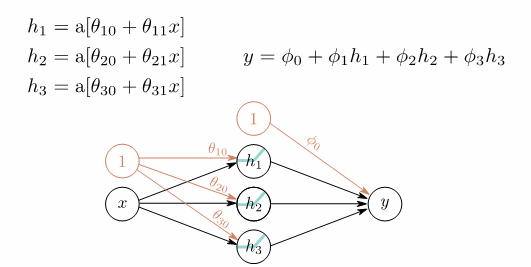

In [ ]:
matmul(input, model[0].weight.T) + model[0].bias

tensor([[-0.2748, -1.0490, -0.3957],
        [-2.2404,  0.7145, -0.8125],
        [ 0.4079, -1.6615, -0.2510],
        [-0.8638, -0.5205, -0.5206],
        [-1.1181, -0.2924, -0.5745],
        [-0.9841, -0.4126, -0.5461],
        [-0.1783, -1.1355, -0.3753],
        [-0.4094, -0.9282, -0.4243],
        [ 0.0613, -1.3505, -0.3245],
        [ 0.6314, -1.8619, -0.2036]], grad_fn=<AddBackward0>)

In [ ]:
relu(matmul(input, model[0].weight.T) + model[0].bias)

tensor([[0.0000, 0.0000, 0.0000],
        [0.0000, 0.7145, 0.0000],
        [0.4079, 0.0000, 0.0000],
        [0.0000, 0.0000, 0.0000],
        [0.0000, 0.0000, 0.0000],
        [0.0000, 0.0000, 0.0000],
        [0.0000, 0.0000, 0.0000],
        [0.0000, 0.0000, 0.0000],
        [0.0613, 0.0000, 0.0000],
        [0.6314, 0.0000, 0.0000]], grad_fn=<ReluBackward0>)

In [ ]:
matmul(relu(matmul(input, model[0].weight.T) + model[0].bias), model[2].weight.T) + model[2].bias

tensor([[0.5687],
        [0.7069],
        [0.7793],
        [0.5687],
        [0.5687],
        [0.5687],
        [0.5687],
        [0.5687],
        [0.6003],
        [0.8946]], grad_fn=<AddBackward0>)

---

# Cierre empírico: profundidad vs. anchura

El **Teorema de Aproximación Universal** garantiza que una red de una sola capa oculta (con suficiente anchura) puede aproximar cualquier función continua. Pero el teorema solo garantiza **existencia**, no eficiencia a la hora de conseguir la solución ni *aprendibilidad*: capacidad de generalización para datos nuevos.

El resultado de **Depth Efficiency** (Montúfar et al., 2014) demuestra que el número de regiones lineales de una red ReLU crece **polinomialmente** con la anchura $W$, pero **exponencialmente** con la profundidad $L$:

$$\#\text{regiones} = \mathcal{O}\!\left((W/d)^{(L-1)d}\right)$$

Es decir, componer capas (profundidad) permite *re-doblar* el espacio de entrada repetidamente, generando particiones exponencialmente más complejas con muchos menos parámetros que una red shallow equivalente.

Conviene matizar: el teorema acota la complejidad representable, no la MSE de validación. Más regiones lineales no implica directamente mejor generalización porque todo depende del método de optimización que  debe encontrar los pesos correctos, y la función objetivo debe requerir esa complejidad. El experimento que sigue es una exploración empírica inspirada por este resultado, no una verificación directa del teorema.




| Dimensión | Significado | Término |
|---|---|---|
| Número de capas ocultas ($L$) | Cuán **profunda** es la red | *Depth* / Profundidad |
| Neuronas por capa ($W$) | Cuán **ancha** es cada capa | *Width* / Anchura |

| Símbolo | Significado | En nuestro experimento |
|---|---|---|
| $L$ | Número de capas ocultas (profundidad) | 1 para Shallow, varias para Deep |
| $W$ | Neuronas por capa (anchura) | muchas en Wide, pocas en Narrow |
| $d$ | Dimensión del input | 2 (entrada $(x, y)$) |

## El experimento

Sobre la siguiente superficie 2D oscilatoria
$$f(x, y) = \frac{\sin(0.8\,(x^2 + y^2))}{(x^2 + y^2)^{0.9}}$$
entrenamos varias arquitecturas con el **mismo optimizador (Adam)** y el **mismo número de pasos**, registrando:
- pérdida de entrenamiento y validación
- *gap* de generalización
- un *Parameter Efficiency Score* heurístico: $\frac{1}{\text{MSE}_{\text{val}} \cdot \log_{10}(\#\text{params})}$

### Pregunta
> ¿Qué factor arquitectural (**anchura** o **profundidad**) produce mejores modelos en términos de generalización? ¿Cambia la respuesta cuando hay ruido?

## Librerías y setup


In [ ]:
import torch
import torch.nn as nn
import numpy as np
import matplotlib.pyplot as plt
import time
from mpl_toolkits.mplot3d import Axes3D
from sklearn.linear_model import LogisticRegression
from sklearn.datasets import make_circles
import seaborn as sns

# Set aesthetics for rigorous academic plotting
sns.set_theme(style="whitegrid", context="paper", font_scale=1.2)
plt.rcParams['figure.figsize'] = [8, 6]
plt.rcParams['figure.dpi'] = 150

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

## 1.2 De Perceptrons a aproximadores universales: El poder de la composición

### Generación de datos

Esta función genera la superficie 2D. Recibe una `semilla` para el ruido para garantizar que, al probar diferentes modelos con distintos niveles de ruido, el patrón espacial del ruido permanezca idéntico, lo que permite una comparación aislada de la amplitud del ruido y reproducibilidad en nuestros resultados.

In [ ]:
def generate_regression_data(mesh_size=40, noise_level=0.0, noise_seed=42):
    """Genera coordenadas 2D y objetivos para la función oscilatoria."""
    def f(x, y):
        return(torch.sin(0.8*(x**2 + y**2)) / (x**2 + y**2)**(0.9))

    t = torch.linspace(-3, 3, mesh_size)
    x, y = torch.meshgrid(t, t, indexing='ij')
    z = f(x, y)

    # Aplicamos la semilla y calculamos el ruido aplicado a la salida z
    torch.manual_seed(noise_seed)
    noise = torch.randn(mesh_size, mesh_size)
    z_noisy = z + noise_level * noise

    # Disminuimos en 1 dimensión para entrenamiento
    X = torch.vstack([x.ravel(), y.ravel()]).T
    y_true = z.ravel().unsqueeze(1)
    y_noisy = z_noisy.ravel().unsqueeze(1)

    return X.to(device), y_noisy.to(device), y_true.to(device), (x, y, z, z_noisy)

def plot_3d_surface(x, y, z, title="Surface Plot", ax=None):
    """Plot de una superficie 3D"""
    show_plot = False
    if ax is None:
        fig = plt.figure(figsize=(8, 6))
        ax = fig.add_subplot(111, projection='3d')
        show_plot = True

    ax.plot_surface(x.numpy(), y.numpy(), z.numpy(), cmap='viridis', edgecolor='none')
    ax.set_title(title)
    ax.set_xlabel('X')
    ax.set_ylabel('Y')
    ax.set_zlabel('Z')

    if show_plot:
        plt.tight_layout()
        plt.show()

### Definición de arquitectura flexible

Esta clase MLP crea redes neuronales dinámicamente a partir de una lista de dimensiones ocultas. Permite definir fácilmente redes poco profundas y amplias o profundas y estrechas, y extrae el número total de parámetros de forma dinámica.

La lista [10,10,10] indica que la estructura de capas ocultas de la red consta de tres capas ocultas de 10 unidades cada una. Por defecto, utiliza ReLU como función de activación.

In [ ]:
class FlexibleMLP(nn.Module):
    """MLP dinámico que permite profundidad y anchura arbitrarias."""
    def __init__(self, input_dim, hidden_dims, output_dim, activation=nn.ReLU):
        super().__init__()
        layers = []
        in_dim = input_dim
        for h_dim in hidden_dims:
            layers.append(nn.Linear(in_dim, h_dim))
            layers.append(activation())
            in_dim = h_dim
        layers.append(nn.Linear(in_dim, output_dim))
        self.network = nn.Sequential(*layers)

    def forward(self, x):
        return self.network(x)

    def count_parameters(self):
        return sum(p.numel() for p in self.parameters() if p.requires_grad)

### Método de entrenamiento

In [ ]:
def train_adam(model, X_train, y_train, X_val, y_val, steps=1000, lr=0.01, verbose=True):
    """Entrenamos a través de Adam, seguimiento de MSE, tiempo real y registro de progreso. Pasos es el número de épocas."""
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)
    criterion = nn.MSELoss()

    history = {'train_loss': [], 'val_loss': [], 'time': [], 'step': []}
    start_time = time.time()

    for step in range(steps):
        model.train()
        optimizer.zero_grad()
        output = model(X_train)
        loss = criterion(output, y_train)
        loss.backward()
        optimizer.step()

        # Métricas
        if step % (steps // 5) == 0 or step == steps - 1:
            with torch.no_grad():
                model.eval()
                val_loss = criterion(model(X_val), y_val).item()
                if verbose:
                    print(f"   Step {step:4d}/{steps} | Train MSE: {loss.item():.4f} | Val MSE: {val_loss:.4f}")

        with torch.no_grad():
            model.eval()
            history['train_loss'].append(loss.item())
            history['val_loss'].append(criterion(model(X_val), y_val).item())
            history['time'].append(time.time() - start_time)
            history['step'].append(step)

    return history

In [ ]:
def train_model(model, X_train, y_train, X_val, y_val,
                optimizer_class=torch.optim.Adam,
                optimizer_kwargs={'lr': 0.01},
                criterion=nn.MSELoss(),
                steps=1000, verbose=True):
    """
    Definición genérica si queremos usar otro optimizador
    """
    optimizer = optimizer_class(model.parameters(), **optimizer_kwargs)

    history = {'train_loss': [], 'val_loss': [], 'time': [], 'step': []}
    start_time = time.time()

    for step in range(steps):
        model.train()
        optimizer.zero_grad()
        output = model(X_train)
        loss = criterion(output, y_train)
        loss.backward()
        optimizer.step()

        # Record and print metrics
        if step % max(1, steps // 5) == 0 or step == steps - 1:
            with torch.no_grad():
                model.eval()
                val_loss = criterion(model(X_val), y_val).item()
                if verbose:
                    print(f"   Step {step:4d}/{steps} | Train Loss: {loss.item():.4f} | Val Loss: {val_loss:.4f}")

        with torch.no_grad():
            model.eval()
            history['train_loss'].append(loss.item())
            history['val_loss'].append(criterion(model(X_val), y_val).item())
            history['time'].append(time.time() - start_time)
            history['step'].append(step)

    return history

### Métodos de gráficos

In [ ]:
def plot_loss_vs_epochs(results, noise, architectures, ax=None):
    """Grafica la pérdida de validación frente a las épocas para un nivel de ruido específico."""
    show_plot = (ax is None)
    if show_plot: fig, ax = plt.subplots(figsize=(6, 4))

    for name in architectures.keys():
        hist = results[noise][name]['history']
        ax.plot(hist['step'], hist['val_loss'], label=f"{name} ({results[noise][name]['params']}p)")

    ax.set_title(f"Pérdida vs Épocas (Ruido: {noise})")
    ax.set_xlabel("Pasos de Adam")
    ax.set_ylabel("MSE de Validación")
    ax.set_yscale('log')
    ax.legend()

    if show_plot: plt.show()

def plot_loss_vs_time(results, noise, architectures, ax=None):
    """Grafica la pérdida de validación frente al tiempo de reloj."""
    show_plot = (ax is None)
    if show_plot: fig, ax = plt.subplots(figsize=(6, 4))

    for name in architectures.keys():
        hist = results[noise][name]['history']
        ax.plot(hist['time'], hist['val_loss'], label=name)

    ax.set_title(f"Pérdida vs Tiempo (Ruido: {noise})")
    ax.set_xlabel("Tiempo de reloj (s)")
    ax.set_ylabel("MSE de Validación")
    ax.set_yscale('log')
    ax.legend()

    if show_plot: plt.show()

def plot_parameter_efficiency(results, noise, architectures, ax=None):
    """Grafica un diagrama de barras de la puntuación de eficiencia de parámetros. Corrige la advertencia de hue de sns."""
    show_plot = (ax is None)
    if show_plot: fig, ax = plt.subplots(figsize=(6, 4))

    names = list(architectures.keys())
    scores = [results[noise][name]['eff_score'] for name in names]

    # Asigna 'x' a 'hue' y establece legend=False para cumplir con la nueva API de Seaborn
    sns.barplot(x=names, y=scores, hue=names, palette='viridis', legend=False, ax=ax)

    ax.set_title(f"Eficiencia de Parámetros (Ruido: {noise})")
    ax.set_ylabel("Puntuación de Eficiencia")

    if show_plot: plt.show()

def plot_ground_truth_and_noise(meshes, noise_level):
    """Muestra la función verdadera subyacente y los datos de entrenamiento ruidosos uno al lado del otro."""
    x_mesh, y_mesh, z_true, z_noisy = meshes
    fig = plt.figure(figsize=(14, 5))

    # Función verdadera
    ax1 = fig.add_subplot(121, projection='3d')
    ax1.plot_surface(x_mesh.numpy(), y_mesh.numpy(), z_true.numpy(), cmap='viridis', edgecolor='none')
    ax1.set_title("Datos reales (Función Objetivo)")
    ax1.set_zlim(-2, 2)

    # Datos ruidosos
    ax2 = fig.add_subplot(122, projection='3d')
    ax2.plot_surface(x_mesh.numpy(), y_mesh.numpy(), z_noisy.numpy(), cmap='viridis', edgecolor='none')
    ax2.set_title(f"Datos de Entrenamiento (Nivel de Ruido: {noise_level})")
    ax2.set_zlim(-2, 2)

    plt.tight_layout()
    plt.show()

def plot_train_val_curves(results, noise, model_name, ax=None):
    """Grafica la pérdida de entrenamiento vs validación para UN modelo especificado."""
    show_plot = (ax is None)
    if show_plot: fig, ax = plt.subplots(figsize=(6, 4))

    hist = results[noise][model_name]['history']

    ax.plot(hist['step'], hist['train_loss'], label="MSE de Entrenamiento", linestyle='--', color='blue')
    ax.plot(hist['step'], hist['val_loss'], label="MSE de Validación", linestyle='-', color='orange')

    ax.set_title(f"Dinámica de Entrenamiento de {model_name}\n(Ruido: {noise})")
    ax.set_xlabel("Épocas de Adam")
    ax.set_ylabel("Pérdida MSE")
    ax.set_yscale('log')
    ax.legend()

    if show_plot: plt.show()

def plot_noisy_dataset(meshes, noise_level, ax=None):
    """Grafica SOLO el conjunto de datos de entrenamiento ruidoso para un único nivel de ruido."""
    x_mesh, y_mesh, _, z_noisy = meshes

    show_plot = (ax is None)
    if show_plot:
        fig = plt.figure(figsize=(8, 6))
        ax = fig.add_subplot(111, projection='3d')

    ax.plot_surface(x_mesh.numpy(), y_mesh.numpy(), z_noisy.numpy(), cmap='viridis', edgecolor='none')
    ax.set_title(f"Datos de Entrenamiento\n(Nivel de Ruido: {noise_level})")
    ax.set_xlabel('X')
    ax.set_ylabel('Y')
    ax.set_zlabel('Z')
    ax.set_zlim(-2, 2)

    if show_plot:
        plt.tight_layout()
        plt.show()

def plot_single_model_prediction(results, noise, model_name, meshes, ax=None):
    """Grafica la predicción de superficie 3D para estrictamente UN modelo y UN nivel de ruido."""
    x_mesh, y_mesh, _, _ = meshes
    preds = results[noise][model_name]['preds']

    show_plot = (ax is None)
    if show_plot:
        fig = plt.figure(figsize=(8, 6))
        ax = fig.add_subplot(111, projection='3d')

    ax.plot_surface(x_mesh.numpy(), y_mesh.numpy(), preds.numpy(), cmap='magma', edgecolor='none')
    ax.set_title(f"Predicción: {model_name}\n(Entrenado con Ruido: {noise})")
    ax.set_xlabel('X')
    ax.set_ylabel('Y')
    ax.set_zlabel('Z')
    ax.set_zlim(-2, 2)

    if show_plot:
        plt.tight_layout()
        plt.show()

def plot_single_model_loss_vs_epochs(results, noise, model_name, ax=None):
    """Grafica la pérdida de entrenamiento y validación vs épocas (pasos) para estrictamente UN modelo."""
    show_plot = (ax is None)
    if show_plot: fig, ax = plt.subplots(figsize=(6, 4))

    hist = results[noise][model_name]['history']

    ax.plot(hist['step'], hist['train_loss'], label="MSE de Entrenamiento", linestyle='--', color='blue')
    ax.plot(hist['step'], hist['val_loss'], label="MSE de Validación", linestyle='-', color='orange')

    ax.set_title(f"Pérdida vs Épocas: {model_name}\n(Ruido: {noise})")
    ax.set_xlabel("Épocas de Adam")
    ax.set_ylabel("Pérdida MSE")
    ax.set_yscale('log')
    ax.legend()

    if show_plot: plt.show()

def plot_single_model_loss_vs_time(results, noise, model_name, ax=None):
    """Grafica la pérdida de entrenamiento y validación vs tiempo de reloj para estrictamente UN modelo."""
    show_plot = (ax is None)
    if show_plot: fig, ax = plt.subplots(figsize=(6, 4))

    hist = results[noise][model_name]['history']

    ax.plot(hist['time'], hist['train_loss'], label="MSE de Entrenamiento", linestyle='--', color='blue')
    ax.plot(hist['time'], hist['val_loss'], label="MSE de Validación", linestyle='-', color='orange')

    ax.set_title(f"Pérdida vs Tiempo: {model_name}\n(Ruido: {noise})")
    ax.set_xlabel("Tiempo de reloj (segundos)")
    ax.set_ylabel("Pérdida MSE")
    ax.set_yscale('log')
    ax.legend()

    if show_plot: plt.show()

### Experimentos

Estos fragmentos de código muestran cómo usar todas las funciones de graficación para algunas configuraciones de ruido en nuestro conjunto de datos y arquitecturas.

In [ ]:
def run_capacity_experiment(
        architectures,
        noise_levels,
        steps=1000,
        lr=0.01,
        mode="estable"
):
    """
        mode: Nos permite determinar si queremos comparar para las misma cantidad de iteraciones (estable) u optimal (el mejor para cada uno)
    """
    results = {}
    for noise in noise_levels:
        print(f"\n{'.'*40}\nRunning Noise Level: {noise}\n{'.'*40}")
        results[noise] = {}
        X, y_train, y_test, meshes = generate_regression_data(noise_level=noise)

        for name, dims in architectures.items():
            print(f"-> Training Architecture: {name}")
            # Definir modelo en cada ejecución
            model = FlexibleMLP(input_dim=2, hidden_dims=dims, output_dim=1).to(device)
            params = model.count_parameters()

            hist = train_adam(model, X, y_train, X, y_test, steps=steps, lr=lr)

            with torch.no_grad():
                preds = model(X).cpu().reshape((40, 40))

            # Conseguimos dónde fue el mejor modelo y analizamos en base a ese punto
            if mode == "optimal":
                val_losses = np.asarray(hist['val_loss'])
                train_losses = np.asarray(hist['train_loss'])
                best_step = int(np.argmin(val_losses))
                best_val = float(val_losses[best_step])
                train_at_best = float(train_losses[best_step])

                eff_score = 1.0 / (best_val * np.log10(params))
                results[noise][name] = {
                    'history': hist,
                    'params': params,
                    'preds': preds,
                    'eff_score': eff_score,
                    'gap': best_val - train_at_best,
                }
            elif mode == "estable":
                final_val = hist['val_loss'][-1]
                eff_score = 1.0 / (final_val * np.log10(params))

                results[noise][name] = {
                    'history': hist, 'params': params, 'preds': preds,
                    'eff_score': eff_score, 'gap': final_val - hist['train_loss'][-1]
                }
    return results, meshes

### Definición de arquitecturas

In [ ]:
architectures = {
    "Shallow-Wide": [256],
    "Deep-Narrow": [16, 16, 16, 16],
    "Deep-Wide": [64, 64, 64, 64]
}
noise_levels = [0.0, 0.1, 0.5, 1.0]

#### Visualización del ruido

Antes de entrenar los modelos veamos la visualización del ruido

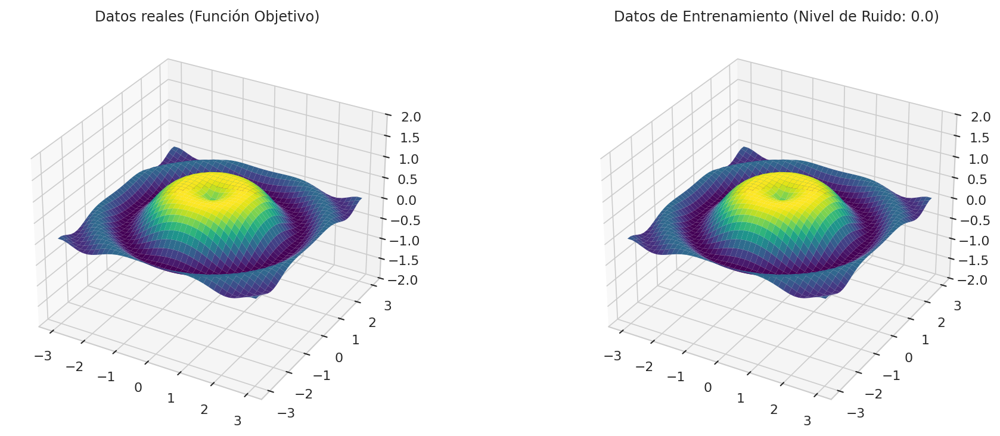

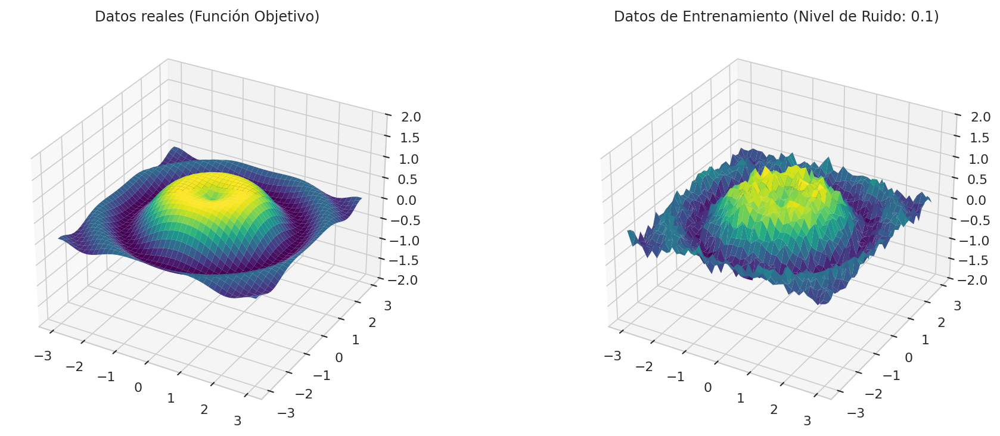

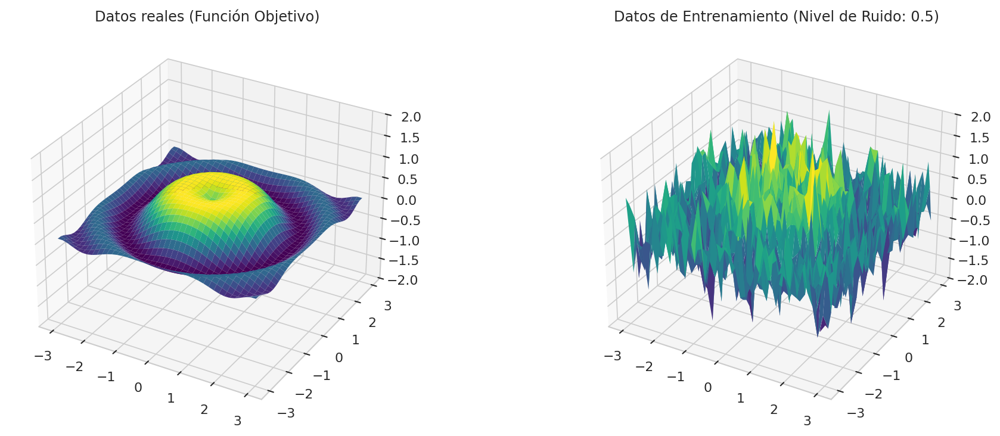

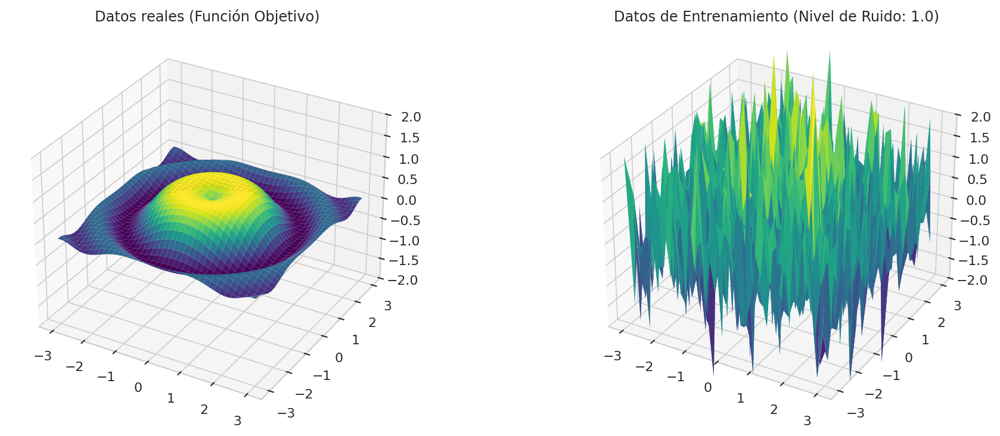

In [ ]:
for noise in noise_levels:
    _, _, _, meshes_preview = generate_regression_data(noise_level=noise)
    plot_ground_truth_and_noise(meshes_preview, noise_level=noise)



#### Entrenamiento de los modelos

In [ ]:
results, meshes = run_capacity_experiment(architectures, noise_levels, steps=1500, lr=0.001)


........................................
Running Noise Level: 0.0
........................................
-> Training Architecture: Shallow-Wide
   Step    0/1500 | Train MSE: 0.4948 | Val MSE: 0.3988
   Step  300/1500 | Train MSE: 0.0263 | Val MSE: 0.0262
   Step  600/1500 | Train MSE: 0.0152 | Val MSE: 0.0152
   Step  900/1500 | Train MSE: 0.0109 | Val MSE: 0.0109
   Step 1200/1500 | Train MSE: 0.0081 | Val MSE: 0.0081
   Step 1499/1500 | Train MSE: 0.0062 | Val MSE: 0.0062
-> Training Architecture: Deep-Narrow
   Step    0/1500 | Train MSE: 0.1707 | Val MSE: 0.1642
   Step  300/1500 | Train MSE: 0.0043 | Val MSE: 0.0042
   Step  600/1500 | Train MSE: 0.0012 | Val MSE: 0.0012
   Step  900/1500 | Train MSE: 0.0010 | Val MSE: 0.0010
   Step 1200/1500 | Train MSE: 0.0009 | Val MSE: 0.0009
   Step 1499/1500 | Train MSE: 0.0008 | Val MSE: 0.0008
-> Training Architecture: Deep-Wide
   Step    0/1500 | Train MSE: 0.0802 | Val MSE: 0.0775
   Step  300/1500 | Train MSE: 0.0011 | Val MSE: 0.

In [ ]:
results, meshes = run_capacity_experiment(architectures, noise_levels, steps=1500, lr=0.01)



........................................
Running Noise Level: 0.0
........................................
-> Training Architecture: Shallow-Wide
   Step    0/1500 | Train MSE: 0.4948 | Val MSE: 0.2339
   Step  300/1500 | Train MSE: 0.0093 | Val MSE: 0.0093
   Step  600/1500 | Train MSE: 0.0051 | Val MSE: 0.0051
   Step  900/1500 | Train MSE: 0.0042 | Val MSE: 0.0042
   Step 1200/1500 | Train MSE: 0.0135 | Val MSE: 0.0053
   Step 1499/1500 | Train MSE: 0.0036 | Val MSE: 0.0036
-> Training Architecture: Deep-Narrow
   Step    0/1500 | Train MSE: 0.1707 | Val MSE: 0.1203
   Step  300/1500 | Train MSE: 0.0007 | Val MSE: 0.0007
   Step  600/1500 | Train MSE: 0.0006 | Val MSE: 0.0007
   Step  900/1500 | Train MSE: 0.0002 | Val MSE: 0.0002
   Step 1200/1500 | Train MSE: 0.0001 | Val MSE: 0.0001
   Step 1499/1500 | Train MSE: 0.0001 | Val MSE: 0.0001
-> Training Architecture: Deep-Wide
   Step    0/1500 | Train MSE: 0.0802 | Val MSE: 0.0800
   Step  300/1500 | Train MSE: 0.0008 | Val MSE: 0.

#### Configuración con parámetro mode

In [ ]:
results, meshes = run_capacity_experiment(architectures, noise_levels, steps=1500, lr=0.01, mode="optimal")


........................................
Running Noise Level: 0.0
........................................
-> Training Architecture: Shallow-Wide
   Step    0/1500 | Train MSE: 0.4948 | Val MSE: 0.2339
   Step  300/1500 | Train MSE: 0.0136 | Val MSE: 0.0139
   Step  600/1500 | Train MSE: 0.0051 | Val MSE: 0.0051
   Step  900/1500 | Train MSE: 0.0047 | Val MSE: 0.0047
   Step 1200/1500 | Train MSE: 0.0036 | Val MSE: 0.0036
   Step 1499/1500 | Train MSE: 0.0045 | Val MSE: 0.0047
-> Training Architecture: Deep-Narrow
   Step    0/1500 | Train MSE: 0.1707 | Val MSE: 0.1204
   Step  300/1500 | Train MSE: 0.0007 | Val MSE: 0.0007
   Step  600/1500 | Train MSE: 0.0004 | Val MSE: 0.0003
   Step  900/1500 | Train MSE: 0.0004 | Val MSE: 0.0003
   Step 1200/1500 | Train MSE: 0.0002 | Val MSE: 0.0001
   Step 1499/1500 | Train MSE: 0.0001 | Val MSE: 0.0001
-> Training Architecture: Deep-Wide
   Step    0/1500 | Train MSE: 0.0802 | Val MSE: 0.0800
   Step  300/1500 | Train MSE: 0.0008 | Val MSE: 0.

#### Curvas de entrenamiento para todos los ruidos

In [ ]:
from itertools import product


In [ ]:
architectures

{'Shallow-Wide': [256],
 'Deep-Narrow': [16, 16, 16, 16],
 'Deep-Wide': [64, 64, 64, 64]}

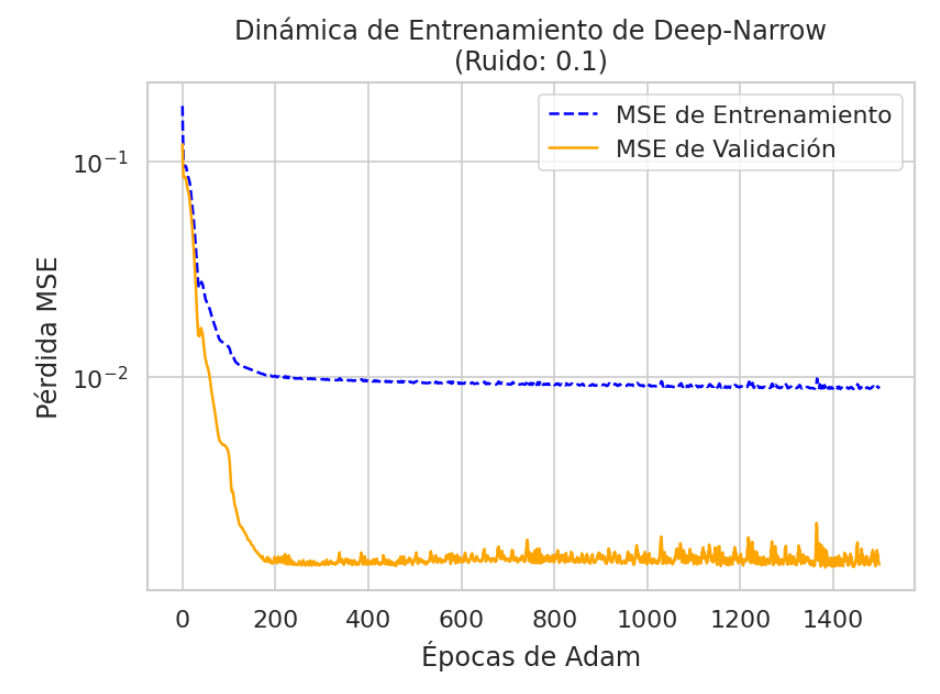

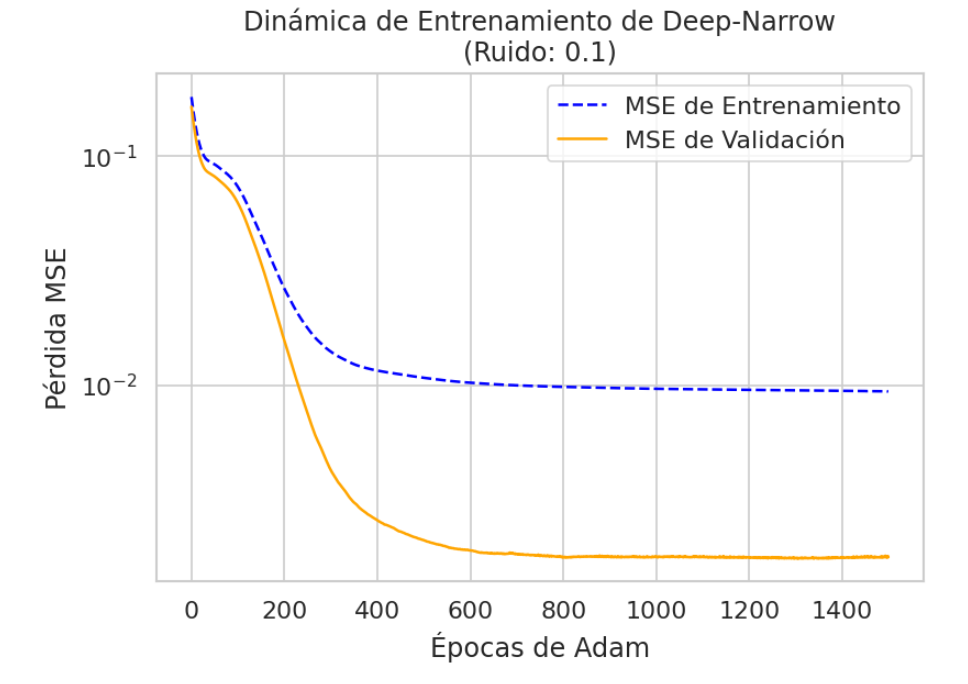

#### Salida con mode=`optimal`

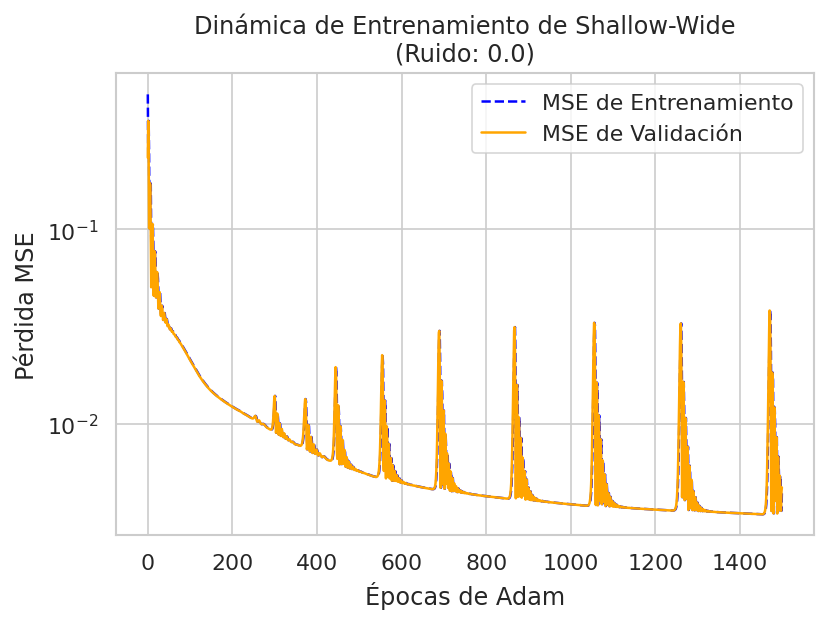

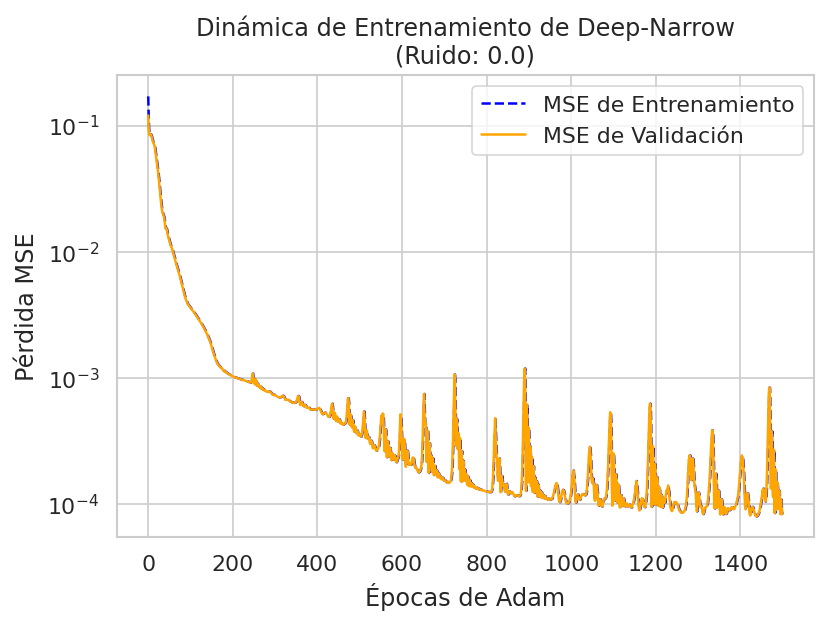

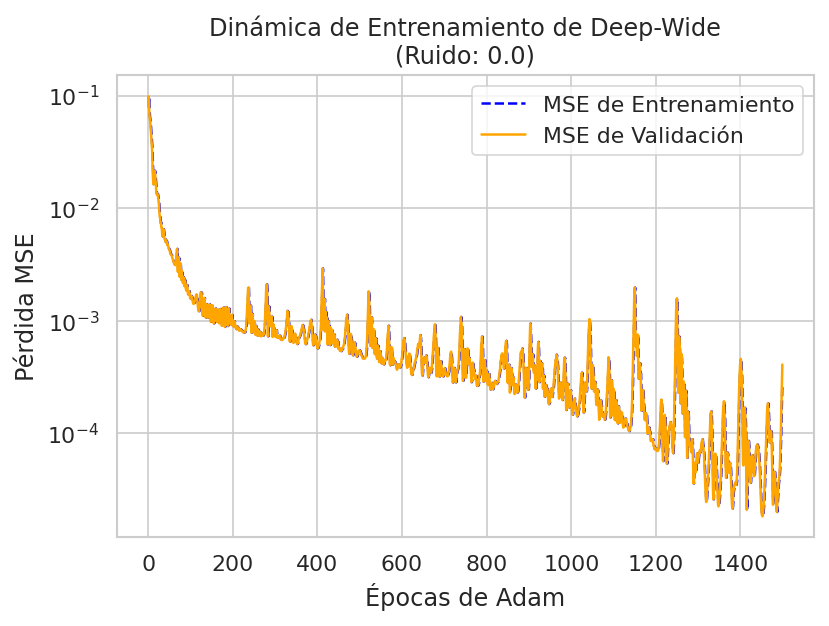

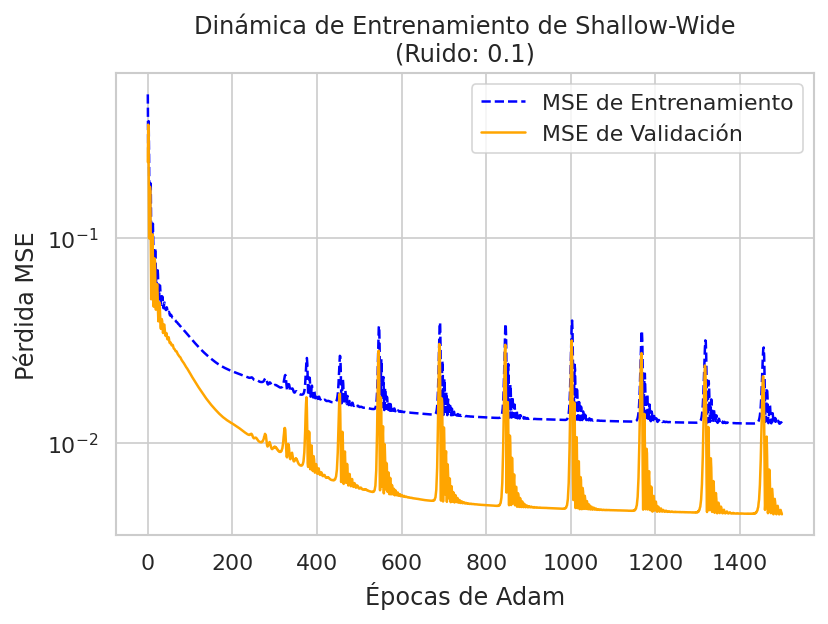

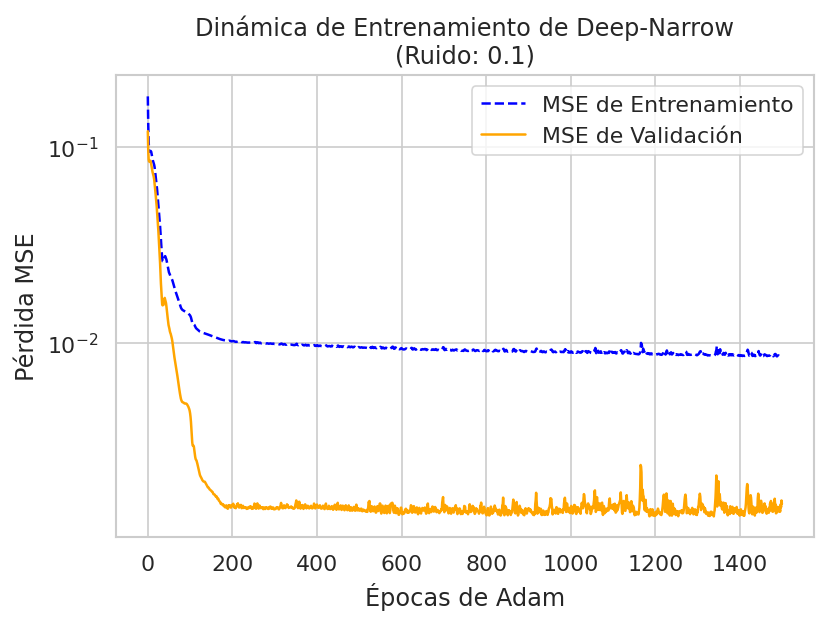

...

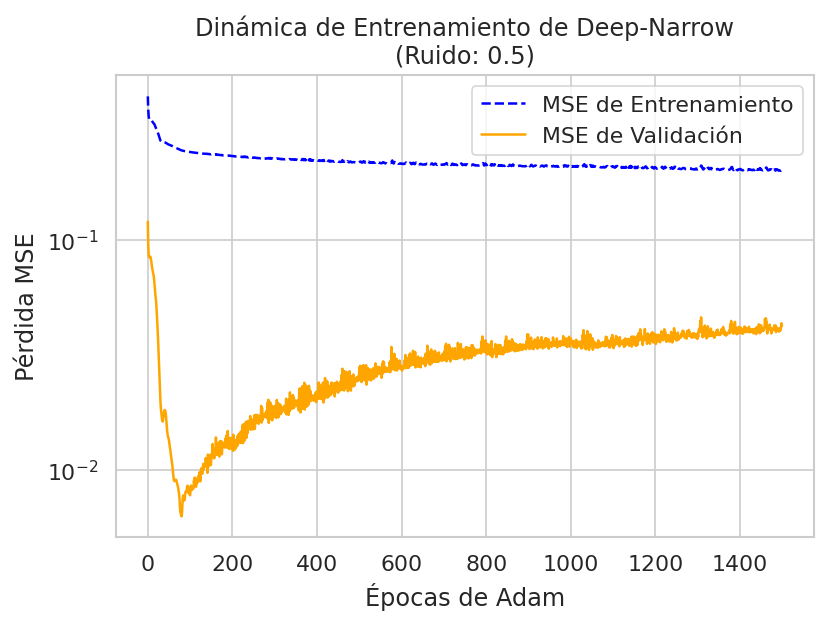

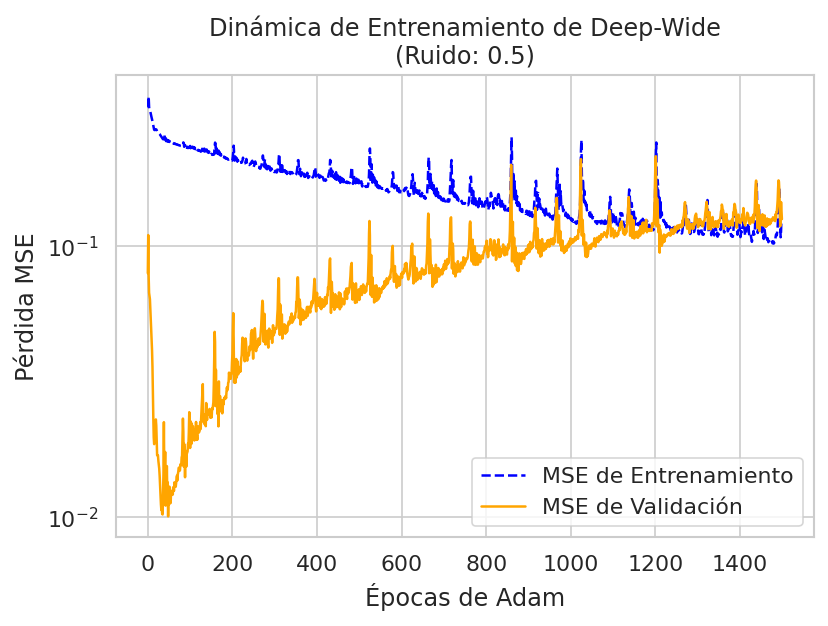

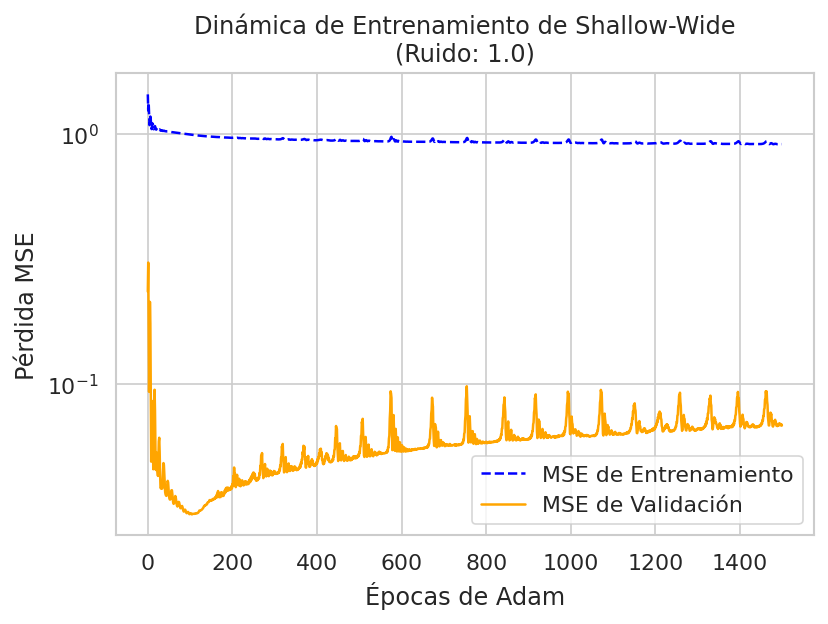

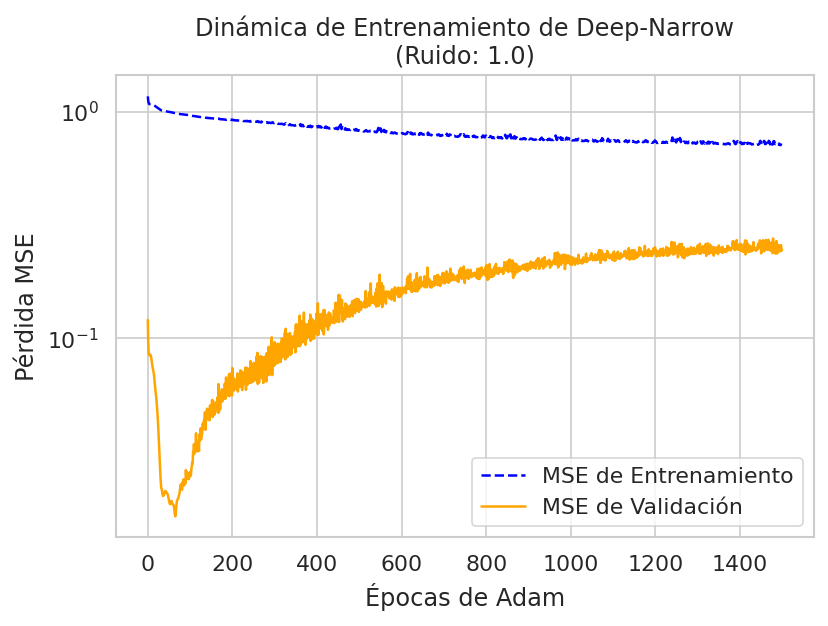

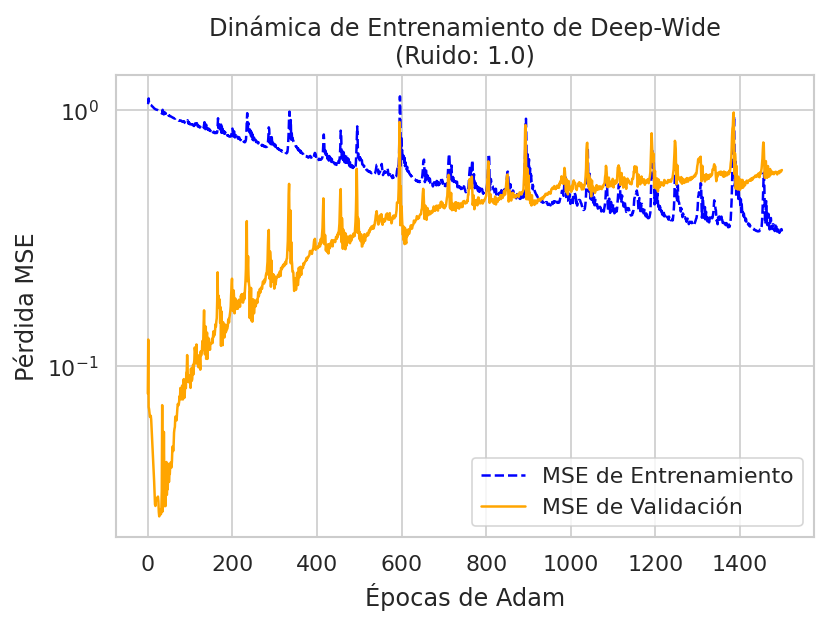

In [ ]:
for noise, arch in product(noise_levels, architectures.keys()):
    plot_train_val_curves(results, noise=noise, model_name=arch)

#### Salida para AdamW con step 0.001

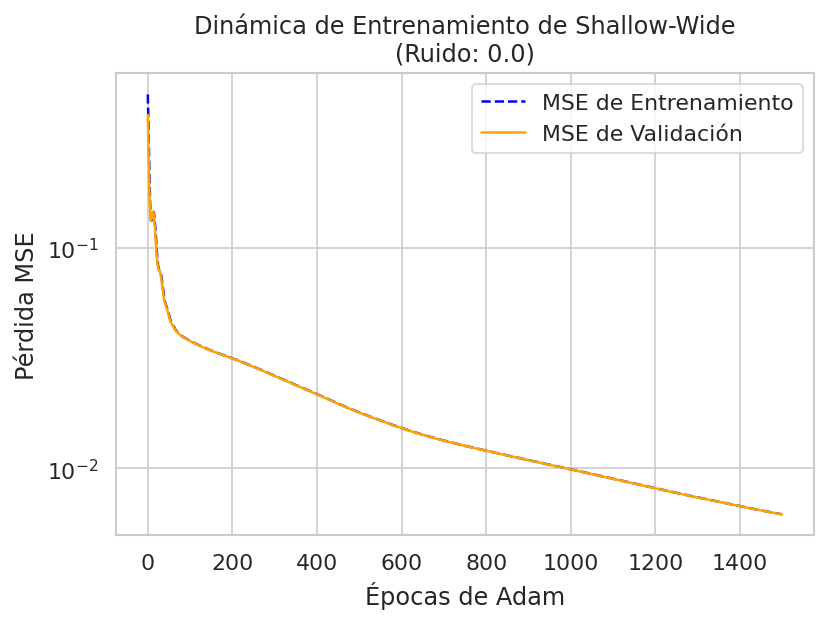

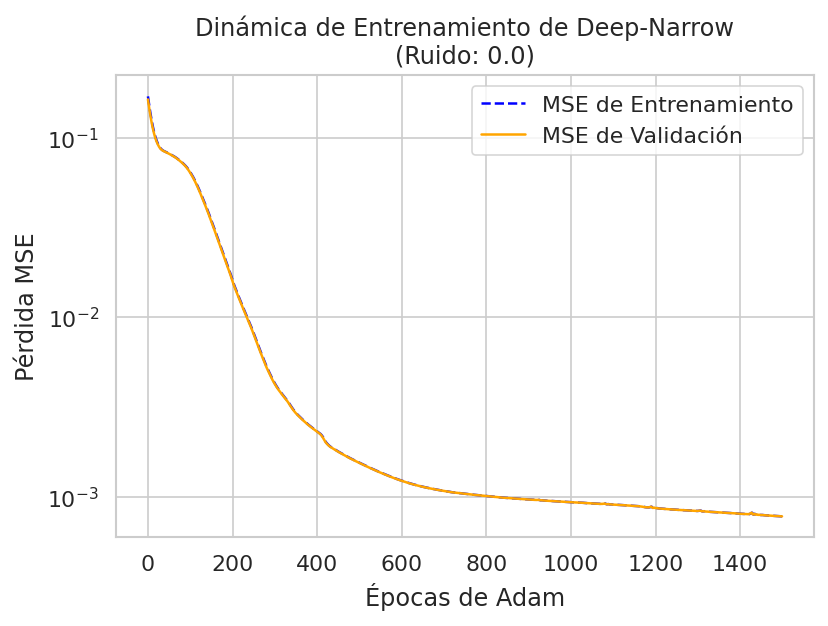

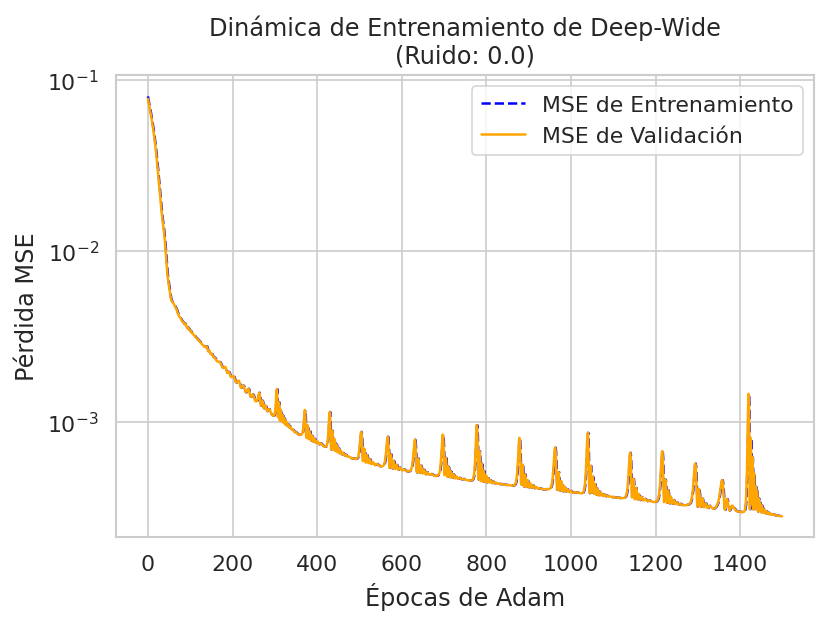

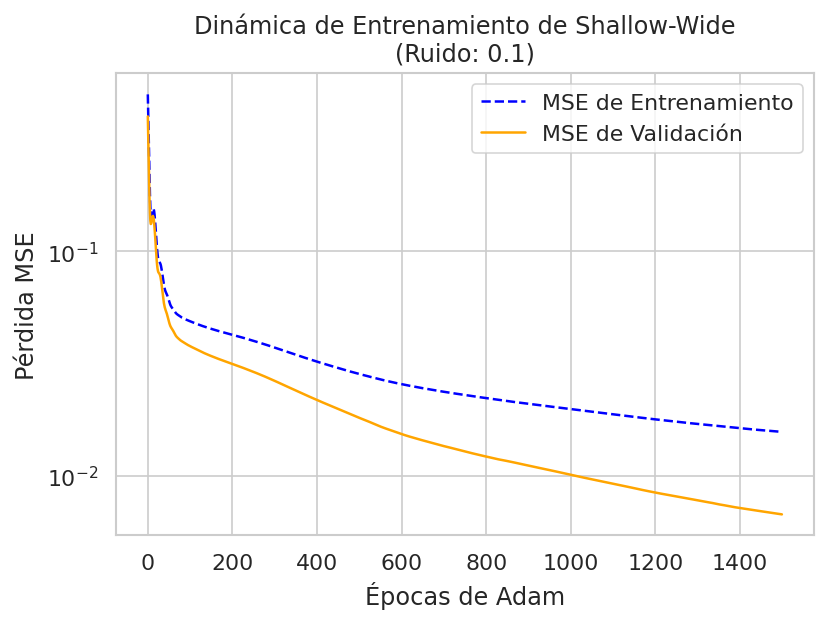

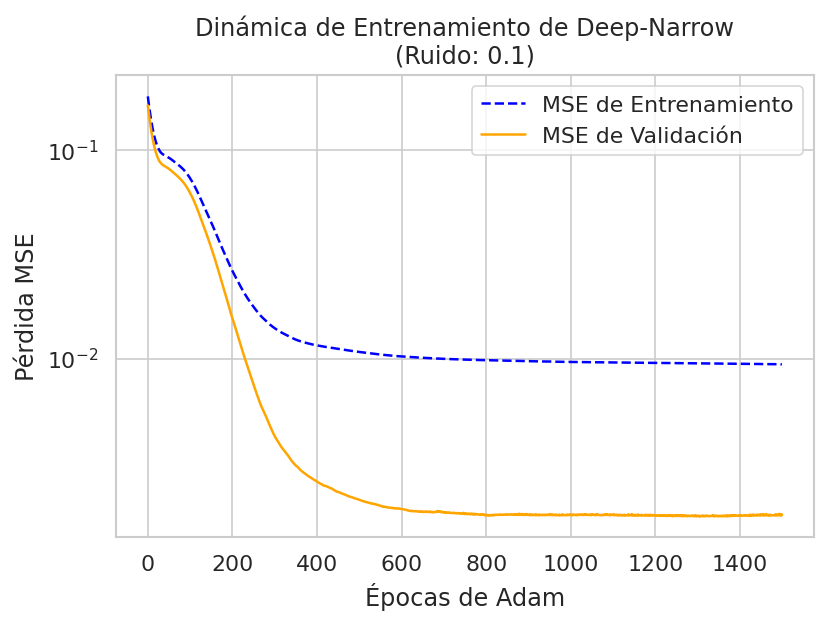

...

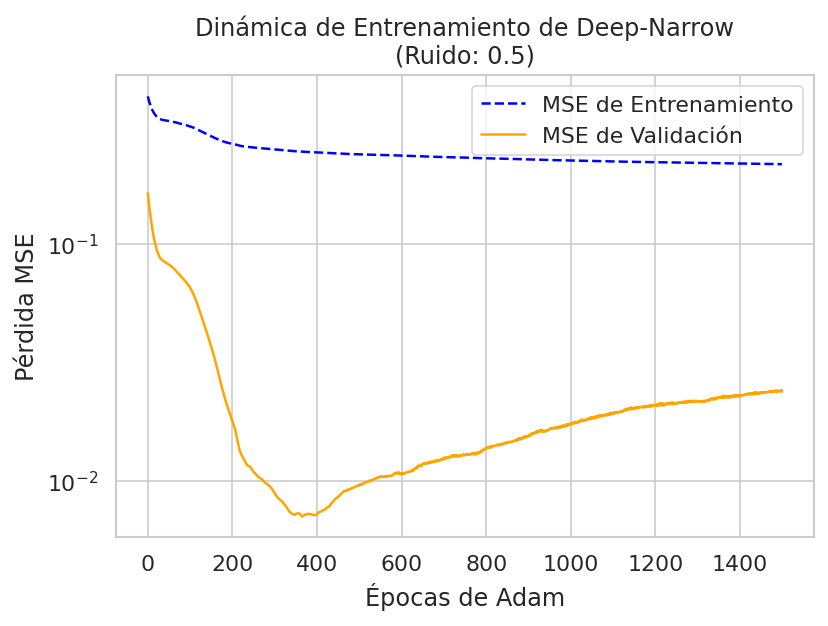

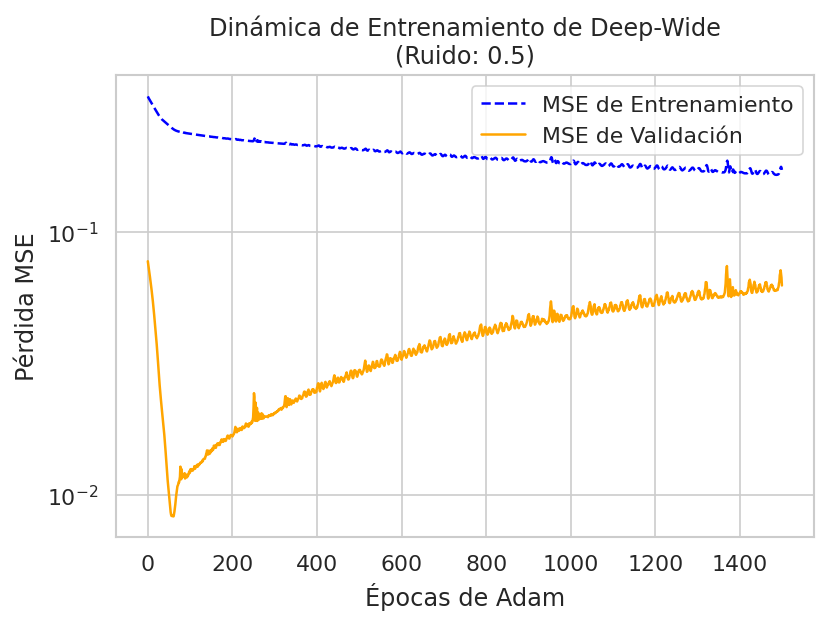

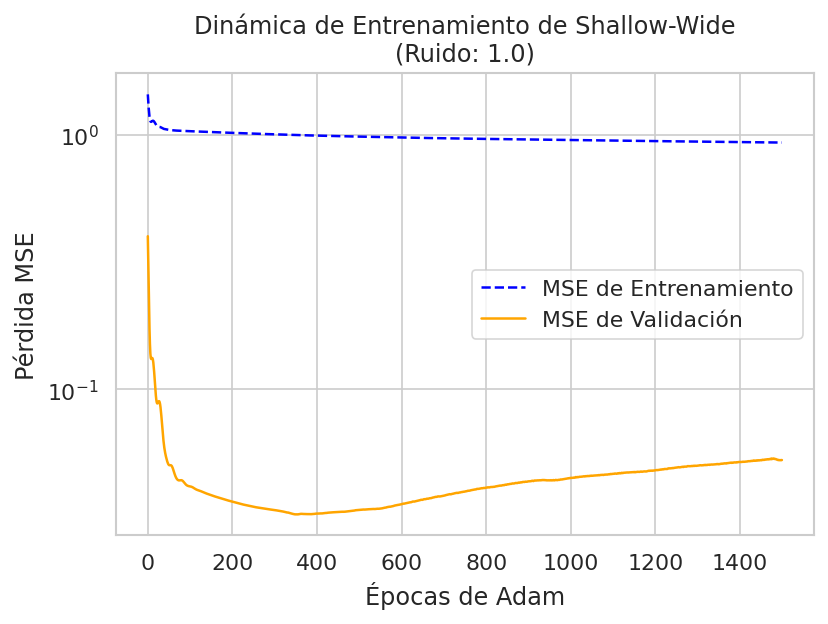

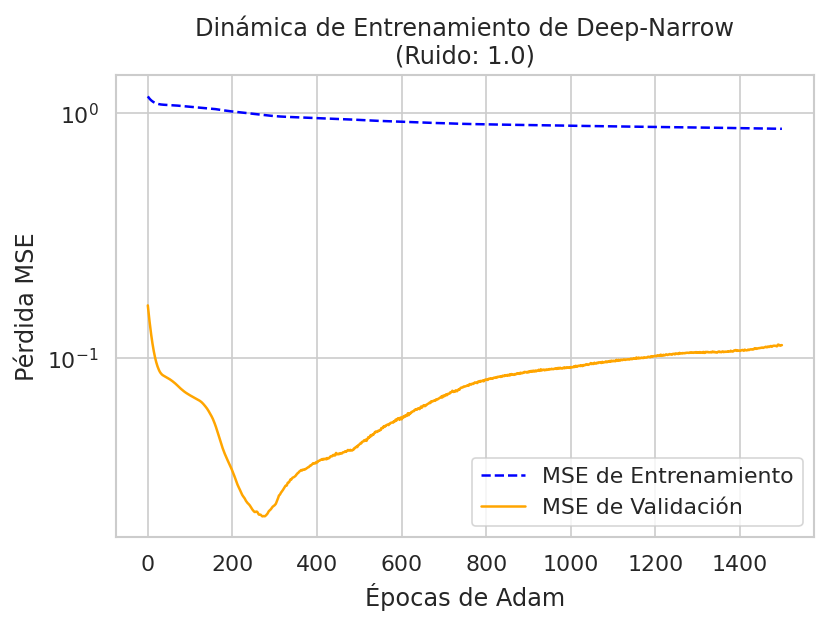

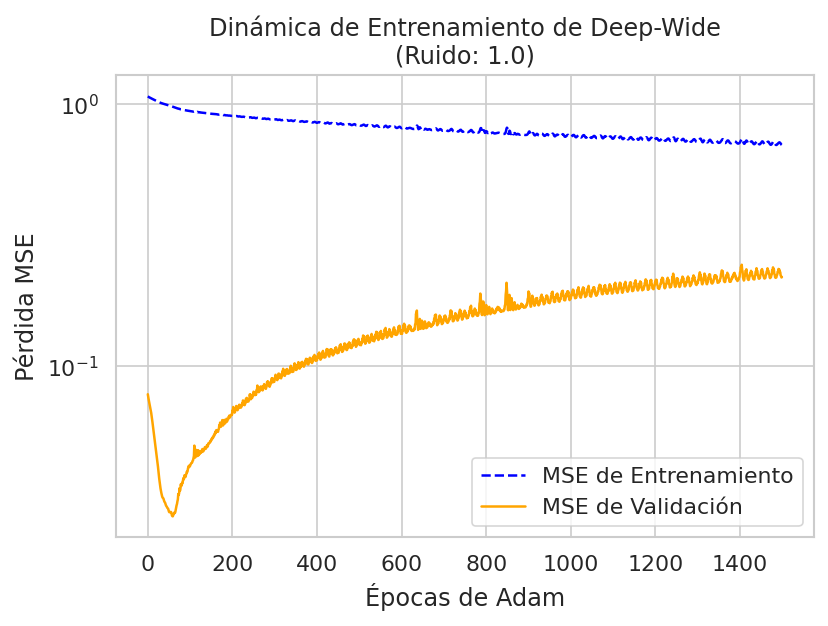

In [ ]:
for noise, arch in product(noise_levels, architectures.keys()):
    plot_train_val_curves(results, noise=noise, model_name=arch)

#### Salida para AdamW

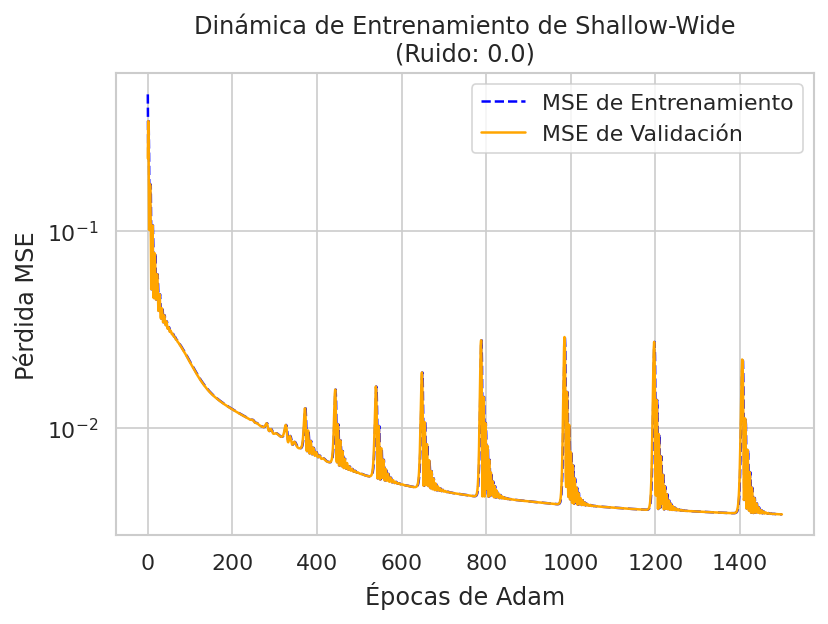

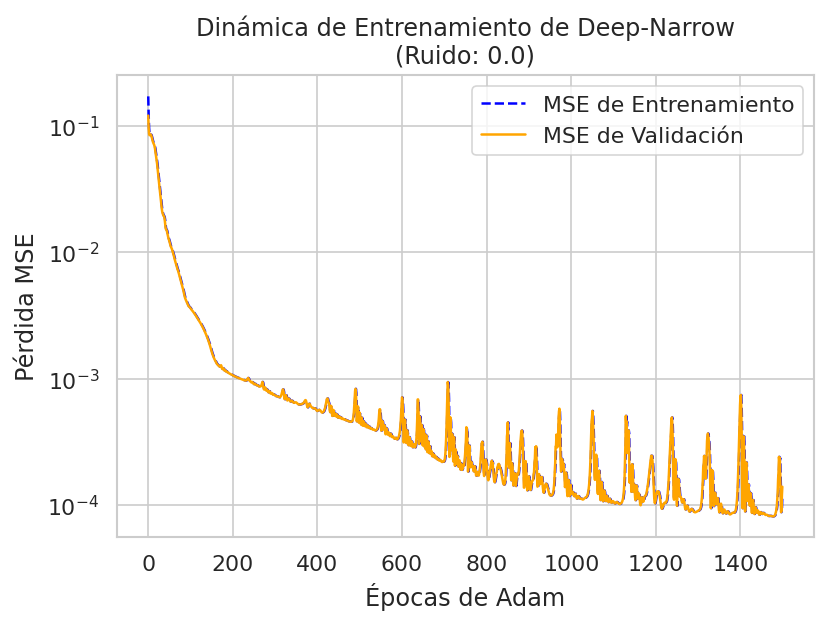

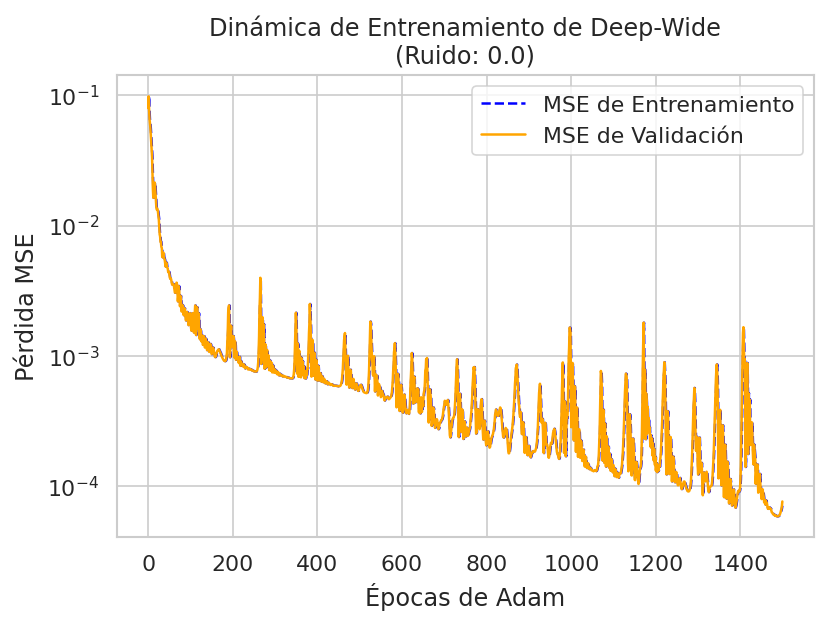

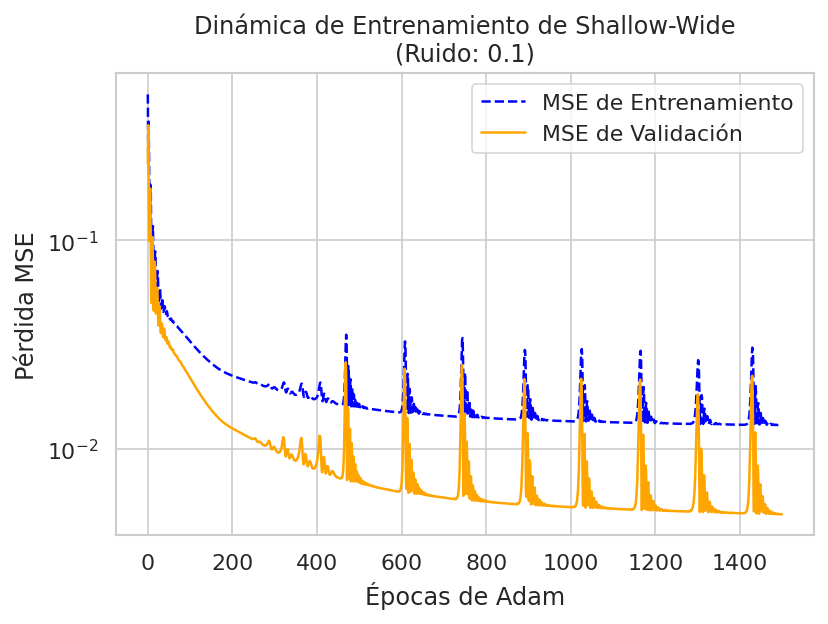

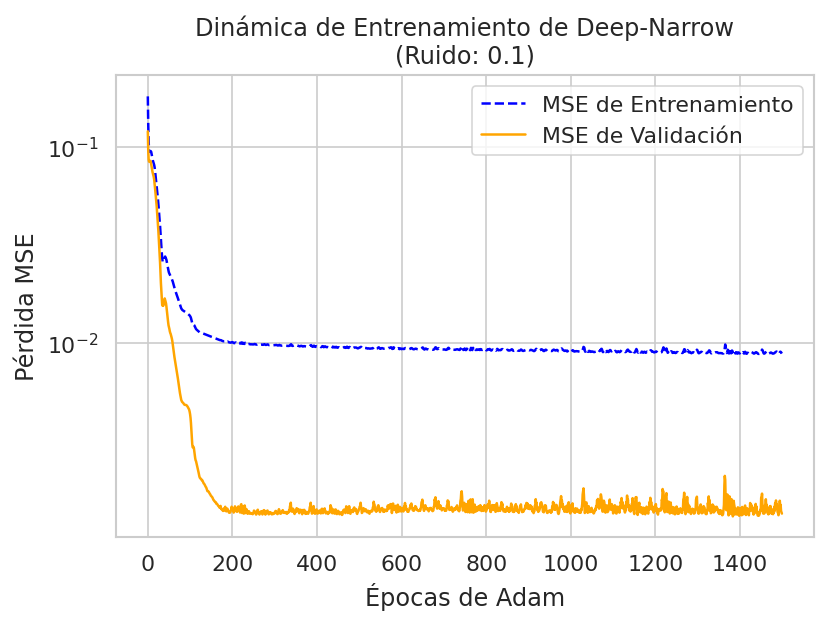

...

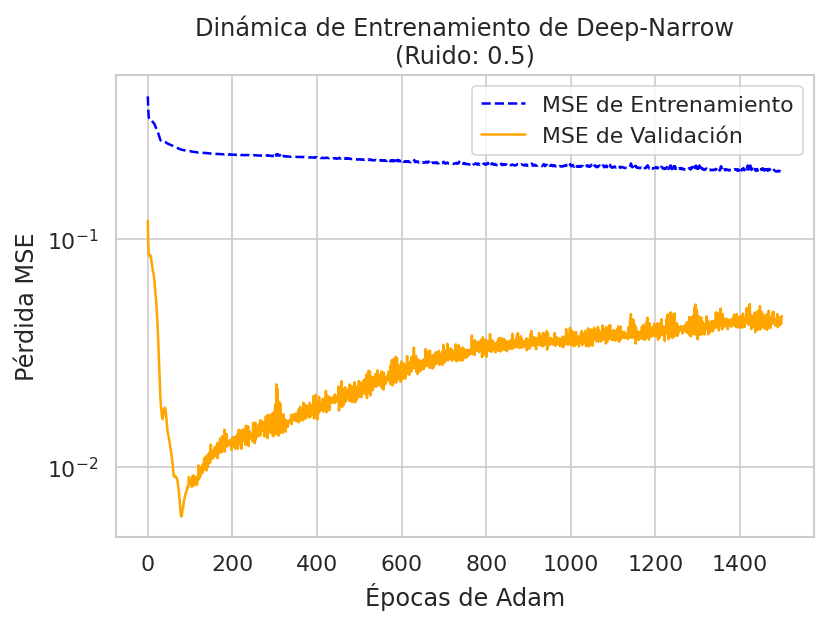

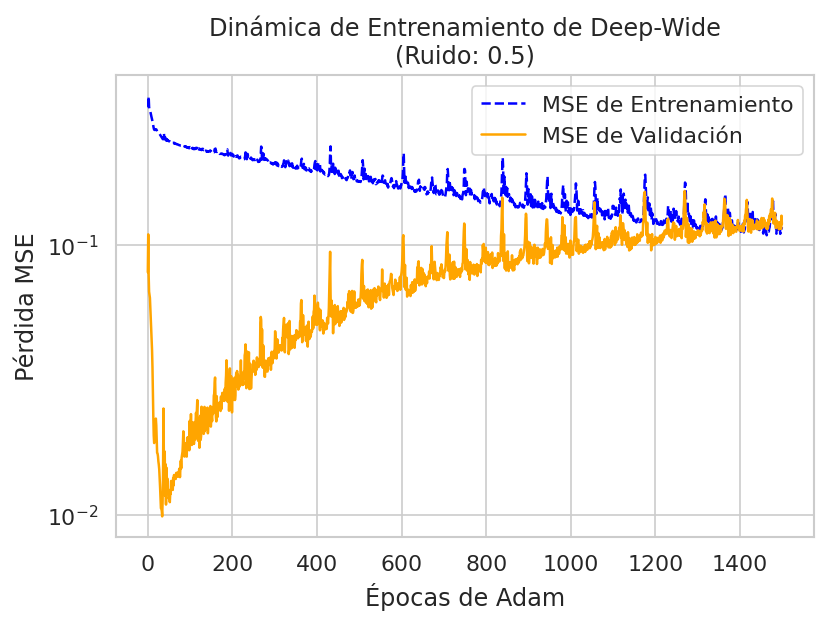

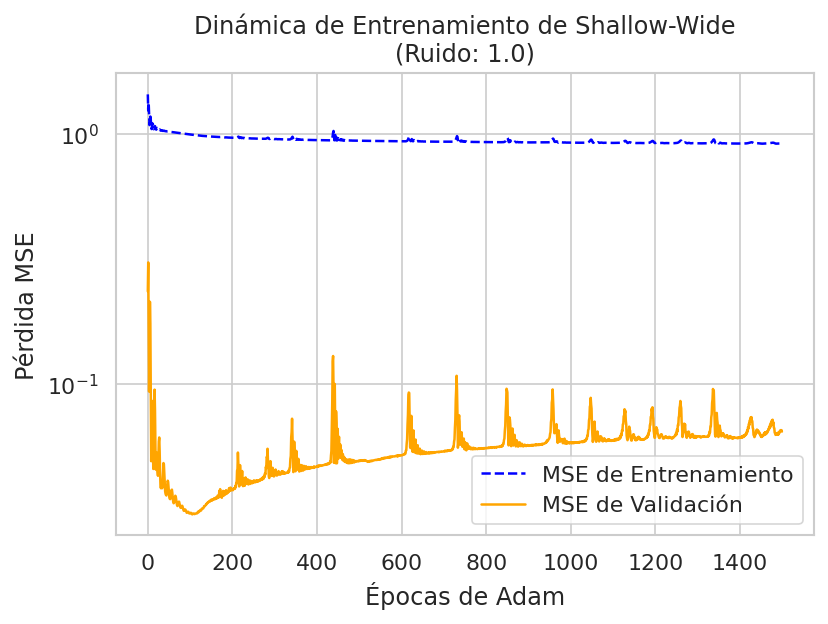

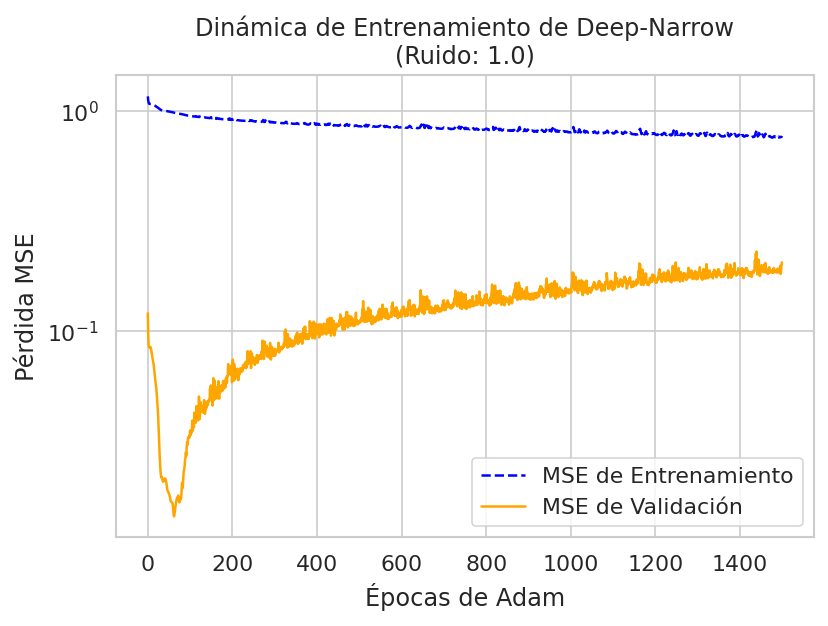

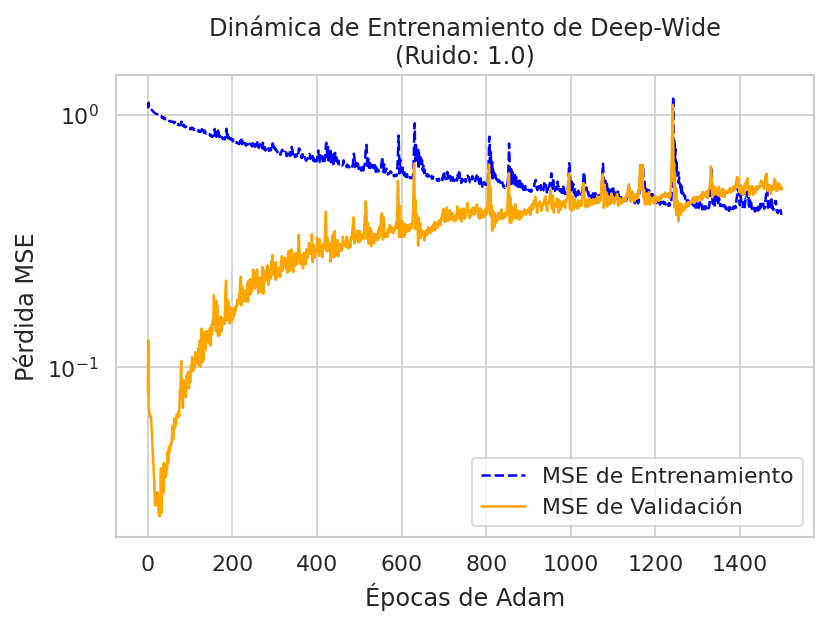

In [ ]:
for noise, arch in product(noise_levels, architectures.keys()):
    plot_train_val_curves(results, noise=noise, model_name=arch)

#### Salida para Adam

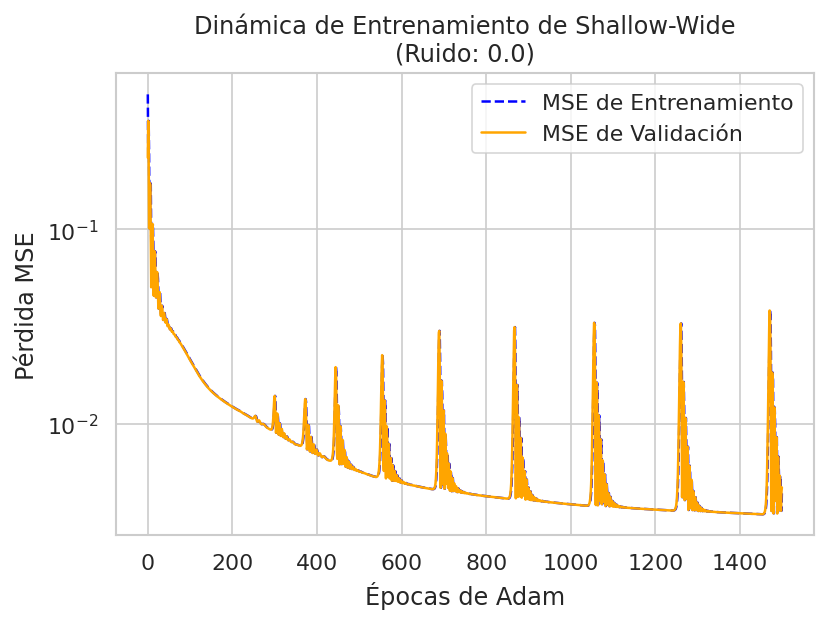

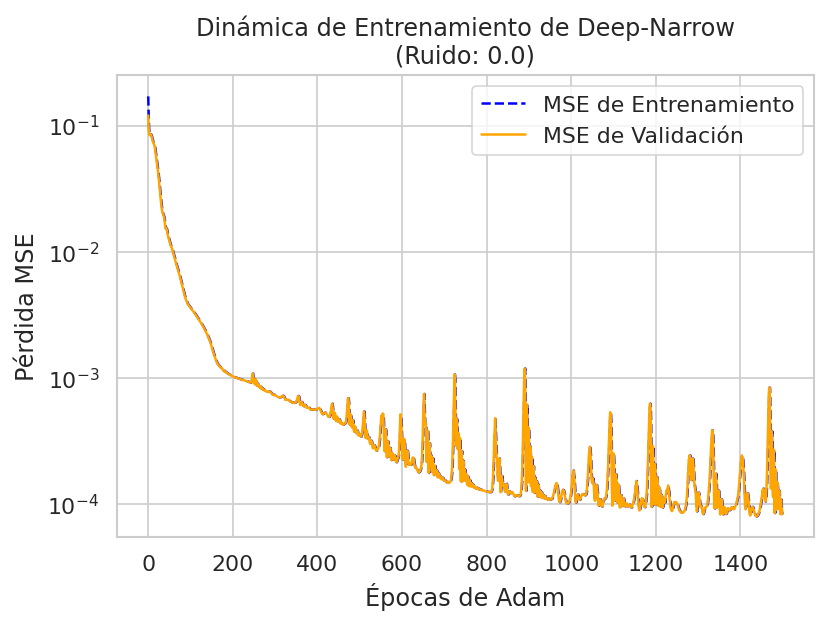

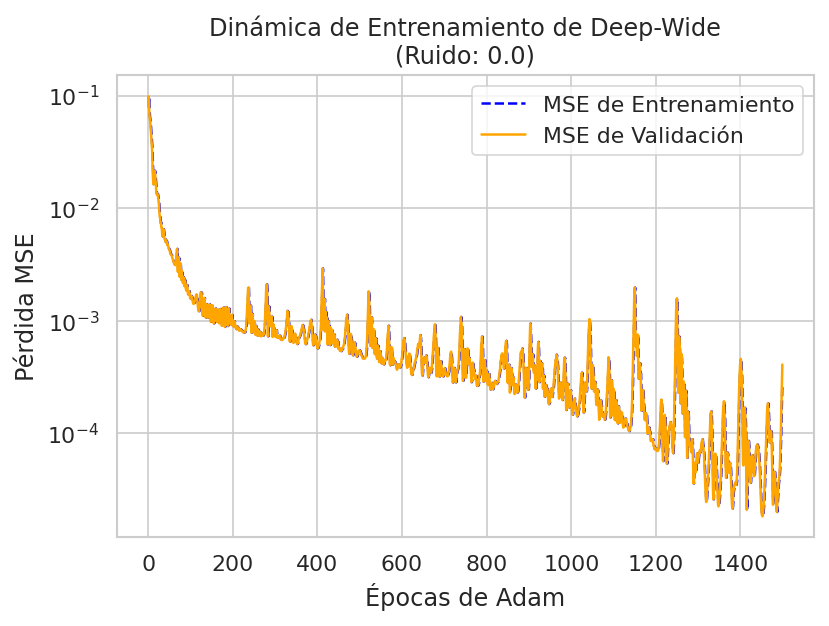

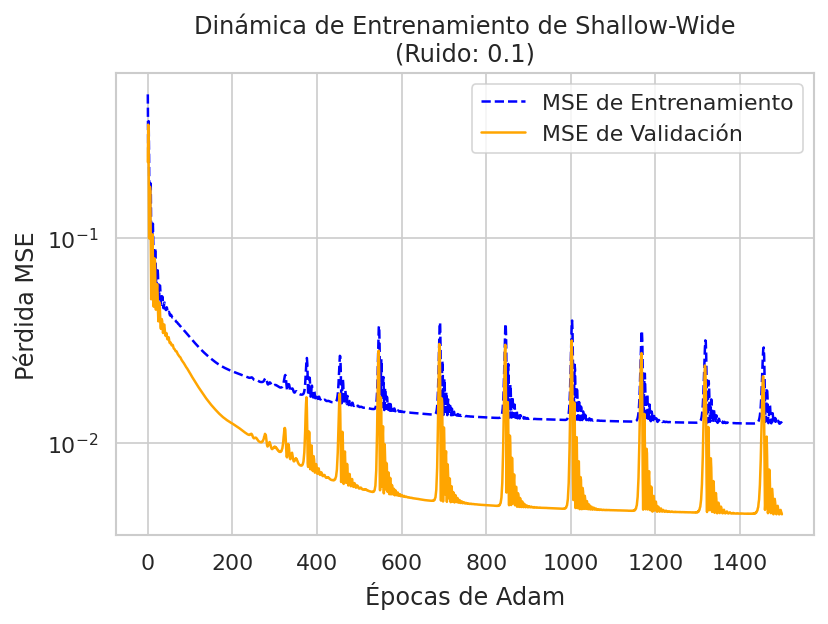

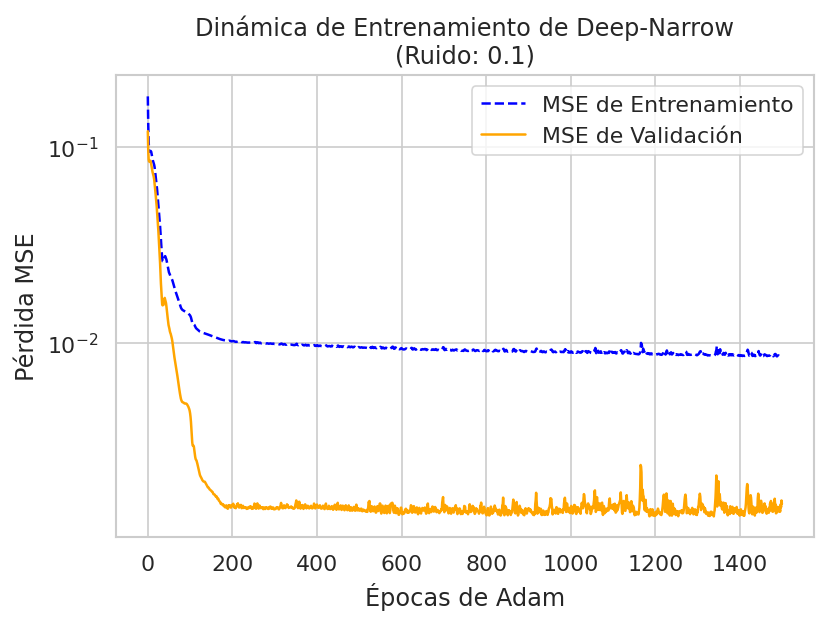

...

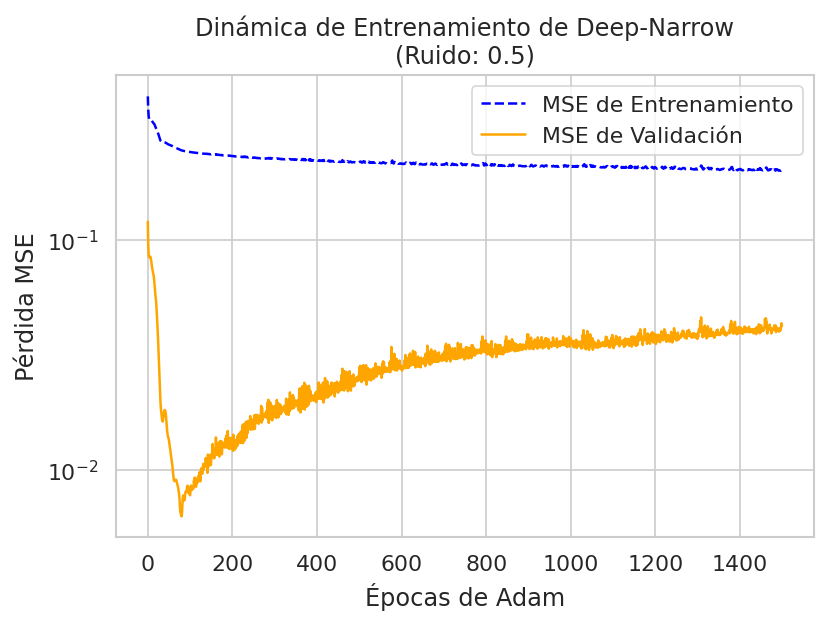

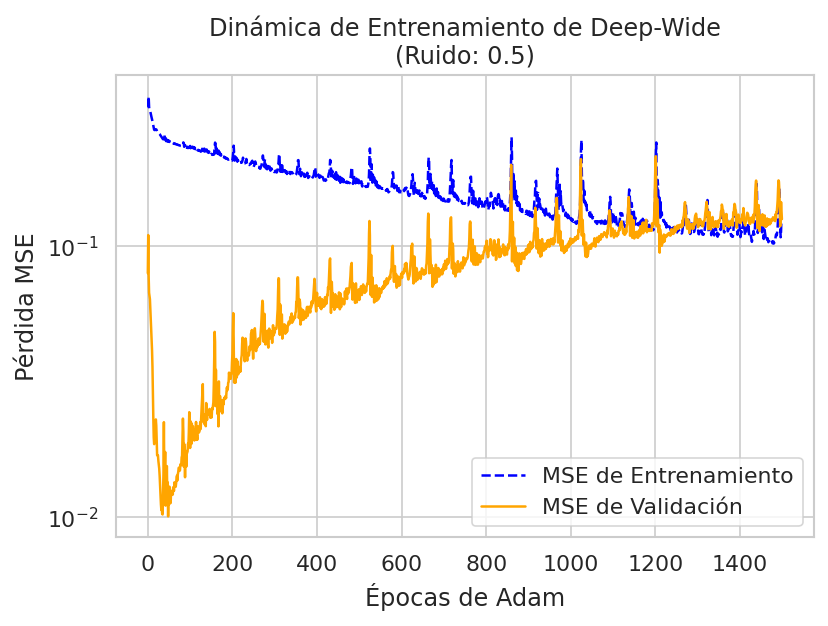

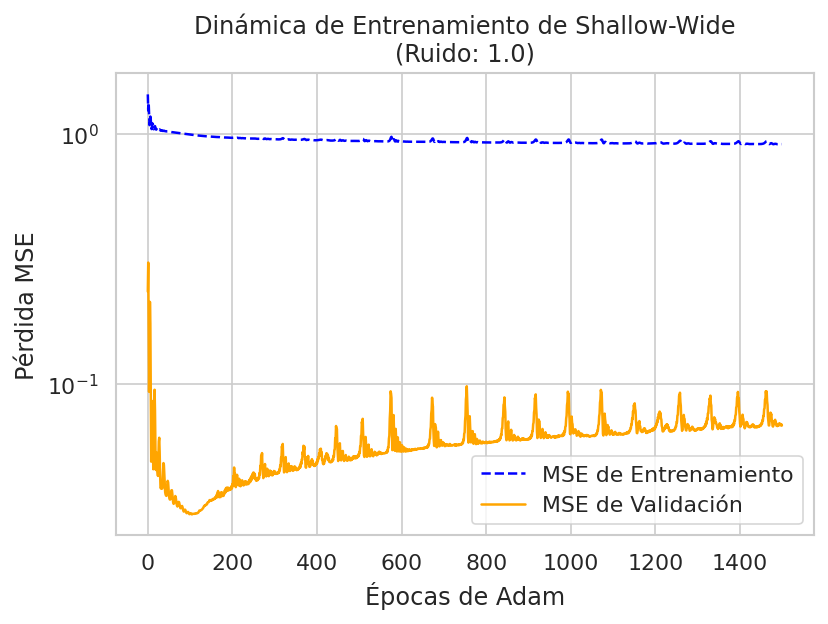

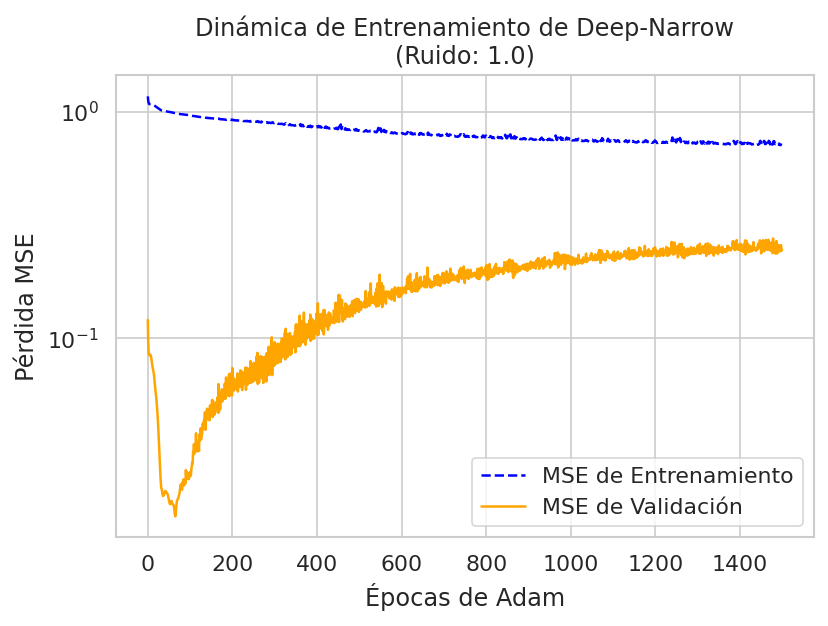

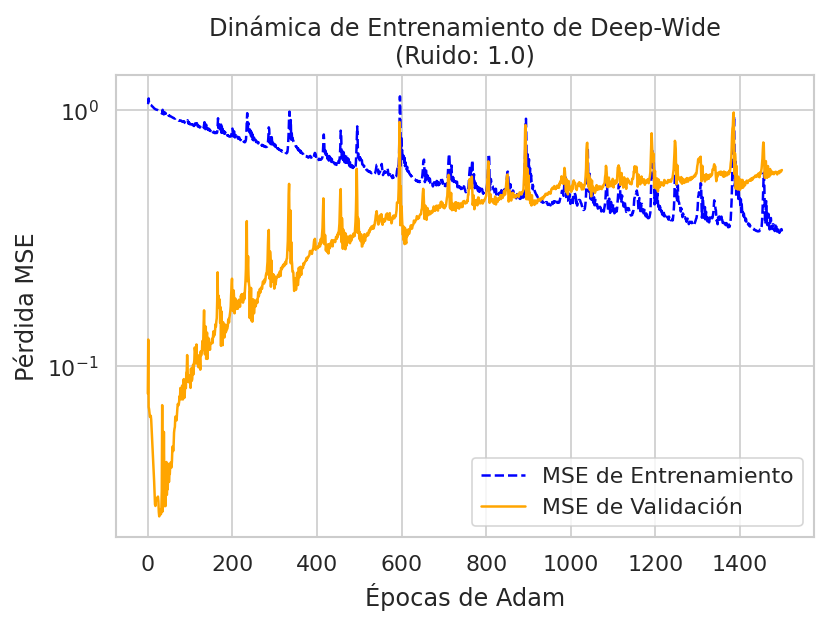

In [ ]:
for noise, arch in product(noise_levels, architectures.keys()):
    plot_train_val_curves(results, noise=noise, model_name=arch)

#### Grid comparativo con modo optimal

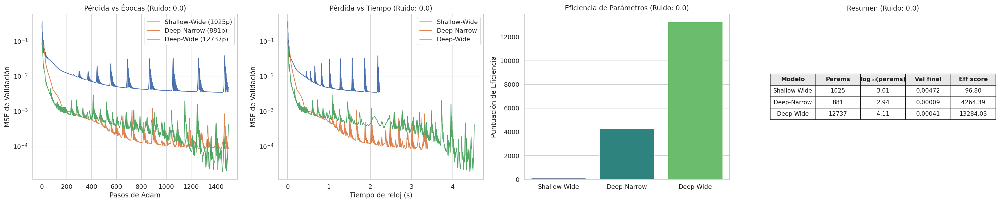

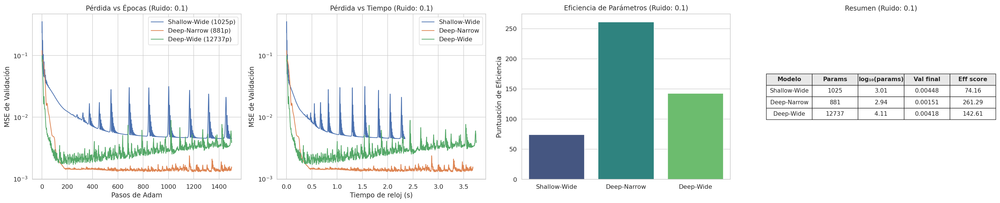

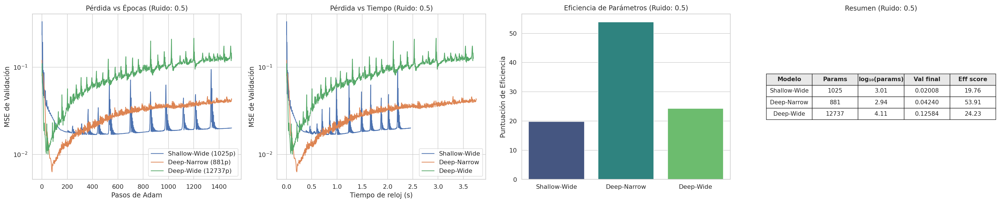

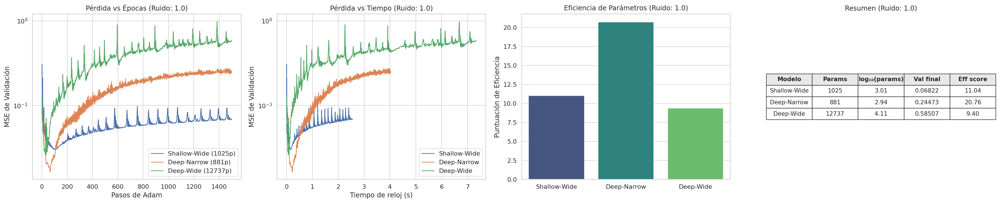

In [ ]:
import pandas as pd
import numpy as np

for noise in noise_levels:
    fig, axes = plt.subplots(1, 4, figsize=(24, 5),
                             gridspec_kw={'width_ratios': [1, 1, 1, 1.1]})
    plot_loss_vs_epochs(results, noise, architectures, ax=axes[0])
    plot_loss_vs_time(results, noise, architectures, ax=axes[1])
    plot_parameter_efficiency(results, noise, architectures, ax=axes[2])

    # Construir tabla resumen para este nivel de ruido
    rows = []
    for name in architectures.keys():
        params = results[noise][name]['params']
        final_val = results[noise][name]['history']['val_loss'][-1]
        eff = results[noise][name]['eff_score']
        rows.append([
            name,
            f"{params}",
            f"{np.log10(params):.2f}",
            f"{final_val:.5f}",
            f"{eff:.2f}",
        ])

    col_labels = ["Modelo", "Params", "log₁₀(params)", "Val final", "Eff score"]

    axes[3].axis('off')
    axes[3].set_title(f"Resumen (Ruido: {noise})")
    table = axes[3].table(
        cellText=rows,
        colLabels=col_labels,
        loc='center',
        cellLoc='center',
        colLoc='center',
    )
    table.auto_set_font_size(False)
    table.set_fontsize(10)
    table.scale(1, 1.6)

    # Estilizar encabezado
    for j in range(len(col_labels)):
        cell = table[0, j]
        cell.set_text_props(weight='bold')
        cell.set_facecolor('#e8e8e8')

    plt.tight_layout()
    plt.show()

#### Grid comparativo para todos los modelos con configuración standard

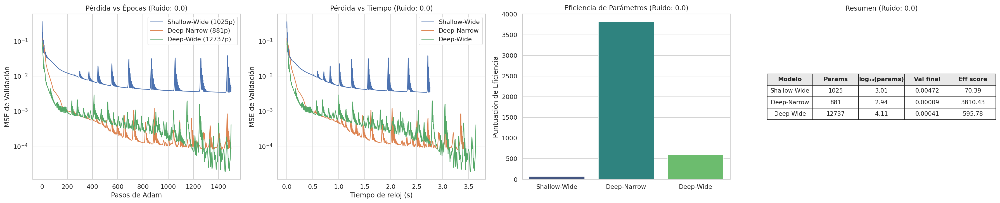

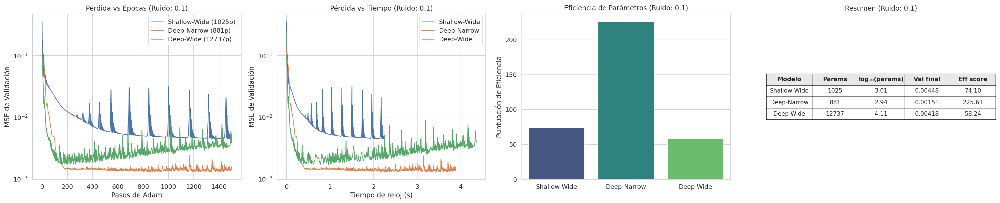

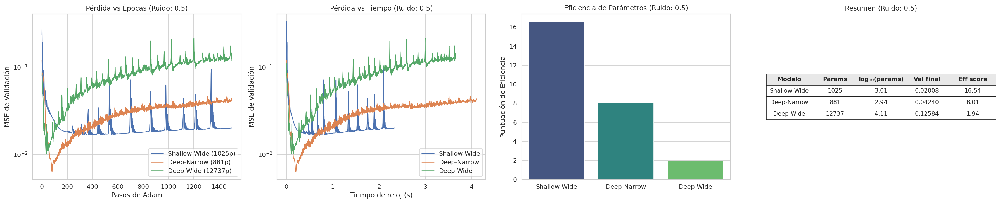

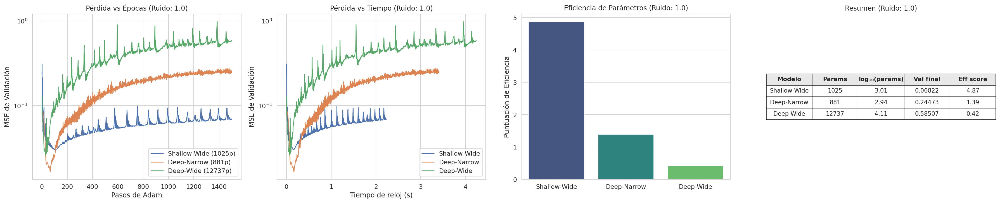

In [ ]:
import pandas as pd
import numpy as np

for noise in noise_levels:
    fig, axes = plt.subplots(1, 4, figsize=(24, 5),
                             gridspec_kw={'width_ratios': [1, 1, 1, 1.1]})
    plot_loss_vs_epochs(results, noise, architectures, ax=axes[0])
    plot_loss_vs_time(results, noise, architectures, ax=axes[1])
    plot_parameter_efficiency(results, noise, architectures, ax=axes[2])

    # Construir tabla resumen para este nivel de ruido
    rows = []
    for name in architectures.keys():
        params = results[noise][name]['params']
        final_val = results[noise][name]['history']['val_loss'][-1]
        eff = results[noise][name]['eff_score']
        rows.append([
            name,
            f"{params}",
            f"{np.log10(params):.2f}",
            f"{final_val:.5f}",
            f"{eff:.2f}",
        ])

    col_labels = ["Modelo", "Params", "log₁₀(params)", "Val final", "Eff score"]

    axes[3].axis('off')
    axes[3].set_title(f"Resumen (Ruido: {noise})")
    table = axes[3].table(
        cellText=rows,
        colLabels=col_labels,
        loc='center',
        cellLoc='center',
        colLoc='center',
    )
    table.auto_set_font_size(False)
    table.set_fontsize(10)
    table.scale(1, 1.6)

    # Estilizar encabezado
    for j in range(len(col_labels)):
        cell = table[0, j]
        cell.set_text_props(weight='bold')
        cell.set_facecolor('#e8e8e8')

    plt.tight_layout()
    plt.show()

#### Comparando predicciones de los modelos dependiendo del ruido

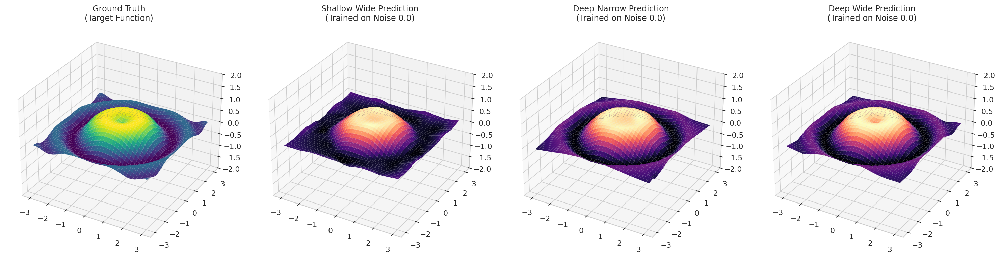

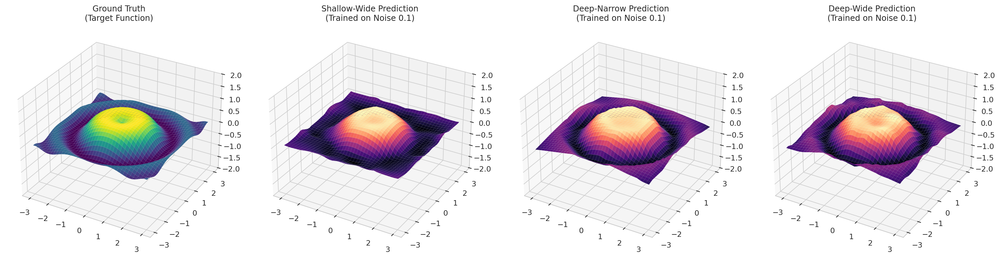

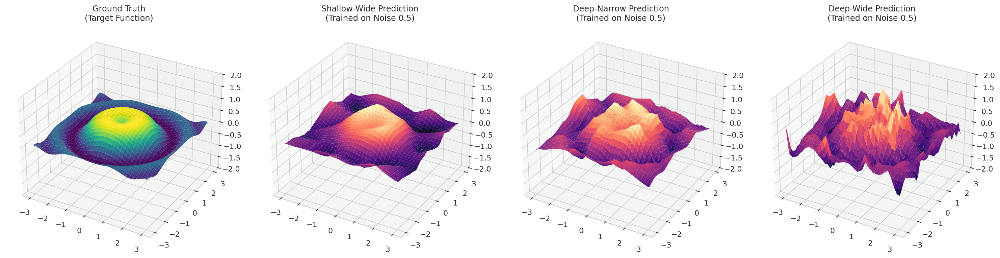

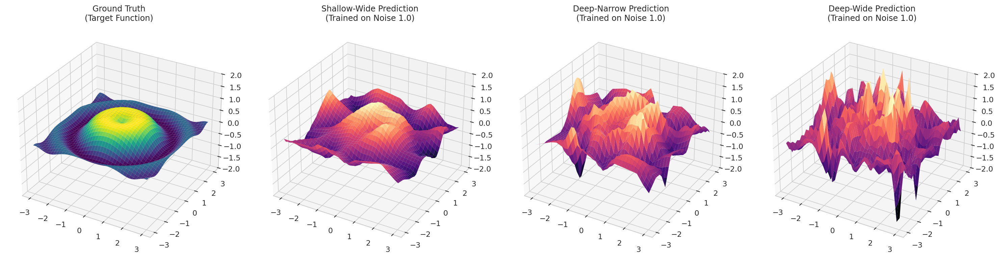

In [ ]:
for noise in noise_levels:

    x_mesh, y_mesh, z_true, z_noisy = meshes

    # Create a dynamic figure size based on the number of architectures + 1 (for Ground Truth)
    num_plots = len(architectures) + 1
    fig = plt.figure(figsize=(5 * num_plots, 5))

    # Plot 1: The True Function
    ax_true = fig.add_subplot(1, num_plots, 1, projection='3d')
    ax_true.plot_surface(x_mesh.numpy(), y_mesh.numpy(), z_true.numpy(), cmap='viridis', edgecolor='none')
    ax_true.set_title("Ground Truth\n(Target Function)")
    ax_true.set_zlim(-2, 2)

    for idx, name in enumerate(architectures.keys()):
        ax = fig.add_subplot(1, num_plots, idx + 2, projection='3d')
        preds = results[noise][name]['preds']

        ax.plot_surface(x_mesh.numpy(), y_mesh.numpy(), preds.numpy(), cmap='magma', edgecolor='none')
        ax.set_zlim(-2, 2)
        ax.set_title(f"{name} Prediction\n(Trained on Noise {noise})")

    plt.tight_layout()
    plt.show()


--- Train vs Val Curve (Deep-Narrow, Noise 0.5) ---


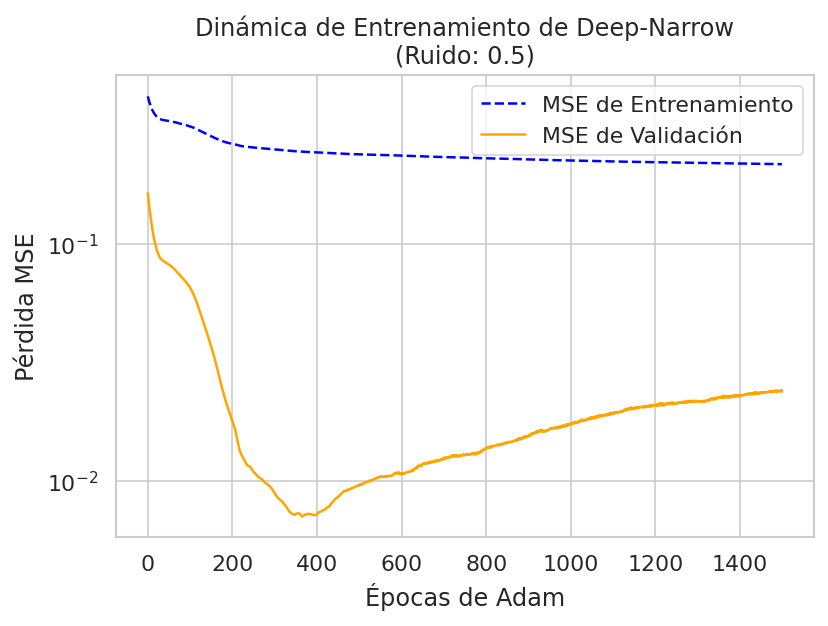


--- Loss vs Epochs Alone (Noise 0.5) ---


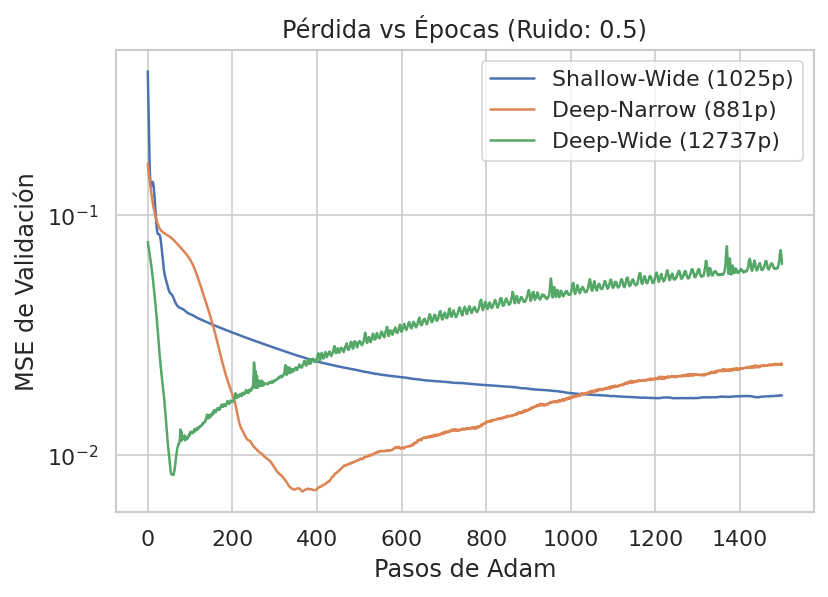


--- Loss vs Time Alone (Noise 0.5) ---


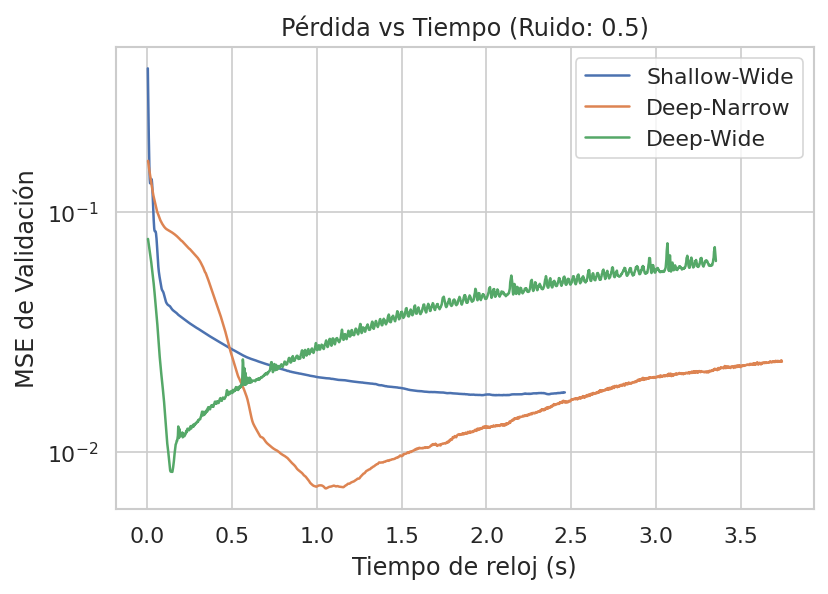


--- Single Model Prediction (Shallow-Wide, Noise 0.5) ---


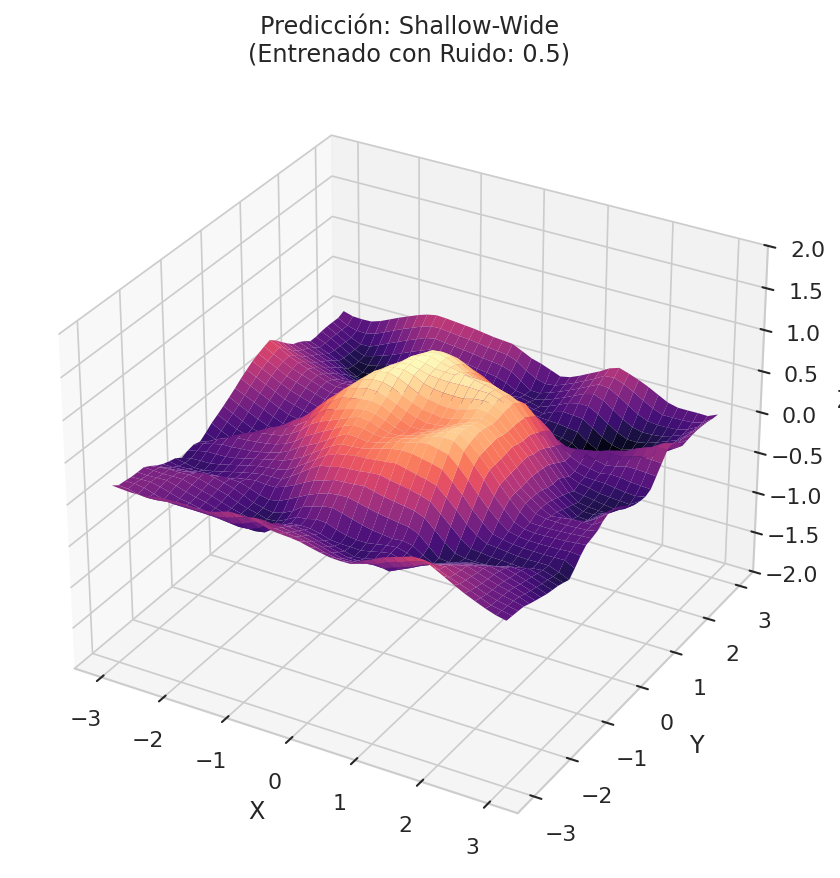


--- Single Model Prediction (Deep-Narrow, Noise 0.5) ---


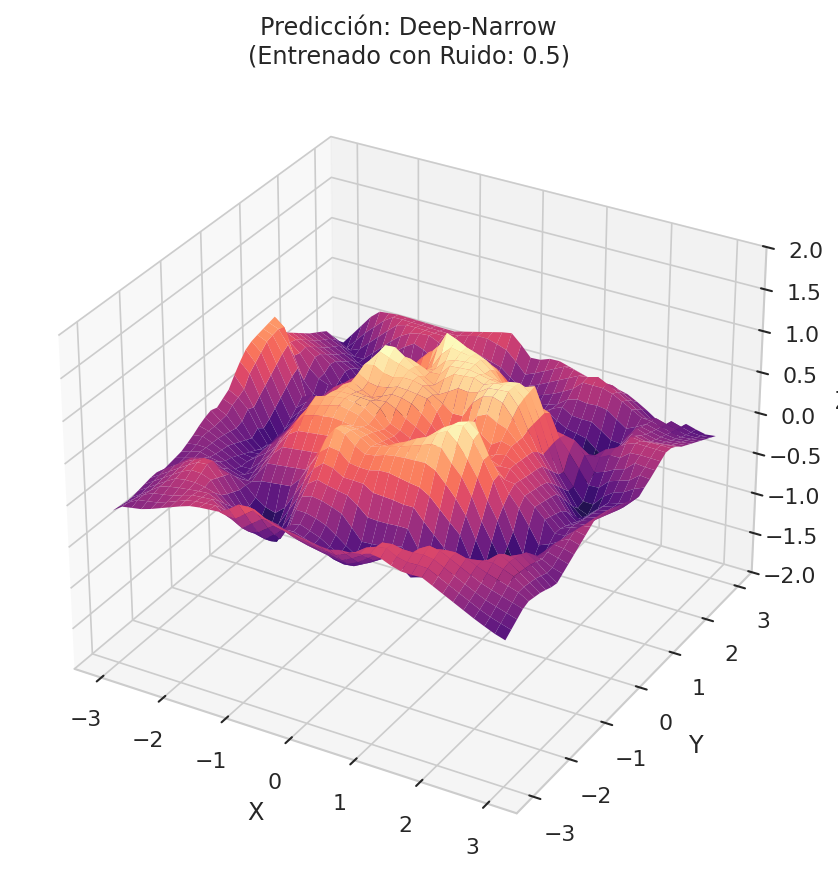

In [ ]:
# INDIVIDUAL ANALYSIS FOR A SPECIFIC NOISE LEVEL (e.g., 0.5)
target_noise = 0.5

# 2. Plot ONLY Train vs Validation curve for ONE model
print(f"\n--- Train vs Val Curve (Deep-Narrow, Noise {target_noise}) ---")
plot_train_val_curves(results, noise=target_noise, model_name="Deep-Narrow")

# 3. Plot ONLY Loss vs Epochs
print(f"\n--- Loss vs Epochs Alone (Noise {target_noise}) ---")
plot_loss_vs_epochs(results, noise=target_noise, architectures=architectures)

# 4. Plot ONLY Loss vs Wall-clock Time
print(f"\n--- Loss vs Time Alone (Noise {target_noise}) ---")
plot_loss_vs_time(results, noise=target_noise, architectures=architectures)

# 5. Plot ONLY ONE model's 3D prediction
print(f"\n--- Single Model Prediction (Shallow-Wide, Noise {target_noise}) ---")
plot_single_model_prediction(results, noise=target_noise, model_name="Shallow-Wide", meshes=meshes)

print(f"\n--- Single Model Prediction (Deep-Narrow, Noise {target_noise}) ---")
plot_single_model_prediction(results, noise=target_noise, model_name="Deep-Narrow", meshes=meshes)

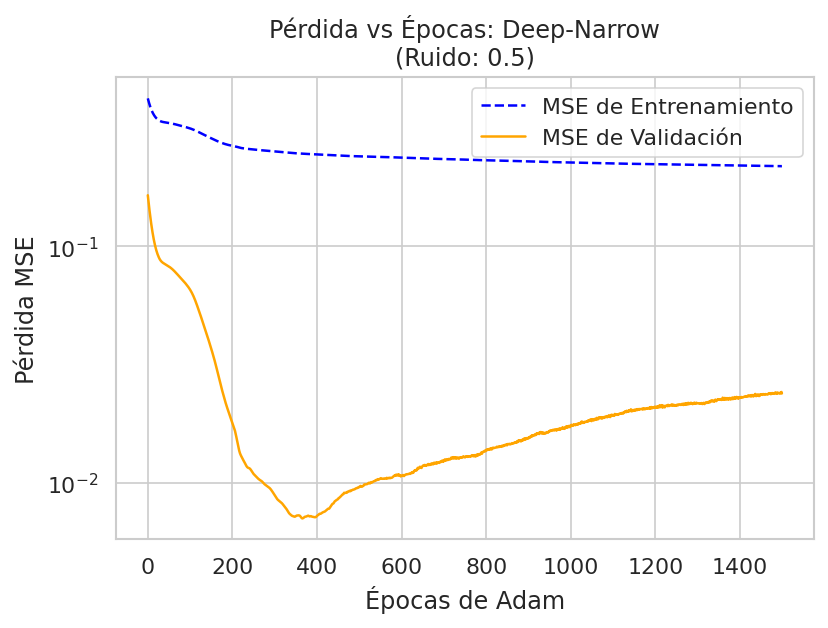

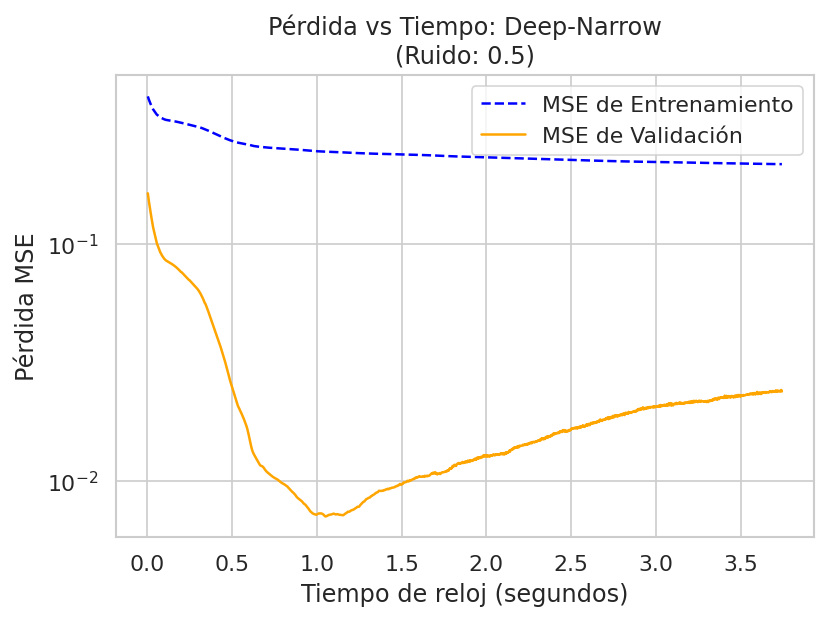


--- Side-by-Side: Epochs vs Time for Deep-Narrow ---


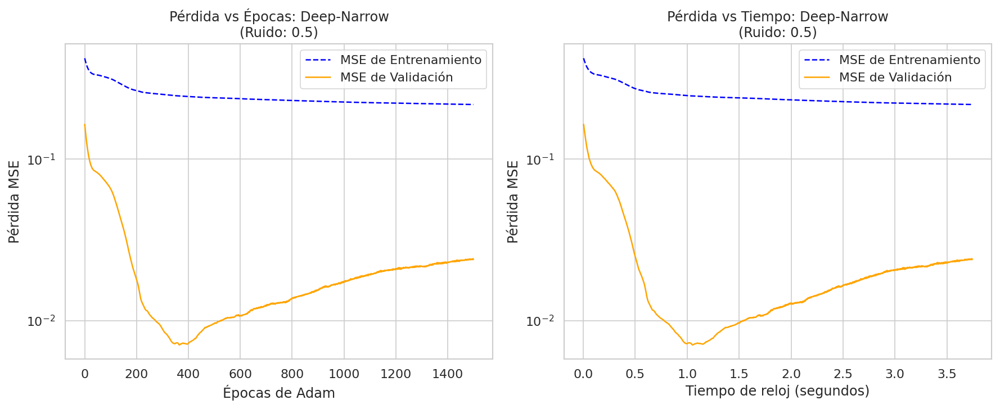

In [ ]:
# INDIVIDUAL ANALYSIS FOR A SPECIFIC NOISE LEVEL (e.g., 0.5)
model_to_analyze = "Deep-Narrow"

# Run Training (Assuming this has already been executed)
# results, meshes = run_capacity_experiment(architectures, noise_levels, steps=1500, lr=0.01)

# 1. Plot Loss vs Epochs for ONE model
plot_single_model_loss_vs_epochs(results, noise=target_noise, model_name=model_to_analyze)

# 2. Plot Loss vs Wall-clock Time for ONE model
plot_single_model_loss_vs_time(results, noise=target_noise, model_name=model_to_analyze)

# Put them side-by-side for direct comparison
print(f"\n--- Side-by-Side: Epochs vs Time for {model_to_analyze} ---")
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

plot_single_model_loss_vs_epochs(results, noise=target_noise, model_name=model_to_analyze, ax=axes[0])
plot_single_model_loss_vs_time(results, noise=target_noise, model_name=model_to_analyze, ax=axes[1])

plt.tight_layout()
plt.show()